# Πρόβλεψη κίνησης κινητού δικτύου: Telecom Italia, Μιλάνο (grid 5060)

#### Το τηλεπικοινωνιακό πρόβλημα

Η **πρόβλεψη φορτίου κίνησης** (traffic load forecasting) εκτιμά τον μελλοντικό όγκο δραστηριότητας (δεδομένα,
κλήσεις, μηνύματα) σε μια κυψέλη ή γεωγραφική περιοχή, με βάση το ιστορικό της. Στα δίκτυα 5G, και ακόμη περισσότερο
στα 6G, η διαχείριση πόρων γίνεται **προληπτικά** (proactive) και όχι **αντιδραστικά** (reactive). Η αντιδραστική
διαχείριση δρα αφού η συμφόρηση ή η υποβάθμιση της ποιότητας υπηρεσίας (QoS) έχει ήδη εμφανιστεί. Αν αντίθετα το
δίκτυο ξέρει ότι σε 10 έως 50 λεπτά η ζήτηση σε μια κυψέλη θα αυξηθεί, μπορεί έγκαιρα να:

* δεσμεύσει φάσμα (PRBs, carrier aggregation) ή να ενεργοποιήσει small cells που ήταν σε κατάσταση ύπνου,
* κλιμακώσει τις εικονικές λειτουργίες δικτύου (UPF στο core, CU/DU του vRAN) και τους πόρους του edge (MEC),
* μοιράσει τη χωρητικότητα ανάμεσα στα network slices (eMBB, URLLC, mMTC),
* μεταφέρει φορτίο σε γειτονικές κυψέλες (mobility load balancing).

Αντίστροφα, όταν προβλέπεται χαμηλό φορτίο (π.χ. τη νύχτα), μπορεί να **απελευθερώσει πόρους** και να
απενεργοποιήσει εξοπλισμό για εξοικονόμηση ενέργειας, με ασφάλεια, γιατί η πρόβλεψη θα προειδοποιήσει έγκαιρα για την
επόμενη άνοδο.

**Η σχέση με το ZSM.** Το **Zero-touch network and Service Management (ZSM)** του ETSI ορίζει μια αρχιτεκτονική
πλήρως αυτοματοποιημένης διαχείρισης δικτύου, χωρίς ανθρώπινη παρέμβαση. Ο βασικός μηχανισμός του είναι ο **κλειστός
βρόχος** (closed loop): *παρακολούθηση* (monitor) → *ανάλυση* (analyze) → *απόφαση* (decide) → *εκτέλεση* (execute),
και ξανά από την αρχή. Η πρόβλεψη κίνησης είναι ο πυρήνας του σταδίου της ανάλυσης: μετατρέπει τις μετρήσεις του
παρελθόντος σε εκτίμηση του μέλλοντος, και πάνω σε αυτή το στάδιο της απόφασης ενεργεί αυτόματα. Χωρίς αξιόπιστη
πρόβλεψη ο βρόχος μπορεί μόνο να αντιδρά, άρα το ZSM δεν μπορεί να είναι προληπτικό. Αντίστοιχο ρόλο έχει η NWDAF στο
5G core (3GPP TS 23.288) και ο RAN Intelligent Controller (RIC) στην αρχιτεκτονική O-RAN. Η ενορχήστρωση σε πραγματικό
δίκτυο συζητείται στην ενότητα 6.

Εδώ προβλέπουμε:

* **short-term:** ένα βήμα μπροστά, $h = 1$ (10 λεπτά),
* **long-term:** πέντε βήματα μπροστά, $H = 5$ (50 λεπτά).

#### Experimental setting: πώς προέκυψαν τα δεδομένα

Τα δεδομένα δημοσιεύτηκαν από την Telecom Italia για το *Big Data Challenge 2014* και περιγράφονται στο άρθρο των
Barlacchi et al. (*Scientific Data*, 2015). Καλύπτουν το διάστημα 1 Νοεμβρίου 2013 έως 1 Ιανουαρίου 2014 (62 ημέρες).

* **Πηγή: Call Detail Records (CDRs).** Το δίκτυο του παρόχου καταγράφει ένα CDR για κάθε αλληλεπίδραση ενός χρήστη
  με το δίκτυο:
  * **SMS:** ένα CDR για κάθε SMS που στέλνεται (*SMS-out*) ή λαμβάνεται (*SMS-in*),
  * **κλήσεις:** ένα CDR για κάθε κλήση που ξεκινά (*Call-out*) ή λαμβάνεται (*Call-in*),
  * **Internet:** ένα CDR όταν ξεκινά ή τελειώνει μια σύνδεση δεδομένων, και επιπλέον ένα κάθε φορά που, κατά τη
    διάρκεια της ίδιας σύνδεσης, περνούν 15 λεπτά ή μεταφέρονται 5 MB από το προηγούμενο CDR.
* **Χωρική συνάθροιση.** Το Μιλάνο χωρίζεται σε πλέγμα $100 \times 100$ τετραγώνων (περίπου $235 \times 235$ m).
  Κάθε CDR ανήκει στην κεραία (RBS) που εξυπηρέτησε τον χρήστη, και κατανέμεται στα τετράγωνα που καλύπτει η κεραία,
  αναλογικά με την επικάλυψη της περιοχής κάλυψης με κάθε τετράγωνο. Το «τετράγωνο» δεν είναι λοιπόν μια κυψέλη,
  αλλά μια σταθερή γεωγραφική μονάδα, ανεξάρτητη από τη διάταξη των κεραιών.
* **Χρονική συνάθροιση:** η δραστηριότητα αθροίζεται σε **δεκάλεπτα**.
* **Ανωνυμοποίηση.** Οι τιμές **δεν είναι πλήθη CDRs ούτε bytes**: έχουν πολλαπλασιαστεί με μια άγνωστη σταθερά $k$,
  ώστε να μην αποκαλύπτεται ο πραγματικός όγκος. Είναι **σχετικοί δείκτες δραστηριότητας** (activity levels),
  συγκρίσιμοι στον χρόνο και στον χώρο, αλλά χωρίς φυσική μονάδα. Αυτό επηρεάζει την ερμηνεία των μετρικών σφάλματος
  (ενότητες 2.8 και 5).

**Οι μεταβλητές.** Κάθε γραμμή των αρχείων αντιστοιχεί σε ένα τετράγωνο, ένα δεκάλεπτο και έναν κωδικό χώρας:

| Μεταβλητή | Σημασία |
|:---|:---|
| `square_id` | το τετράγωνο του πλέγματος (1 έως 10000) |
| `time_interval` | αρχή του δεκαλέπτου, epoch σε ms (UTC) |
| `country_code` | ο κωδικός χώρας της SIM του χρήστη: 39 η Ιταλία, άλλος κωδικός ξένη SIM (roaming), 0 άγνωστος |
| `sms_in`, `sms_out` | δραστηριότητα εισερχόμενων και εξερχόμενων SMS |
| `call_in`, `call_out` | δραστηριότητα εισερχόμενων και εξερχόμενων κλήσεων |
| `internet` | δραστηριότητα δεδομένων (Internet) |

Κενό πεδίο σημαίνει ότι δεν καταγράφηκε δραστηριότητα. Από αυτές σχηματίζουμε τις τρεις σειρές που ζητούνται:
Internet, SMS $=$ SMS-in $+$ SMS-out, και Calls $=$ Call-in $+$ Call-out.

**Γιατί το τετράγωνο 5060.** Καλύπτει την περιοχή του Duomo και της Galleria Vittorio Emanuele II, το πιο τουριστικό
και εμπορικό σημείο της πόλης. Περιμένουμε έντονη δραστηριότητα, καθαρή ημερήσια και εβδομαδιαία περιοδικότητα και
αισθητή επίδραση των εορτών, δηλαδή ένα ρεαλιστικό αλλά απαιτητικό σενάριο πρόβλεψης.

**Δομή του notebook.**
1. Δεδομένα: απομόνωση του τετραγώνου, σχηματισμός των χρονοσειρών, διαχωρισμός train/test, διερευνητική ανάλυση.
2. ARIMA, s-ARIMA, ARIMA-x: θεωρία, εκτίμηση των υπερπαραμέτρων $d, p, q$ (και $D, P, Q$), εκτίμηση των μοντέλων,
   rolling-window πρόβλεψη και αποτίμηση.
3. Deep learning (LSTM): θεωρία, κανονικοποίηση, από-περιοδικοποίηση, εκπαίδευση, ίδια αποτίμηση και
   σύγκριση με την ARIMA.
4. Foundation model (TimesFM 3.0): θεωρία, zero-shot και fine-tuning, αποτίμηση.
5. Συγκριτική αποτίμηση όλων των μοντέλων: RMSE, MAE, MAPE, MASE, απεικονίσεις, κριτήρια επιτυχίας, διαστήματα
   πρόβλεψης 95%.
6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε δίκτυο 6G πραγματικού χρόνου, χρόνοι inference.

## 1. Δεδομένα

### 1.1 Απομόνωση του τετραγώνου 5060

Εκτελούμε πρώτα `python download_dataset.py` από τον φάκελο του project. Το script διαβάζει τα 62 ημερήσια
αρχεία ως streams, επαληθεύει τα checksums τους και κρατά μόνο το grid 5060 στο `data/grid5060_rows.tsv`.
Δεν αποθηκεύει όλα τα δεδομένα της πόλης, αλλά η πρώτη λήψη εξακολουθεί να μεταφέρει περίπου 21 GB.
Το `--workers N` ρυθμίζει τις παράλληλες λήψεις. Η επανεκτέλεση επαναχρησιμοποιεί τις επαληθευμένες ημέρες.

Το επόμενο κελί επαναχρησιμοποιεί το έτοιμο TSV και ελέγχει το hash του, όταν υπάρχει manifest.
Υποστηρίζει επίσης εξαγωγή από πλήρη αρχεία στο `data/full`, αν είχαν ληφθεί με `--full`.


In [ ]:
from download_dataset import prepare_grid_input

grid_path = prepare_grid_input()
with grid_path.open("rb") as source:
    print(f"{sum(1 for _ in source):,} rows in {grid_path}")

In [2]:
import pandas as pd

### 1.2 Σχηματισμός των χρονοσειρών και έλεγχος missing values

Τα βήματα του επόμενου κελιού, και γιατί γίνεται το καθένα:

1. **Κενά πεδία σε 0.** Το dataset παραλείπει τις τιμές όταν δεν υπήρξε δραστηριότητα, οπότε ένα κενό πεδίο σημαίνει
   «καμία δραστηριότητα» και όχι «άγνωστη τιμή». Η αντικατάσταση με 0 είναι επομένως η σωστή ερμηνεία, όχι μια
   υπόθεση.
2. **Χρόνος σε τοπική ώρα Μιλάνου.** Το `time_ms` είναι epoch σε milliseconds (UTC). Το μετατρέπουμε σε ώρα
   `Europe/Rome`, ώστε το ημερήσιο μοτίβο να ευθυγραμμίζεται με το τοπικό ρολόι (π.χ. η αιχμή του μεσημεριού να
   εμφανίζεται στις 13:00 και όχι στις 12:00). Η θερινή ώρα έληξε στις 27/10/2013, άρα μέσα στο διάστημά μας δεν
   υπάρχει αλλαγή ώρας και επομένως ούτε διπλές ή χαμένες ώρες.
3. **Άθροιση πάνω σε όλα τα country codes.** Για κάθε δεκάλεπτο υπάρχει μία γραμμή ανά country code. Μας ενδιαφέρει
   το **συνολικό** φορτίο της κυψέλης, ανεξάρτητα από την προέλευση της SIM, γιατί αυτό καθορίζει τους πόρους που
   χρειάζονται. Σχηματίζουμε τρεις σειρές:

$$\text{Internet}_t, \qquad \text{SMS}_t = \text{SMS}^{\text{in}}_t + \text{SMS}^{\text{out}}_t, \qquad \text{Calls}_t = \text{Call}^{\text{in}}_t + \text{Call}^{\text{out}}_t$$

4. **Έλεγχος missing values σε διάφορες αναλύσεις.** Μετράμε πόσα διαστήματα των 10, 20, 30 και 60 λεπτών δεν έχουν
   **καμία** εγγραφή. Αν η ανάλυση των 10 λεπτών είχε κενά, μια πιο αραιή ανάλυση θα μπορούσε να τα καλύψει. Το
   αποτέλεσμα είναι **0 κενά σε όλες τις αναλύσεις**, άρα κρατάμε τα 10 λεπτά: είναι η πιο λεπτομερής ανάλυση που
   δίνουν τα δεδομένα και ταιριάζει ακριβώς με τον ορίζοντα $h = 1$ (10 λεπτά).
5. **`resample("10min").sum()`.** Εγγυάται ένα κανονικό χρονικό πλέγμα (ένα σημείο ανά δεκάλεπτο, χωρίς κενά ή
   διπλότυπα), κάτι που απαιτούν όλα τα μοντέλα χρονοσειρών: η υστέρηση «1 βήμα» πρέπει να σημαίνει πάντα 10 λεπτά.

In [3]:
# Read TSV file
cols = ["square_id", "time_ms", "country_code", "sms_in", "sms_out", "call_in", "call_out", "internet"]
raw = pd.read_csv("data/grid5060_rows.tsv", sep="\t", header=None, names=cols)

# Convert time and replace NaNs
act = ["sms_in", "sms_out", "call_in", "call_out", "internet"]
raw[act] = raw[act].fillna(0.0)                       # empty field = no activity
raw["time"] = pd.to_datetime(raw["time_ms"], unit="ms", utc=True).dt.tz_convert("Europe/Rome").dt.tz_localize(None)
raw.head()

# Produce internet, sms and calls series
g = raw.groupby("time")[act].sum()                     # sum over all country codes
df = pd.DataFrame({"internet": g["internet"],
                   "sms": g["sms_in"] + g["sms_out"],
                   "calls": g["call_in"] + g["call_out"]})

# missing-value check at several resolutions: count intervals with no data at all
start, end = df.index.min().normalize(), df.index.max().normalize() + pd.Timedelta("1D")
for res in ["10min", "20min", "30min", "1h"]:
    full = pd.date_range(start, end, freq=res, inclusive="left")
    counts = df.resample(res).size().reindex(full, fill_value=0)
    print(res, len(full), "timestamps,", (counts == 0).sum(), "missing")

df = df.resample("10min").sum()
df.head()

10min 8928 timestamps, 0 missing
20min 4464 timestamps, 0 missing
30min 2976 timestamps, 0 missing
1h 1488 timestamps, 0 missing


,internet,sms,calls
time,,,
2013-11-01 00:00:00,392.178279,17.557269,18.132743
2013-11-01 00:10:00,402.885548,50.770405,15.653305
2013-11-01 00:20:00,350.060713,25.363502,12.460866
2013-11-01 00:30:00,427.730728,10.329996,23.500200
2013-11-01 00:40:00,434.044619,19.226668,12.441366


### 1.3 Διαχωρισμός train / test

Το test set είναι το **τελευταίο τέταρτο** της σειράς, στρογγυλεμένο σε ολόκληρες ημέρες. Γιατί έτσι:

* **Χρονολογικός διαχωρισμός, όχι τυχαίος.** Σε χρονοσειρές το μοντέλο πρέπει να αξιολογείται όπως θα
  χρησιμοποιηθεί: εκπαιδεύεται στο παρελθόν και προβλέπει το μέλλον. Ένας τυχαίος διαχωρισμός θα έβαζε μελλοντικές
  τιμές στο train και θα έδινε υπερβολικά αισιόδοξα αποτελέσματα (διαρροή πληροφορίας, *data leakage*).
* **Ολόκληρες ημέρες.** Το test ξεκινά στα μεσάνυχτα, οπότε περιέχει πλήρεις ημερήσιους κύκλους και το train
  τελειώνει επίσης σε πλήρη ημέρα. Έτσι τα εποχικά μοντέλα ($s = 144$) βλέπουν ολόκληρες περιόδους.
* **Περίπου 1/4.** Η εκφώνηση προτείνει 1/3 ή 1/4. Με 1/4 το train έχει 46 ημέρες (6624 σημεία), αρκετές για να
  εκτιμηθεί αξιόπιστα το ημερήσιο και το εβδομαδιαίο μοτίβο, και το test έχει 16 ημέρες (2304 σημεία), αρκετές για
  σταθερές μετρικές.

**Συνέπεια.** Το test καλύπτει το διάστημα 17/12/2013 έως 01/01/2014, δηλαδή τα Χριστούγεννα και την Πρωτοχρονιά,
ενώ το train (01/11 έως 16/12) δεν περιέχει καμία παρόμοια περίοδο. Αυτό κάνει το test **ιδιαίτερα απαιτητικό**, όπως
θα φανεί στην EDA και στα αποτελέσματα.

In [4]:
TEST_FRAC = 0.25
SEASON = 144 # 1 day = 144*10 minutes
SERIES = ["internet", "sms", "calls"]

N = len(df)
n_test = int(round(N * TEST_FRAC / SEASON)) * SEASON       # the test set starts at midnight
n_train = N - n_test
print(f"N = {N}, train = {n_train}, test = {n_test}")

N = 8928, train = 6624, test = 2304


### 1.4 Διερευνητική ανάλυση (EDA)

**Γιατί EDA πριν από τα μοντέλα.** Οι επιλογές που θα κάνουμε στην ενότητα 2 (εποχική περίοδος $s$, εξωγενείς
μεταβλητές, ποιες ημέρες χρειάζονται ειδική μεταχείριση) πρέπει να στηρίζονται σε αυτό που δείχνουν τα δεδομένα. Η
EDA απαντά σε τέσσερα ερωτήματα: υπάρχει περιοδικότητα και ποια; διαφέρουν οι εργάσιμες από τα Σαββατοκύριακα;
υπάρχουν ανωμαλίες (αργίες, αιχμές); πόσο μοιάζουν οι τρεις σειρές μεταξύ τους;

Το πρώτο κελί ορίζει:
* τις **αργίες** του διαστήματος: Αγίων Πάντων (1/11), Sant'Ambrogio (7/12, πολιούχος του Μιλάνου, τοπική αργία),
  Αμόλυντος Σύλληψη (8/12), Χριστούγεννα (25/12), Santo Stefano (26/12), Πρωτοχρονιά (1/1),
* τη συνάρτηση `day_type`, που χωρίζει τις ημέρες σε τρεις κατηγορίες: εργάσιμη, Σάββατο, Κυριακή ή αργία. Οι αργίες
  μπαίνουν μαζί με τις Κυριακές, γιατί η συμπεριφορά των ανθρώπων (κλειστά γραφεία, βόλτα στο κέντρο) είναι παρόμοια.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

COLOR = {"internet": "#2a78d6", "sms": "#eb6834", "calls": "#1baf7a"}
# All Saints, Sant'Ambrogio (Milan), Immaculate Conception, Christmas, St Stephen, New Year
HOLIDAYS = pd.to_datetime(["2013-11-01", "2013-12-07", "2013-12-08", "2013-12-25", "2013-12-26", "2014-01-01"])

def day_type(idx):
    """0 = working day, 1 = Saturday, 2 = Sunday / holiday"""
    t = np.where(idx.dayofweek == 5, 1, 0)
    return np.where((idx.dayofweek == 6) | idx.normalize().isin(HOLIDAYS), 2, t)

train, test = df.iloc[:n_train], df.iloc[n_train:]
t_split = test.index[0]
print(f"train {train.index[0]} -> {train.index[-1]}")
print(f"test  {test.index[0]} -> {test.index[-1]}")

train 2013-11-01 00:00:00 -> 2013-12-16 23:50:00
test  2013-12-17 00:00:00 -> 2014-01-01 23:50:00


**Ολόκληρη η σειρά.** Με γκρι σκιάζονται τα Σαββατοκύριακα και οι αργίες, και η διακεκομμένη γραμμή δείχνει την
αρχή του test set. Εδώ ψάχνουμε την τάση (υπάρχει ή όχι), τον εβδομαδιαίο ρυθμό και τυχόν ασυνήθιστες ημέρες.

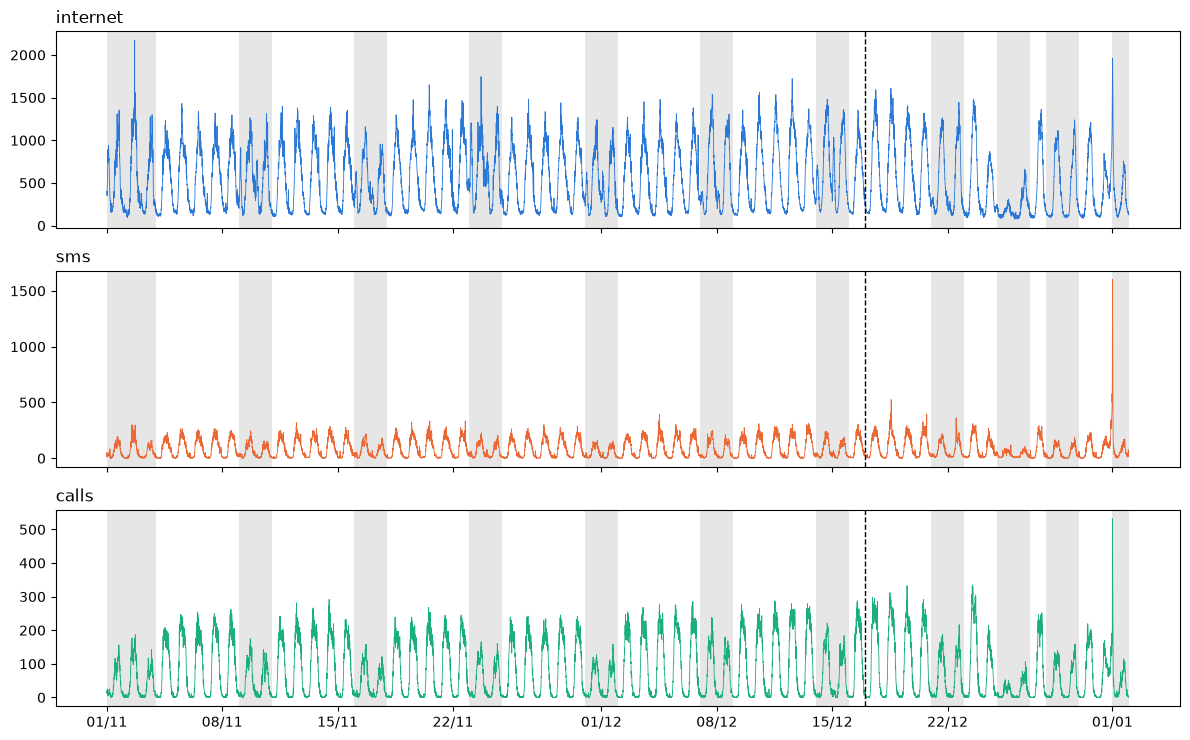

In [6]:
# Full series, weekends/holidays shaded, dashed line = start of test set
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(df.index, df[s], color=COLOR[s], lw=0.6)
    for d in pd.date_range(df.index[0].normalize(), df.index[-1].normalize(), freq="D"):
        if d.dayofweek >= 5 or d in HOLIDAYS:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="0.9", lw=0)
    ax.axvline(t_split, color="k", ls="--", lw=1)
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

**Μία τυπική εβδομάδα** (Δευτέρα 11/11 έως Κυριακή 17/11/2013). Σε αυτή την κλίμακα φαίνεται καθαρά το σχήμα του
ημερήσιου κύκλου και η διαφορά εργάσιμης και Σαββατοκύριακου.

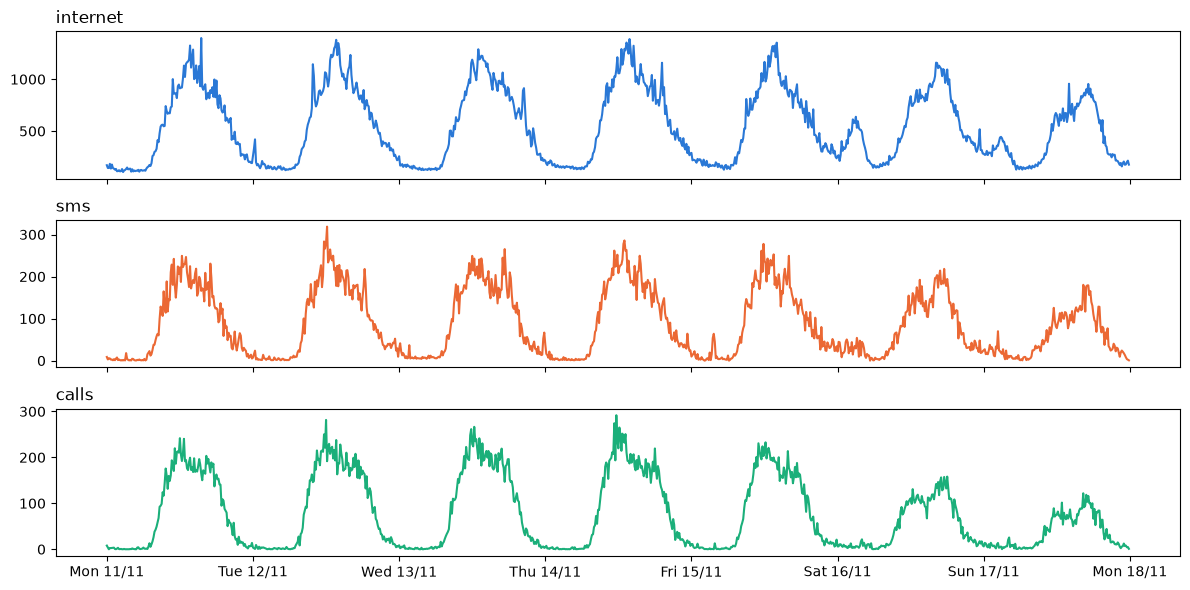

In [7]:
# One typical week
week = df.loc["2013-11-11":"2013-11-17"]
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(week.index, week[s], color=COLOR[s])
    ax.set_title(s, loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d/%m"))
fig.tight_layout(); plt.show()

**Μέσο ημερήσιο προφίλ ανά τύπο ημέρας.** Για κάθε δεκάλεπτο της ημέρας (slot 0 έως 143) υπολογίζουμε τη μέση τιμή,
χωριστά για εργάσιμες, Σάββατα και Κυριακές ή αργίες. Χρησιμοποιούμε **μόνο το train**, γιατί αυτά τα προφίλ
καθοδηγούν την επιλογή μοντέλου και δεν πρέπει να «δουν» το test.

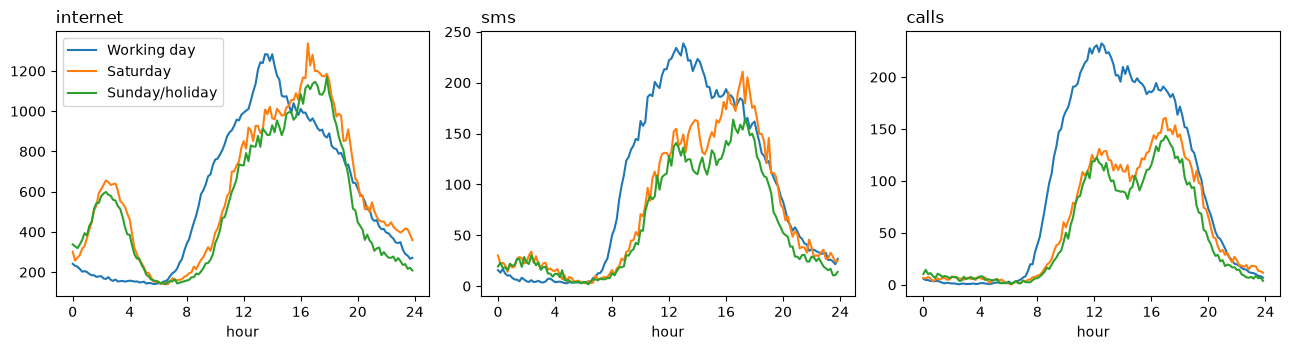

In [8]:
# Mean daily profile per day type (train set only)
tr = train.copy()
tr["slot"] = tr.index.hour * 6 + tr.index.minute // 10
tr["type"] = day_type(tr.index)
names = {0: "Working day", 1: "Saturday", 2: "Sunday/holiday"}
hours = np.arange(SEASON) / 6
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, SERIES):
    for k in range(3):
        ax.plot(hours, tr[tr["type"] == k].groupby("slot")[s].mean().values, label=names[k])
    ax.set_title(s, loc="left"); ax.set_xlabel("hour"); ax.set_xticks(range(0, 25, 4))
axes[0].legend()
fig.tight_layout(); plt.show()

**Ημερήσια σύνολα.** Αθροίζοντας ανά ημέρα εξαφανίζεται ο ημερήσιος κύκλος και μένει ο εβδομαδιαίος ρυθμός και οι
ειδικές ημέρες (γκρι: Σαββατοκύριακα και αργίες).

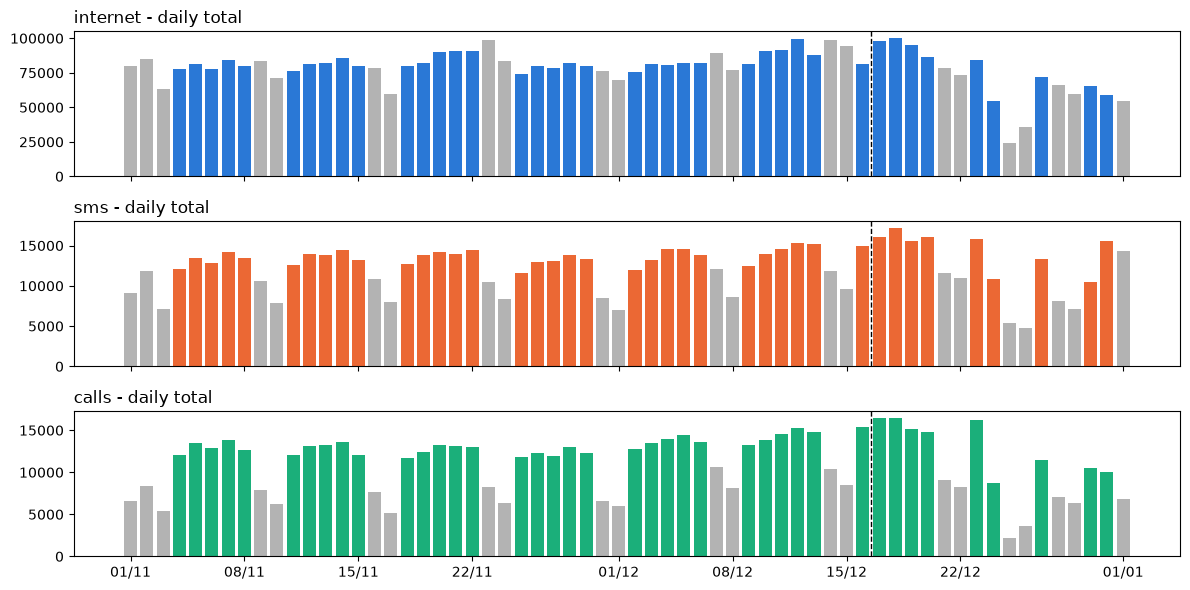

In [9]:
# Daily totals (grey = weekend/holiday)
daily = df.resample("D").sum()
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, s in zip(axes, SERIES):
    c = ["0.7" if (d.dayofweek >= 5 or d in HOLIDAYS) else COLOR[s] for d in daily.index]
    ax.bar(daily.index, daily[s], color=c, width=0.8)
    ax.axvline(t_split - pd.Timedelta("12h"), color="k", ls="--", lw=1)
    ax.set_title(s + " - daily total", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

**Περιγραφικά στατιστικά και συσχέτιση.** Η συσχέτιση Pearson δείχνει αν οι τρεις σειρές οδηγούνται από τον ίδιο
παράγοντα.

In [10]:
# Summary statistics and correlation between the three series
display(df.describe().T)
df.corr().round(3)

,count,mean,std,min,25%,50%,75%,max
internet,8928.0,547.156496,376.406598,77.226475,193.706089,438.280193,864.318821,2172.038157
sms,8928.0,84.817577,85.815283,0.003122,11.842894,52.158589,149.550749,1602.041699
calls,8928.0,76.645422,82.094554,0.000000,4.497874,36.834428,146.385241,531.921029


,internet,sms,calls
internet,1.000,0.879,0.900
sms,0.879,1.000,0.925
calls,0.900,0.925,1.000


**Προέλευση της κίνησης.** Ποσοστό της δραστηριότητας από ιταλικές SIM (country code 39), από SIM με άγνωστο code (0)
και από ξένες SIM. Αυτό μας δείχνει πόσο «τουριστικό» είναι το κελί.

In [11]:
# Share of activity from Italian (39), unknown (0) and foreign SIMs
by_cc = raw.groupby("country_code")[act].sum()
foreign = by_cc.drop(index=[0, 39])
pd.DataFrame({"Italy (39) %": 100 * by_cc.loc[39] / by_cc.sum(),
              "unknown (0) %": 100 * by_cc.loc[0] / by_cc.sum(),
              "foreign %": 100 * foreign.sum() / by_cc.sum()}).round(1)

,Italy (39) %,unknown (0) %,foreign %
sms_in,62.2,31.8,6.0
sms_out,91.5,1.8,6.6
call_in,95.2,0.3,4.4
call_out,95.3,0.9,3.9
internet,98.8,0.0,1.2


**Παρατηρήσεις από την EDA**

* **Ισχυρή ημερήσια περιοδικότητα** και στις τρεις σειρές. Το ελάχιστο εμφανίζεται περίπου 05:00 έως 07:00 και η
  κορυφή τις εργάσιμες γύρω στις 12:30 (Calls), 13:00 (SMS) και 13:30 (Internet). Τη νύχτα οι κλήσεις σχεδόν
  μηδενίζονται: υπάρχουν 200 δεκάλεπτα με Calls $= 0$ στο train και 120 στο test. Το Internet αντίθετα δεν πέφτει
  ποτέ κάτω από περίπου 77, λόγω της συνεχούς background κίνησης των smartphones. **Συνέπεια για τη μοντελοποίηση:**
  εποχική περίοδος $s = 144$ (μία ημέρα).
* **Εβδομαδιαία περιοδικότητα.** Τα Σαββατοκύριακα το ημερήσιο σύνολο πέφτει στο 57% (Calls) και στο 70% (SMS) μιας
  εργάσιμης, ενώ το Internet μένει περίπου ίδιο (98%) αλλά αλλάζει σχήμα. Η κορυφή μετατοπίζεται στο απόγευμα
  (16:30 έως 18:00, βόλτες και ψώνια στο κέντρο). Στις πρώτες ώρες του Σαββάτου και της Κυριακής (01:00 έως 04:00,
  δηλαδή οι νύχτες της Παρασκευής και του Σαββάτου) το Internet είναι περίπου **3 φορές** υψηλότερο από τις
  αντίστοιχες ώρες μιας εργάσιμης (558 έναντι 170): νυχτερινή ζωή γύρω από το Duomo. **Συνέπεια:** ο τύπος ημέρας
  χρειάζεται ως πληροφορία στο μοντέλο, π.χ. ως εξωγενής μεταβλητή.
* **Καμία τάση.** Το επίπεδο της σειράς δεν ανεβαίνει ούτε κατεβαίνει συστηματικά μέσα στους δύο μήνες (εκτός από τις
  γιορτές). Αυτό θα επιβεβαιωθεί τυπικά με τα τεστ στασιμότητας της ενότητας 2.2.
* **Οι τρεις σειρές συσχετίζονται έντονα** (Pearson 0.88 έως 0.93), γιατί οδηγούνται από τον ίδιο παράγοντα: πόσοι
  άνθρωποι βρίσκονται στην περιοχή.
* **Η εορταστική περίοδος πέφτει μέσα στο test.** Σε σχέση με μια μέση εργάσιμη του train, τα Χριστούγεννα (25/12)
  το Internet είναι 71% χαμηλότερο, τα SMS 61% και τα Calls 84%, και στις 26/12 56%, 65% και 73% αντίστοιχα. Τα
  μεσάνυχτα της Πρωτοχρονιάς εμφανίζεται η μεγαλύτερη αιχμή όλης της σειράς: SMS $= 1602$ στις 00:10, ενώ η
  συνήθης τιμή αυτής της ώρας είναι περίπου 18 (σχεδόν 90 φορές μεγαλύτερη), Calls $= 532$ (συνήθως περίπου 7) και
  Internet $= 1964$ (συνήθως περίπου 268). **Τίποτα από αυτά δεν υπάρχει στο train**, οπότε το test ελέγχει πόσο
  καλά προσαρμόζεται κάθε μοντέλο σε συνθήκες που δεν έχει δει (*distribution shift*).
* **Ξένες SIM.** Το 4% έως 7% των SMS και των κλήσεων προέρχεται από ξένες SIM, κάτι που επιβεβαιώνει τον
  τουριστικό χαρακτήρα του κελιού. Στο Internet το ποσοστό είναι μόνο 1.2%, πιθανότατα επειδή το 2013 τα δεδομένα
  σε roaming ήταν ακριβά και οι τουρίστες τα απέφευγαν. Περίπου το 32% των εισερχόμενων SMS έχει άγνωστο country code.
* **Η διακύμανση εξαρτάται από το επίπεδο.** Οι διακυμάνσεις είναι πολύ μεγαλύτερες τη μέρα (υψηλό φορτίο) από τη
  νύχτα. Αυτό λέγεται **ετεροσκεδαστικότητα** και θα το ξαναδούμε στα κατάλοιπα των μοντέλων (ενότητα 2.6).

## 2. ARIMA, s-ARIMA, ARIMA-x

### 2.1 Θεωρία

#### 2.1.1 Στασιμότητα: γιατί είναι η βασική προϋπόθεση

Ένα μοντέλο ARIMA εκτιμά **σταθερές** παραμέτρους από το παρελθόν και τις εφαρμόζει στο μέλλον. Αυτό έχει νόημα μόνο
αν η στατιστική συμπεριφορά της σειράς **δεν αλλάζει με τον χρόνο**. Αυτή η ιδιότητα λέγεται (ασθενής) στασιμότητα.
Μια σειρά $y_t$ είναι στάσιμη όταν:

$$\mathbb{E}[y_t] = \mu \;\;\text{(σταθερός μέσος)}, \qquad \operatorname{Var}(y_t) = \sigma_y^2 \;\;\text{(σταθερή διασπορά)}, \qquad \operatorname{Cov}(y_t,\, y_{t-k}) = \gamma_k \;\;\text{(εξαρτάται μόνο από το } k\text{)}$$

Αν η σειρά έχει τάση ή «περιπλανιέται» χωρίς να επιστρέφει σε ένα μέσο επίπεδο, τότε ο μέσος όρος που θα μάθει το
μοντέλο από το train δεν θα ισχύει στο test.

**Τελεστής υστέρησης.** Για να γράφουμε τα μοντέλα σύντομα χρησιμοποιούμε τον τελεστή $B$, που μετακινεί τη σειρά ένα
βήμα πίσω:

$$B\,y_t = y_{t-1}, \qquad B^k y_t = y_{t-k}$$

Με αυτόν ορίζονται η **διαφόριση** (διαφορά από το προηγούμενο βήμα) και η **εποχική διαφόριση** (διαφορά από το ίδιο
σημείο της προηγούμενης περιόδου $s$):

$$\nabla y_t = (1 - B)\,y_t = y_t - y_{t-1}, \qquad \nabla_s\, y_t = (1 - B^s)\,y_t = y_t - y_{t-s}$$

Η διαφόριση αφαιρεί μια τάση ή μια «περιπλάνηση» και η εποχική διαφόριση αφαιρεί ένα μοτίβο που επαναλαμβάνεται
κάθε $s$ βήματα. Και οι δύο μετατρέπουν μια μη στάσιμη σειρά σε στάσιμη.

#### 2.1.2 Τα δομικά στοιχεία: AR, MA, ARMA

Σε όλα τα παρακάτω, $\varepsilon_t$ είναι **λευκός θόρυβος**: ασυσχέτιστες τυχαίες διαταραχές με μέσο 0 και
διασπορά $\sigma^2$. Είναι το «απρόβλεπτο» μέρος κάθε βήματος.

**AR(p), αυτοπαλινδρόμηση.** Η τρέχουσα τιμή είναι γραμμικός συνδυασμός των $p$ προηγούμενων **τιμών**:

$$y_t = c + \phi_1 y_{t-1} + \phi_2 y_{t-2} + \dots + \phi_p y_{t-p} + \varepsilon_t
\qquad\Longleftrightarrow\qquad
\phi(B)\,y_t = c + \varepsilon_t, \quad \phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p$$

*Διαίσθηση:* η σειρά «θυμάται» πού βρισκόταν. Αν η κίνηση είναι υψηλή τώρα, θα είναι μάλλον υψηλή και σε 10 λεπτά.

**MA(q), κινητός μέσος.** Η τρέχουσα τιμή εξαρτάται από τις $q$ προηγούμενες **διαταραχές** (τα «ξαφνιάσματα»):

$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}
\qquad\Longleftrightarrow\qquad
y_t = \mu + \theta(B)\,\varepsilon_t, \quad \theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q$$

*Διαίσθηση:* ένα απρόσμενο γεγονός (π.χ. ένα πλήθος που φτάνει ξαφνικά) επηρεάζει τα επόμενα $q$ βήματα και μετά
ξεχνιέται εντελώς.

**ARMA(p, q).** Συνδυάζει και τα δύο: $\;\phi(B)\,y_t = c + \theta(B)\,\varepsilon_t$.

**Γιατί ARMA και όχι μόνο AR.** Ένα ARMA χαμηλής τάξης μπορεί να περιγράψει μια μνήμη που θα χρειαζόταν πολύ μεγάλο
AR. Λιγότερες παράμετροι σημαίνουν πιο σταθερή εκτίμηση και μικρότερο κίνδυνο υπερπροσαρμογής (αρχή της φειδωλότητας,
*parsimony*).

**Δύο τεχνικές συνθήκες.** Το AR μέρος πρέπει να είναι **στάσιμο** (οι ρίζες του $\phi(z) = 0$ έξω από τον μοναδιαίο
κύκλο) ώστε οι διαταραχές να σβήνουν με τον χρόνο, και το MA μέρος πρέπει να είναι **αντιστρέψιμο** (οι ρίζες του
$\theta(z) = 0$ έξω από τον μοναδιαίο κύκλο) ώστε τα $\varepsilon_t$ να μπορούν να ανακτηθούν από τις παρατηρήσεις.
Η δεύτερη συνθήκη είναι απαραίτητη για την εκτίμηση που χρησιμοποιούμε στην ενότητα 2.4.

#### 2.1.3 ARIMA(p, d, q)

Αν η $y_t$ δεν είναι στάσιμη, τη διαφορίζουμε $d$ φορές και εφαρμόζουμε ARMA στο αποτέλεσμα. Το «I» (*Integrated*)
δηλώνει ακριβώς αυτό:

$$\phi(B)\,(1 - B)^d\, y_t = c + \theta(B)\,\varepsilon_t$$

Οι τρεις υπερπαράμετροι και πώς εκτιμώνται **a priori**:

| Υπερπαράμετρος | Σημασία | Πώς την εκτιμούμε |
|:---|:---|:---|
| $d$ | πόσες διαφορίσεις χρειάζονται για στασιμότητα | τεστ **ADF** και **KPSS**, και η μορφή της ACF (ενότητα 2.2) |
| $p$ | πόσες προηγούμενες τιμές (AR) | η **PACF** της στάσιμης σειράς (ενότητα 2.3) |
| $q$ | πόσες προηγούμενες διαταραχές (MA) | η **ACF** της στάσιμης σειράς (ενότητα 2.3) |

Οι γραφικές εκτιμήσεις δίνουν ένα εύρος τιμών. Η τελική επιλογή μέσα σε αυτό το εύρος γίνεται με κριτήριο
πληροφορίας (BIC, ενότητα 2.5).

#### 2.1.4 Seasonal ARIMA: s-ARIMA(p, d, q)(P, D, Q)$_s$

Η EDA έδειξε ότι η σειρά επαναλαμβάνεται κάθε $s = 144$ βήματα (μία ημέρα). Ένα απλό ARIMA θα χρειαζόταν όρους μέχρι
το lag 144 για να το περιγράψει. Το s-ARIMA προσθέτει **εποχικά** πολυώνυμα στο $B^s$:

$$\phi(B)\,\Phi(B^s)\,(1 - B)^d\,(1 - B^s)^D\, y_t \;=\; c + \theta(B)\,\Theta(B^s)\,\varepsilon_t$$

* $\Phi(B^s) = 1 - \Phi_1 B^s - \dots - \Phi_P B^{Ps}$ και $\Theta(B^s) = 1 + \Theta_1 B^s + \dots + \Theta_Q B^{Qs}$
  συνδέουν την τιμή με τις τιμές και τις διαταραχές **της ίδιας ώρας τις προηγούμενες ημέρες**.
* $D$ είναι το πλήθος των εποχικών διαφορίσεων. Με $D = 1$ μοντελοποιούμε τη διαφορά
  $\nabla_{144}\, y_t = y_t - y_{t-144}$, δηλαδή «πόσο διαφέρει η κίνηση από χθες την ίδια ώρα». Αυτό αφαιρεί το
  ημερήσιο μοτίβο.
* Το μοντέλο είναι **πολλαπλασιαστικό**: τα γινόμενα όπως $\theta(B)\,\Theta(B^s)$ δημιουργούν όρους αλληλεπίδρασης
  (π.χ. στο lag $s + 1$) με λίγες μόνο παραμέτρους.
* Τα $P, Q$ διαβάζονται από την ACF/PACF στα πολλαπλάσια της περιόδου: lags 144, 288, 432, ...

#### 2.1.5 ARIMA-x: ARIMA με εξωγενείς μεταβλητές

Εδώ η σειρά γράφεται ως παλινδρόμηση σε γνωστές μεταβλητές $x_t$, με σφάλματα που ακολουθούν ARIMA:

$$y_t = c + \beta^\top x_t + u_t, \qquad u_t \sim \text{ARIMA}(p, d, q)$$

Το $\beta^\top x_t$ περιγράφει το **προβλέψιμο, ντετερμινιστικό** μέρος (π.χ. το ημερήσιο σχήμα) και το ARIMA περιγράφει
ό,τι μένει. Ως $x_t$ χρησιμοποιούμε **δείκτες περιοδικότητας**, που έχουν ένα κρίσιμο πλεονέκτημα: είναι **γνωστοί
εκ των προτέρων** για κάθε μελλοντική στιγμή (ξέρουμε τι ώρα και τι μέρα θα είναι), άρα δεν χρειάζεται να τους
προβλέψουμε.

**Όροι Fourier.** Κάθε περιοδική συνάρτηση με περίοδο $m$ γράφεται ως άθροισμα ημιτόνων και συνημιτόνων:

$$\sum_{k=1}^{K} \Big[\, a_k \sin\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) + b_k \cos\!\Big(\frac{2\pi k\, \tau_t}{m}\Big) \Big]$$

όπου $\tau_t$ η θέση του $t$ μέσα στην περίοδο. Χρησιμοποιούμε $m = 144$ (ημερήσιος κύκλος) και $m = 1008$
(εβδομαδιαίος κύκλος, $7 \times 144$). Το $K$ ελέγχει πόσο λεπτομερές είναι το σχήμα: μικρό $K$ δίνει ομαλή καμπύλη.

**Γιατί Fourier και όχι μόνο s-ARIMA.** Ένα s-ARIMA με $s = 1008$ για τον εβδομαδιαίο κύκλο θα ήταν πρακτικά αδύνατο
να εκτιμηθεί (πολυώνυμα βαθμού πάνω από 1000). Οι όροι Fourier περιγράφουν την ίδια περιοδικότητα με λίγες
παραμέτρους ($2K$ ανά περίοδο). Επιπλέον, με έναν δείκτη μη εργάσιμης ημέρας μπορούμε να πούμε στο μοντέλο ότι η
Κυριακή έχει διαφορετικό σχήμα από τη Δευτέρα, κάτι που το s-ARIMA δεν μπορεί να κάνει.

### 2.2 Έλεγχοι στασιμότητας (ADF, KPSS): εκτίμηση του $d$ (και του $D$)

#### Μοναδιαία ρίζα

Η πιο συνηθισμένη μορφή μη στασιμότητας φαίνεται στο απλό μοντέλο

$$y_t = \rho\, y_{t-1} + \varepsilon_t$$

* Αν $|\rho| < 1$, κάθε διαταραχή σβήνει σταδιακά και η σειρά επιστρέφει στον μέσο της: **στάσιμη**.
* Αν $\rho = 1$, κάθε διαταραχή μένει για πάντα και η σειρά περιπλανιέται (*random walk*): **μη στάσιμη**. Αυτό
  λέγεται **μοναδιαία ρίζα** και διορθώνεται με μία διαφόριση, αφού τότε $\nabla y_t = \varepsilon_t$.

Άρα το ερώτημα «χρειάζεται διαφόριση;» είναι ισοδύναμο με το «έχει η σειρά μοναδιαία ρίζα;».

#### ADF (Augmented Dickey-Fuller)

Εκτιμά την παλινδρόμηση

$$\nabla y_t = \alpha + \gamma\, y_{t-1} + \sum_{i=1}^{\ell} \delta_i\, \nabla y_{t-i} + \varepsilon_t$$

όπου $\gamma = \rho - 1$. Οι όροι $\nabla y_{t-i}$ (το «augmented») απορροφούν τη βραχυπρόθεσμη αυτοσυσχέτιση, ώστε το
τεστ να είναι έγκυρο και όταν η σειρά δεν είναι απλό AR(1). Το πλήθος τους $\ell$ επιλέγεται με AIC.

* **H0: $\gamma = 0$**, δηλαδή υπάρχει μοναδιαία ρίζα (μη στάσιμη).
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι **στάσιμη**.

#### KPSS (Kwiatkowski-Phillips-Schmidt-Shin)

Γράφει τη σειρά ως άθροισμα ενός random walk και ενός στάσιμου μέρους:

$$y_t = r_t + \eta_t, \qquad r_t = r_{t-1} + v_t, \quad \operatorname{Var}(v_t) = \sigma_v^2$$

* **H0: $\sigma_v^2 = 0$**, δηλαδή το random walk είναι σταθερό και η σειρά είναι **στάσιμη**.
* $p < 0.05$: απορρίπτουμε την H0, άρα η σειρά είναι **μη στάσιμη**.

#### Γιατί χρειαζόμαστε και τα δύο

Ένα τεστ υποθέσεων μπορεί μόνο να **απορρίψει** την H0, ποτέ να την αποδείξει. Το ADF μάλιστα έχει μικρή ισχύ: συχνά
δεν απορρίπτει ακόμη και όταν η σειρά είναι στάσιμη. Τα δύο τεστ έχουν **αντίθετες** μηδενικές υποθέσεις, οπότε όταν
συμφωνούν το συμπέρασμα είναι αξιόπιστο:

| ADF $p$ | KPSS $p$ | Συμπέρασμα |
|:---:|:---:|:---|
| $< 0.05$ | $> 0.05$ | **στάσιμη** (συμφωνούν) |
| $> 0.05$ | $< 0.05$ | **μη στάσιμη** (συμφωνούν), χρειάζεται διαφόριση |
| $< 0.05$ | $< 0.05$ | αντικρουόμενα (συχνά στάσιμη γύρω από τάση) |
| $> 0.05$ | $> 0.05$ | ανεπαρκή στοιχεία |

#### Τι ελέγχουμε

Εφαρμόζουμε τα τεστ στην $y_t$, στην $\nabla y_t$, στην $\nabla_{144}\, y_t$ και στην $\nabla \nabla_{144}\, y_t$. Η
**απλούστερη** μορφή που βγαίνει στάσιμη δίνει τα $d$ και $D$. Τα τεστ γίνονται **μόνο στο train set**, ώστε η
επιλογή του μοντέλου να μη «βλέπει» το test.

*Τεχνική σημείωση:* το `statsmodels` δίνει p-values για το KPSS μόνο στο διάστημα $[0.01,\, 0.1]$ (από πίνακα κρίσιμων
τιμών). Μια τιμή 0.1 σημαίνει «0.1 ή μεγαλύτερη».

In [12]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Y = {s: df[s].values.astype(float) for s in SERIES}

def stationarity_table(y):
    ys = pd.Series(y)
    rows = []
    for name, z in {"y": ys, "d1(y)": ys.diff(), "d144(y)": ys.diff(SEASON),
                    "d1(d144(y))": ys.diff(SEASON).diff()}.items():
        z = z.dropna().values
        with warnings.catch_warnings():         # FutureWarnings + KPSS p-value outside the lookup table
            warnings.simplefilter("ignore")
            adf_stat, adf_p, *_ = adfuller(z, autolag="AIC")
            kpss_stat, kpss_p, *_ = kpss(z, regression="c", nlags="auto")
        rows.append({"series": name, "ADF stat": adf_stat, "ADF p": adf_p,
                     "KPSS stat": kpss_stat, "KPSS p": kpss_p,
                     "conclusion": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else
                                   ("ambiguous" if (adf_p < 0.05) == (kpss_p < 0.05) else "non-stationary")})
    return pd.DataFrame(rows)


for s in SERIES:
    print(f"\n=== {s} ===  (KPSS p-values are bounded to [0.01, 0.1])")
    display(stationarity_table(Y[s][:n_train]))


=== internet ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.988509,8.904673e-30,0.111048,0.1,stationary
1,d1(y),-13.407905,4.432758e-25,0.003744,0.1,stationary
2,d144(y),-12.733859,9.250838e-24,0.017651,0.1,stationary
3,d1(d144(y)),-16.435145,2.457400e-29,0.003739,0.1,stationary



=== sms ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.220950,3.898405e-29,0.053198,0.1,stationary
1,d1(y),-14.287563,1.292081e-26,0.007418,0.1,stationary
2,d144(y),-9.587682,2.076050e-16,0.029130,0.1,stationary
3,d1(d144(y)),-27.418437,0.000000e+00,0.041643,0.1,stationary



=== calls ===  (KPSS p-values are bounded to [0.01, 0.1])


,series,ADF stat,ADF p,KPSS stat,KPSS p,conclusion
0,y,-16.927188,9.838981e-30,0.139151,0.1,stationary
1,d1(y),-11.247188,1.747800e-20,0.004341,0.1,stationary
2,d144(y),-9.877710,3.842883e-17,0.036924,0.1,stationary
3,d1(d144(y)),-16.912415,1.008316e-29,0.008494,0.1,stationary


**Ερμηνεία των τεστ στασιμότητας**

* **Στην $y_t$, και για τις τρεις σειρές:** ADF $p < 10^{-28}$ (απορρίπτει έντονα τη μοναδιαία ρίζα) και KPSS
  στατιστικό 0.05 έως 0.14, πολύ κάτω από την κρίσιμη τιμή 0.463 του 5% (δεν απορρίπτει τη στασιμότητα). Τα δύο τεστ
  **συμφωνούν**: η σειρά είναι στάσιμη ως προς το επίπεδο και **$d = 0$**. Αυτό επιβεβαιώνει την παρατήρηση της EDA
  ότι δεν υπάρχει τάση.
* **Οι διαφορισμένες μορφές βγαίνουν επίσης «στάσιμες».** Αυτό είναι αναμενόμενο και **δεν** σημαίνει ότι η διαφόριση
  χρειάζεται: αν διαφορίσουμε μια ήδη στάσιμη σειρά, παίρνουμε πάλι στάσιμη σειρά, αλλά με περιττή πολυπλοκότητα
  (υπερ-διαφόριση, που δημιουργεί ένα μη αντιστρέψιμο MA). Ο κανόνας είναι να κρατάμε τη **μικρότερη** διαφόριση που
  αρκεί, άρα $d = 0$.
* **Τι ΔΕΝ μας λένε τα τεστ.** Τα ADF και KPSS ελέγχουν μοναδιαία ρίζα στη «συχνότητα μηδέν», δηλαδή μια
  μακροπρόθεσμη τάση ή περιπλάνηση. Είναι **τυφλά στην εποχικότητα**: μια σειρά που ανεβαίνει και κατεβαίνει κανονικά
  κάθε μέρα βγαίνει «στάσιμη» για αυτά. Το αν χρειάζεται εποχική διαφόριση ($D$) θα το κρίνουμε από την ACF στην
  επόμενη ενότητα.

### 2.3 Γραφήματα ACF / PACF: εκτίμηση των $p, q$ (και $P, Q$)

#### Ορισμοί

**ACF (συνάρτηση αυτοσυσχέτισης).** Η συσχέτιση της σειράς με τον εαυτό της μετατοπισμένη κατά $k$ βήματα:

$$r_k \;=\; \frac{\displaystyle\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\displaystyle\sum_{t=1}^{n} (y_t - \bar y)^2}$$

Για παράδειγμα, το $r_{144}$ απαντά στο «πόσο μοιάζει η κίνηση τώρα με την κίνηση χθες την ίδια ώρα;».

**PACF (μερική αυτοσυσχέτιση).** Η συσχέτιση της $y_t$ με την $y_{t-k}$ **αφού αφαιρεθεί η επίδραση** των ενδιάμεσων
lags $1, \dots, k-1$. Τυπικά, είναι ο τελευταίος συντελεστής $\phi_{kk}$ όταν εκτιμάμε ένα AR($k$):

$$y_t = \phi_{k1}\, y_{t-1} + \dots + \phi_{kk}\, y_{t-k} + e_t$$

*Γιατί χρειάζεται:* αν το $y_{t-1}$ επηρεάζει το $y_t$ και το $y_{t-2}$ επηρεάζει το $y_{t-1}$, τότε το $y_{t-2}$ θα
φαίνεται συσχετισμένο με το $y_t$ ακόμη κι αν δεν έχει άμεση επίδραση. Η ACF μετράει και αυτή την έμμεση σύνδεση, η
PACF κρατά μόνο την άμεση.

**Ζώνη εμπιστοσύνης.** Αν η σειρά ήταν λευκός θόρυβος, κάθε $r_k$ θα ήταν περίπου κανονικό με μέσο 0 και διασπορά
$1/n$. Άρα τιμές μέσα στη ζώνη $\pm 1.96/\sqrt{n}$ (εδώ περίπου $\pm 0.024$) θεωρούνται στατιστικά ίσες με μηδέν.

#### Κανόνες ανάγνωσης (Box-Jenkins)

| Τι βλέπουμε | Τι σημαίνει |
|:---|:---|
| ACF φθίνει πολύ αργά, σχεδόν γραμμικά | μη στασιμότητα, χρειάζεται διαφόριση |
| ACF με κορυφές στα $s, 2s, 3s, \dots$ που φθίνουν αργά | ισχυρή εποχικότητα, χρειάζεται $D = 1$ |
| **PACF** μηδενίζεται απότομα μετά το lag $p$, ACF φθίνει σταδιακά | **AR($p$)** |
| **ACF** μηδενίζεται απότομα μετά το lag $q$, PACF φθίνει σταδιακά | **MA($q$)** |
| και οι δύο φθίνουν σταδιακά | μικτό ARMA, μικρά $p, q$ και επιβεβαίωση με BIC |
| αρνητική ακίδα στο lag $s$ της ACF (μετά από $\nabla_s$) | εποχικό MA(1), δηλαδή $Q = 1$ |
| ACF στο lag 1 κοντά στο $-0.5$ μετά από διαφόριση | υπερ-διαφόριση |

#### Τι δείχνει κάθε γράφημα, και γιατί

Για κάθε σειρά σχεδιάζουμε τέσσερα πάνελ (μόνο στο train):
1. **ACF της $y$ ως 3 ημέρες:** υπάρχει εποχικότητα; (κορυφές στα 144, 288, 432)
2. **ACF της $\nabla_{144}\, y$ ως 2 ημέρες:** έφυγε η εποχικότητα μετά την εποχική διαφόριση; τι γίνεται στο lag 144;
3. **ACF** και 4. **PACF της $\nabla_{144}\, y$ για lags 0 έως 36:** η βραχυπρόθεσμη δομή, από την οποία διαβάζουμε
   τα $p$ και $q$.

Διαβάζουμε τα $p, q$ από την $\nabla_{144}\, y$ και όχι από την $y$, γιατί στην $y$ το ισχυρό ημερήσιο μοτίβο κυριαρχεί
στην ACF και κρύβει τη βραχυπρόθεσμη δομή. Το τελευταίο γράφημα δείχνει την ACF/PACF της $\nabla y$, για το καθαρό
(μη εποχικό) ARIMA.

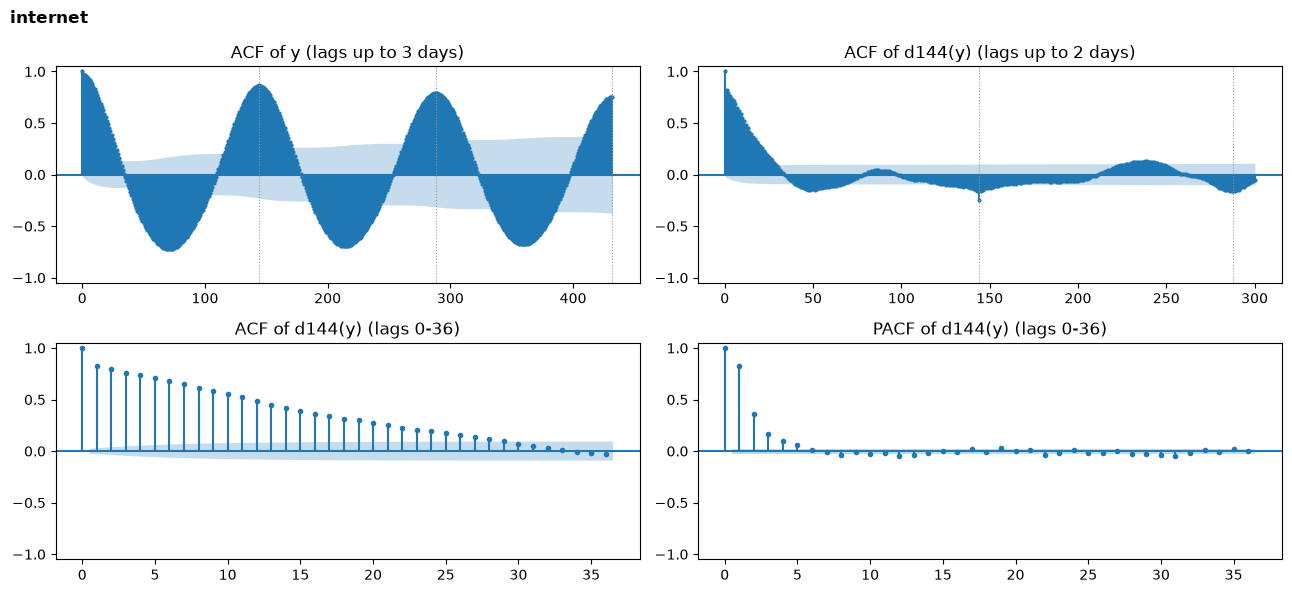

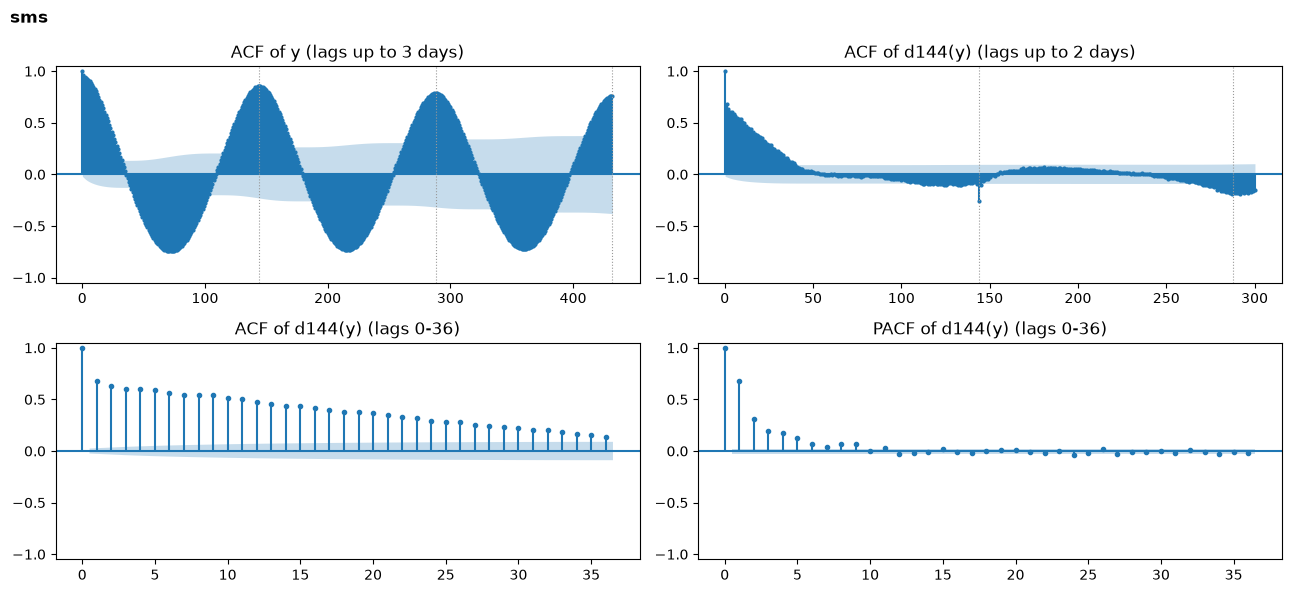

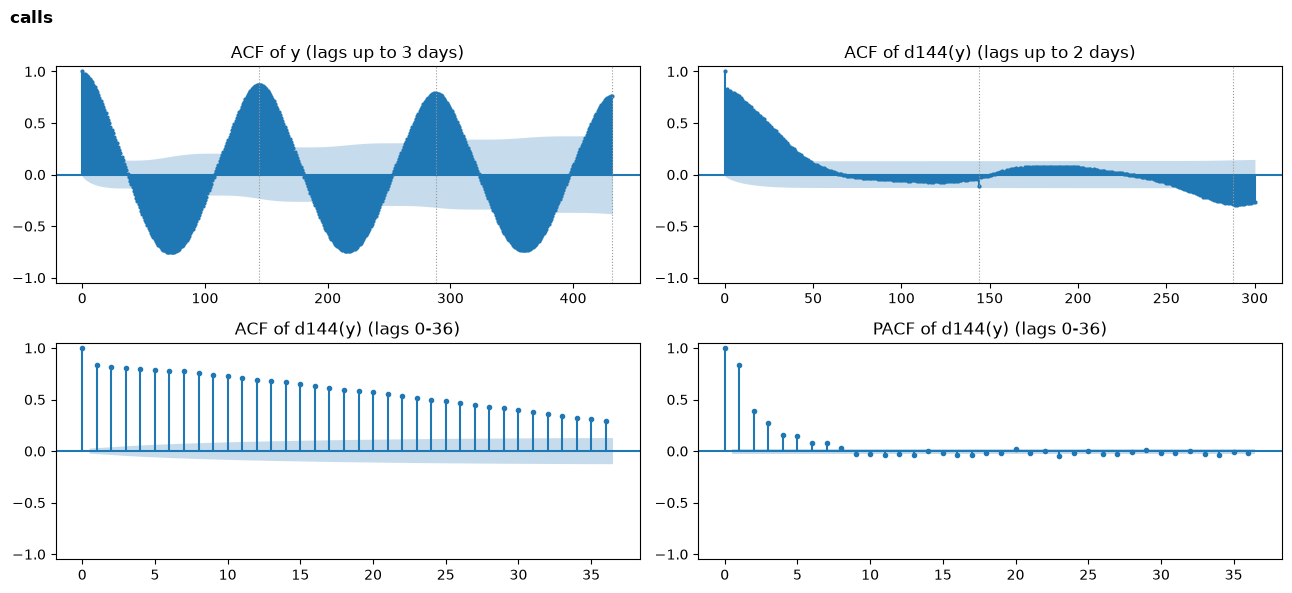

In [13]:
# y: daily seasonality? d144(y): what is left after removing it (p, q, P, Q)
for s in SERIES:
    y = pd.Series(Y[s][:n_train])
    ds = y.diff(SEASON).dropna()
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    plot_acf(y, lags=3 * SEASON, ax=axes[0, 0], markersize=2, title="ACF of y (lags up to 3 days)")
    plot_acf(ds, lags=2 * SEASON + 12, ax=axes[0, 1], markersize=2, title="ACF of d144(y) (lags up to 2 days)")
    plot_acf(ds, lags=36, ax=axes[1, 0], markersize=3, title="ACF of d144(y) (lags 0-36)")
    plot_pacf(ds, lags=36, ax=axes[1, 1], markersize=3, method="ywm", title="PACF of d144(y) (lags 0-36)")
    for ax in axes.flat:
        ax.set_ylim(-1.05, 1.05)
    for ax in axes[0]:
        for k in range(SEASON, int(ax.get_xlim()[1]), SEASON):
            ax.axvline(k, color="0.6", ls=":", lw=0.8)
    fig.suptitle(s, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

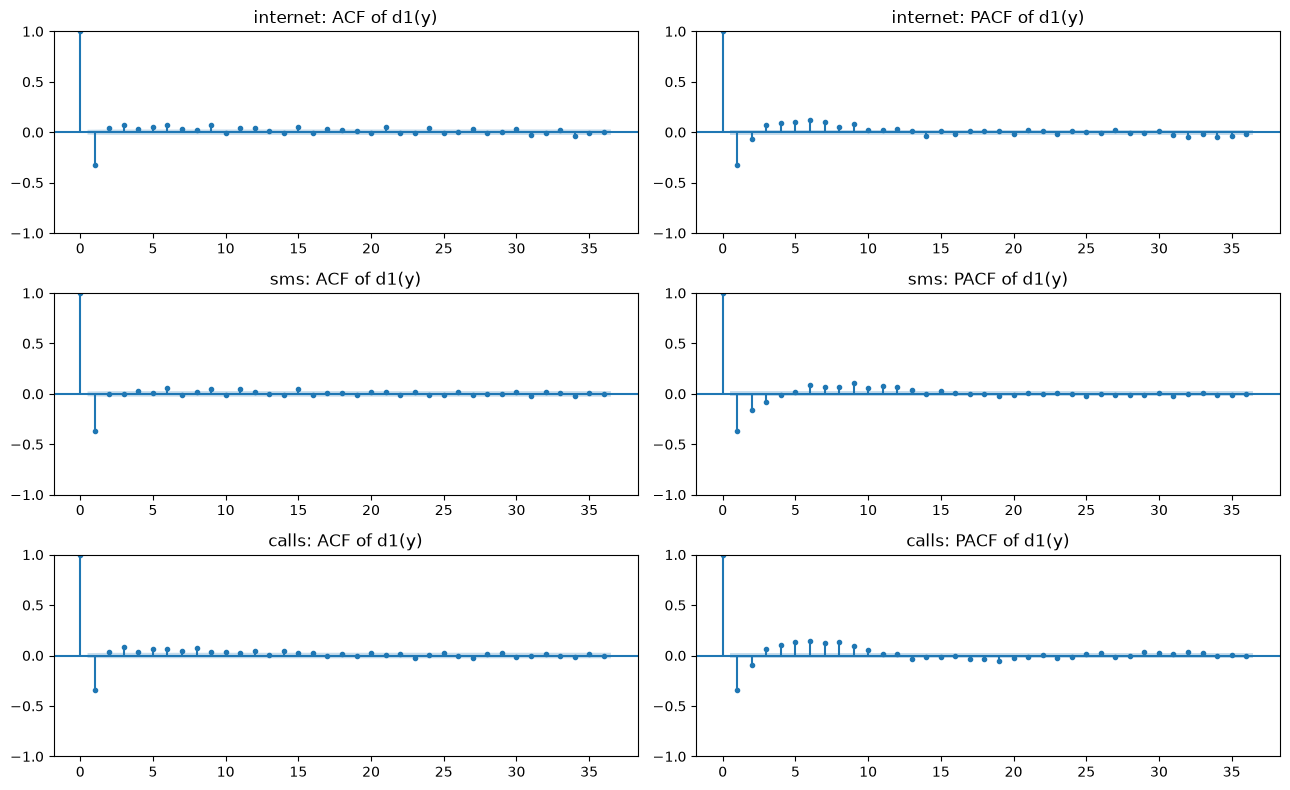

In [14]:
# ACF/PACF of the first difference d1(y) (for the plain, non-seasonal ARIMA)
fig, axes = plt.subplots(len(SERIES), 2, figsize=(13, 8))
for i, s in enumerate(SERIES):
    d1 = pd.Series(Y[s][:n_train]).diff().dropna()
    plot_acf(d1, lags=36, ax=axes[i, 0], markersize=3, title=f"{s}: ACF of d1(y)")
    plot_pacf(d1, lags=36, ax=axes[i, 1], markersize=3, method="ywm", title=f"{s}: PACF of d1(y)")
fig.tight_layout(); plt.show()

**Ερμηνεία των ACF / PACF**

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| ACF της $y$ στα lags 144, 288, 432 | 0.87, 0.79, 0.75 | 0.86, 0.79, 0.76 | 0.87, 0.79, 0.76 |
| ACF της $\nabla_{144} y$: πρώτο lag μέσα στη ζώνη | 33 | 50 | 62 |
| ACF της $\nabla_{144} y$ στο lag 144 | $-0.25$ | $-0.25$ | $-0.11$ |
| PACF της $\nabla_{144} y$, lags 1 έως 4 | 0.82, 0.36, 0.16, 0.10 | 0.68, 0.31, 0.20, 0.17 | 0.83, 0.39, 0.27, 0.16 |
| ACF της $\nabla y$ στο lag 1 | $-0.33$ | $-0.37$ | $-0.35$ |

* **ACF της $y$:** ημιτονοειδής μορφή με κορυφές στα 144, 288, 432 που **σχεδόν δεν μειώνονται** (από 0.87 σε 0.75
  μέσα σε τρεις ημέρες). Το ημερήσιο μοτίβο είναι σχεδόν ντετερμινιστικό και ένα ARMA χαμηλής τάξης δεν μπορεί να το
  περιγράψει. Χρειάζεται **εποχική διαφόριση $D = 1$ με $s = 144$**, ή εναλλακτικά ντετερμινιστικοί εποχικοί όροι
  (Fourier), όπως στο ARIMA-x.
* **ACF της $\nabla_{144}\, y$:** φθίνει ομαλά και μπαίνει στη ζώνη μετά από 33 έως 62 lags. Η σειρά είναι πλέον
  στάσιμη, άρα **δεν χρειάζεται επιπλέον $d$**. Στο lag 144 εμφανίζεται **αρνητική ακίδα**, η τυπική υπογραφή ενός
  εποχικού MA(1), άρα **$Q = 1$**. (Η εποχική διαφόριση «υπερ-διορθώνει» λίγο, και ο όρος $\Theta_1 B^{144}$ το
  αντισταθμίζει.) Η ακίδα είναι πιο αδύναμη στα Calls.
* **PACF της $\nabla_{144}\, y$:** σημαντικές τιμές στα πρώτα 4 έως 6 lags και μετά πρακτικά μηδέν, ενώ η ACF φθίνει
  σταδιακά. Αυτή είναι η εικόνα ενός **AR($p$) με $p \approx 3$ έως $6$ και $q = 0$**.
* **ACF/PACF της $\nabla y$:** μία αρνητική ακίδα (περίπου $-0.35$) στο lag 1 της ACF και μετά σχεδόν μηδέν, με PACF
  που φθίνει. Είναι το αποτύπωμα ενός MA(1). Η τιμή απέχει από το $-0.5$ της υπερ-διαφόρισης, αλλά αφού τα ADF/KPSS
  έδειξαν ότι η $y$ είναι ήδη στάσιμη, για το καθαρό ARIMA προτιμάμε **$d = 0$ με σταθερά** και ένα μικτό ARMA
  χαμηλής τάξης.

### 2.4 Εκτίμηση των παραμέτρων: Conditional Sum of Squares (CSS)

#### Γιατί όχι απλώς `statsmodels.SARIMAX`

Το `SARIMAX` γράφει το μοντέλο σε μορφή state-space και υπολογίζει την ακριβή πιθανοφάνεια με Kalman filter. Με
$s = 144$, ένα SARIMA$(p,0,q)(0,1,1)_{144}$ έχει διάνυσμα κατάστασης διάστασης περίπου $p + 145 + 145 \approx 290$.
Κάθε βήμα του φίλτρου κοστίζει $O(k^3)$ σε αυτή τη διάσταση, οπότε μία αξιολόγηση της πιθανοφάνειας στα 6624 σημεία
του train παίρνει δεκάδες δευτερόλεπτα και ένα πλήρες fit ώρες. Για ένα πλέγμα εκατοντάδων μοντέλων αυτό δεν είναι
εφικτό.

#### Η ιδέα του CSS

Ο κλασικός εκτιμητής των Box και Jenkins: υπολογίζουμε τις διαταραχές $\varepsilon_t$ αναδρομικά, υποθέτοντας ότι οι
τιμές πριν από την αρχή του δείγματος είναι μηδέν (γι' αυτό «conditional»), και διαλέγουμε τις παραμέτρους που κάνουν
το άθροισμα των τετραγώνων τους όσο το δυνατόν μικρότερο.

Το μοντέλο, σε τρία βήματα:

$$
\begin{aligned}
u_t &= y_t - c - \beta^\top x_t && \text{(αφαιρούμε σταθερά και εξωγενείς όρους)} \\[4pt]
z_t &= (1 - B^{s})^{D}\, u_t && \text{(εποχική διαφόριση, αν } D = 1\text{)} \\[4pt]
\phi(B)\, z_t &= \psi(B)\, \varepsilon_t, \quad \psi(B) = \theta(B)\,\Theta(B^s) && \text{(ARMA με εποχικό MA)}
\end{aligned}
$$

Λύνοντας ως προς $\varepsilon_t$ παίρνουμε την αναδρομή

$$\varepsilon_t \;=\; z_t \;-\; \sum_{i=1}^{p} \phi_i\, z_{t-i} \;-\; \sum_{m \ge 1} \psi_m\, \varepsilon_{t-m}$$

και ελαχιστοποιούμε

$$S(c, \beta, \phi, \theta, \Theta) \;=\; \sum_t \varepsilon_t^2$$

#### Γιατί είναι γρήγορο και γιατί είναι σωστό

* **Γρήγορο:** η αναδρομή είναι ακριβώς ένα ψηφιακό IIR φίλτρο, $\varepsilon = \dfrac{\phi(B)}{\psi(B)}\, z$, που το
  `scipy.signal.lfilter` υπολογίζει σε χιλιοστά του δευτερολέπτου.
* **Σωστό:** η επίδραση των μηδενικών αρχικών τιμών σβήνει γρήγορα (αν το MA είναι αντιστρέψιμο), οπότε για μεγάλο
  $n$ ο CSS είναι ασυμπτωτικά ισοδύναμος με τον εκτιμητή μέγιστης πιθανοφάνειας (MLE). Το R `arima` τον χρησιμοποιεί
  για αρχικοποίηση για τον ίδιο λόγο.

Με Gaussian διαταραχές, η log-πιθανοφάνεια είναι περίπου $-\tfrac{n}{2} \log \hat\sigma^2$, όπου
$\hat\sigma^2 = S / n$. Από εκεί προκύπτουν τα κριτήρια πληροφορίας ($k$ = πλήθος παραμέτρων):

$$\text{AIC} = n \log \hat\sigma^2 + 2k, \qquad \text{BIC} = n \log \hat\sigma^2 + k \log n$$

Τα τυπικά σφάλματα των παραμέτρων προκύπτουν από $\hat\sigma^2 (J^\top J)^{-1}$, όπου $J$ η Ιακωβιανή των καταλοίπων
ως προς τις παραμέτρους.

**Επαλήθευση.** Επειδή γράφουμε δικό μας εκτιμητή, τον συγκρίνουμε με τον ακριβή MLE του `statsmodels` σε ένα μη
εποχικό ARIMA(2,0,1), όπου το `SARIMAX` είναι γρήγορο. Συγκρίνουμε και τις παραμέτρους και τις προβλέψεις ενός βήματος
στο test.

In [15]:
import time
from scipy.signal import lfilter
from scipy.optimize import least_squares
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox


class CSSARIMA:
    """(S)ARIMA(X) (p,0,q)(0,D,Q)_s with constant/exogenous regressors, estimated by CSS."""

    def __init__(self, p, q, D=0, Q=0, s=SEASON, const=True):
        self.p, self.q, self.D, self.Q, self.s, self.const = p, q, D, Q, s, const

    # parameter vector: [c?, beta(k), phi(p), theta(q), Theta(Q)]
    def _unpack(self, prm):
        i = 0
        c = prm[i] if self.const else 0.0; i += int(self.const)
        beta = prm[i:i + self.k]; i += self.k
        phi = prm[i:i + self.p]; i += self.p
        th = prm[i:i + self.q]; i += self.q
        Th = prm[i:i + self.Q]
        return c, beta, phi, th, Th

    def _polys(self, phi, th, Th):
        ar = np.r_[1.0, -phi]
        ma = np.r_[1.0, th]
        if self.Q:                                     # theta(B) * Theta(B^s)
            sma = np.zeros(self.s * self.Q + 1); sma[0] = 1.0
            sma[self.s * np.arange(1, self.Q + 1)] = Th
            ma = np.convolve(ma, sma)
        return ar, ma

    def _u(self, prm, y, X):
        c, beta, *_ = self._unpack(prm)
        return y - c - (X @ beta if self.k else 0.0)

    def _z(self, u):
        return u[self.s:] - u[:-self.s] if self.D else u

    def _resid(self, prm, y, X):
        _, _, phi, th, Th = self._unpack(prm)
        ar, ma = self._polys(phi, th, Th)
        e = lfilter(ar, ma, self._z(self._u(prm, y, X)))
        return np.nan_to_num(e, nan=1e8, posinf=1e8, neginf=-1e8)   # guard against a non-invertible MA

    def fit(self, y, X=None):
        self.k = 0 if X is None else X.shape[1]
        off = self.s * self.D
        # starting values: OLS for (c, beta), then an OLS AR(p) fit on what is left
        yz = y[off:] - y[:-off] if self.D else y
        Xz = (X[off:] - X[:-off] if self.D else X) if self.k else np.empty((len(yz), 0))
        c_ols = self.const and not self.D
        A = np.c_[np.ones(len(yz)) if c_ols else np.empty((len(yz), 0)), Xz]
        b0 = np.linalg.lstsq(A, yz, rcond=None)[0] if A.shape[1] else np.empty(0)
        c0 = b0[0] if c_ols else (np.mean(y) if self.const else None)
        beta0 = b0[int(c_ols):] if self.k else np.empty(0)
        zz = yz - (Xz @ beta0 if self.k else 0) - (c0 if c_ols else 0)
        if self.p:
            L = np.column_stack([zz[self.p - i - 1:len(zz) - i - 1] for i in range(self.p)])
            phi0 = np.clip(np.linalg.lstsq(L, zz[self.p:], rcond=None)[0], -2.5, 2.5)
        else:
            phi0 = np.empty(0)
        x0 = np.r_[[c0] if self.const else [], beta0, phi0, np.zeros(self.q), -0.3 * np.ones(self.Q)]
        lb = np.r_[[-np.inf] * (int(self.const) + self.k), [-3] * self.p, [-0.99] * (self.q + self.Q)]
        ub = -lb
        x0 = np.clip(x0, lb + 1e-3, ub - 1e-3)
        t0 = time.perf_counter()
        r = least_squares(lambda prm: self._resid(prm, y, X)[self.p:], x0, bounds=(lb, ub), method="trf",
                          x_scale="jac", max_nfev=200 * len(x0))
        self.fit_seconds = time.perf_counter() - t0
        self.params, self.converged = r.x, r.success
        e = self._resid(self.params, y, X)[self.p:]
        n, kk = len(e), len(self.params)
        self.sigma2 = float(np.mean(e ** 2))
        self.aic = n * np.log(self.sigma2) + 2 * kk
        self.bic = n * np.log(self.sigma2) + kk * np.log(n)
        try:                                           # std. errors from sigma2 (J'J)^-1
            self.bse = np.sqrt(np.diag(self.sigma2 * np.linalg.inv(r.jac.T @ r.jac)))
        except np.linalg.LinAlgError:
            self.bse = np.full(kk, np.nan)
        return self

    def param_names(self):
        return ((["const"] if self.const else []) + [f"beta{i}" for i in range(self.k)] +
                [f"ar.L{i+1}" for i in range(self.p)] + [f"ma.L{i+1}" for i in range(self.q)] +
                [f"ma.S.L{self.s*(i+1)}" for i in range(self.Q)])

    def resid_full(self, y, X=None):
        """Residuals (= one-step-ahead forecast errors) over the whole series, with the fitted parameters."""
        return np.r_[np.full(self.s * self.D, np.nan), self._resid(self.params, y, X)]

    def forecast_paths(self, y, X, origins, H):
        """From each origin t (y[:t] known) forecast y[t..t+H-1], recursively. Vectorised over the origins."""
        c, beta, phi, th, Th = self._unpack(self.params)
        ar, ma = self._polys(phi, th, Th)
        u = self._u(self.params, y, X)
        w = self._z(u)                                 # w[i] corresponds to y[i + sD]
        eps = lfilter(ar, ma, w)
        off = self.s * self.D
        O = np.asarray(origins) - off                  # indices into w
        what = np.zeros((len(O), H))
        nz = np.flatnonzero(ma[1:]) + 1                # non-zero MA coefficients
        for j in range(H):
            acc = np.zeros(len(O))
            for i in range(1, self.p + 1):             # AR: actual values or earlier forecasts
                acc += phi[i - 1] * (what[:, j - i] if i <= j else w[O + j - i])
            for m in nz:                               # MA: only past (known) errors, future ones = 0
                if m > j:
                    acc += ma[m] * eps[O + j - m]
            what[:, j] = acc
        tidx = np.asarray(origins)[:, None] + np.arange(H)[None, :]
        uhat = what + (u[tidx - self.s] if self.D else 0.0)   # undo (1-B^s): u_t = w_t + u_{t-s}
        return uhat + c + (X[tidx] @ beta if self.k else 0.0)

In [16]:
# Check the implementation: ARIMA(2,0,1)+c, CSS vs exact MLE (statsmodels)
yv = Y["internet"][:n_train]
mine = CSSARIMA(2, 1).fit(yv)
ref = SARIMAX(yv, order=(2, 0, 1), trend="c").fit(disp=False)
ref_mu = ref.params[0] / (1 - ref.params[1] - ref.params[2])     # statsmodels: c = mu(1-phi1-phi2)
print("CSS:", dict(zip(mine.param_names(), mine.params.round(4))), f"sigma2={mine.sigma2:.1f}, {mine.fit_seconds:.2f}s")
print("MLE:", {"mean": round(ref_mu, 4), **dict(zip(["ar.L1", "ar.L2", "ma.L1", "sigma2"], ref.params[1:].round(4)))})

# Same one-step forecasts on the test set?
p_ref = ref.apply(Y["internet"]).filter_results.forecasts[0, n_train:]
p_mine = mine.forecast_paths(Y["internet"], None, np.arange(n_train, N), 1)[:, 0]
print(f"h=1 on the test set: mean |CSS - MLE| = {np.mean(np.abs(p_ref - p_mine)):.3f} "
      f"(model MAE ~ {np.mean(np.abs(Y['internet'][n_train:] - p_ref)):.1f})")

CSS: {'const': np.float64(566.9002), 'ar.L1': np.float64(0.7731), 'ar.L2': np.float64(0.2142), 'ma.L1': np.float64(-0.1218)} sigma2=5392.9, 0.02s
MLE: {'mean': np.float64(567.1102), 'ar.L1': np.float64(0.7723), 'ar.L2': np.float64(0.2146), 'ma.L1': np.float64(-0.1211), 'sigma2': np.float64(5407.957)}
h=1 on the test set: mean |CSS - MLE| = 0.141 (model MAE ~ 36.8)


**Αποτέλεσμα της επαλήθευσης.** Οι παράμετροι του CSS και του MLE συμφωνούν στο τρίτο δεκαδικό (π.χ.
$\phi_1 = 0.773$ έναντι $0.772$, $\theta_1 = -0.122$ έναντι $-0.121$), και οι προβλέψεις ενός βήματος στο test
διαφέρουν κατά μέσο όρο 0.14, όταν το σφάλμα του ίδιου του μοντέλου είναι περίπου 37. Η διαφορά είναι δηλαδή
αμελητέα (λιγότερο από 0.4% του σφάλματος) και το CSS είναι περίπου 1000 φορές πιο γρήγορο.

### 2.5 Επιλογή τάξεων: a priori ανάγνωση και επιβεβαίωση με BIC

#### A priori εκτιμήσεις

Από τις ενότητες 2.2 και 2.3 προκύπτουν τα εξής εύρη:

| Μοντέλο | $d$ | $D$ | $p$ | $q$ | $Q$ | Τεκμηρίωση |
|:---|:---:|:---:|:---:|:---:|:---:|:---|
| ARIMA | 0 | 0 | 2 έως 3 | 1 | 0 | ADF/KPSS: η $y$ είναι στάσιμη, άρα $d = 0$ με σταθερά. Η ACF της $\nabla y$ έχει μία ακίδα στο lag 1 και η PACF φθίνει: μικτό ARMA χαμηλής τάξης. |
| SARIMA | 0 | 1 | 3 έως 6 | 0 | 1 | Αργά φθίνουσες κορυφές στα 144, 288, 432: $D = 1$. Η ACF της $\nabla_{144} y$ φθίνει (άρα $d = 0$) και έχει αρνητική ακίδα στο 144: $Q = 1$. Η PACF κόβεται μετά από 4 έως 6 lags: AR($p$). |
| ARIMA-x | 0 | 0 | 1 έως 2 | 1 | 0 | Οι όροι Fourier αφαιρούν την περιοδικότητα και μένει μόνο βραχυπρόθεσμη αυτοσυσχέτιση. |
| SARIMA-x | 0 | 1 | 3 έως 6 | 0 | 1 | Όπως το SARIMA, με επιπλέον τον εβδομαδιαίο κύκλο και τις αργίες ως εξωγενείς μεταβλητές. |

#### Οι εξωγενείς μεταβλητές

Το επόμενο κελί κατασκευάζει τον πίνακα $x_t$:

* **Ημερήσιοι όροι Fourier**, $K = 4$ αρμονικές περιόδου 144. Με 4 αρμονικές το σχήμα έχει αρκετή λεπτομέρεια για την
  απότομη πρωινή άνοδο και τη μεσημεριανή κορυφή, χωρίς να γίνεται «θορυβώδες».
* **Εβδομαδιαίοι όροι Fourier**, $K = 2$ αρμονικές περιόδου 1008, για τη διαφορά ανάμεσα στις ημέρες της εβδομάδας.
* **Δείκτης μη εργάσιμης ημέρας** `offday`: 1 για Κυριακή ή αργία, 0.5 για Σάββατο, 0 για εργάσιμη. Το Σάββατο παίρνει
  ενδιάμεση τιμή, γιατί στην EDA η συμπεριφορά του ήταν ανάμεσα στις δύο άλλες κατηγορίες. Αυτός είναι ο μόνος τρόπος
  να ξέρει το μοντέλο ότι π.χ. τα Χριστούγεννα δεν είναι κανονική Τετάρτη.
* **Αλληλεπιδράσεις** `offday` $\times$ (πρώτοι 2 ημερήσιοι όροι): επιτρέπουν στο ημερήσιο **σχήμα** να είναι
  διαφορετικό τις μη εργάσιμες (κορυφή το απόγευμα αντί για το μεσημέρι), όχι μόνο το επίπεδο.

Στο **SARIMA-x** οι καθαροί ημερήσιοι όροι Fourier **παραλείπονται**. Ο λόγος: ένας όρος με περίοδο ακριβώς 144
μηδενίζεται από την εποχική διαφόριση, αφού $x_t - x_{t-144} = 0$. Ο συντελεστής του θα ήταν τότε μη αναγνωρίσιμος (δεν
επηρεάζει καθόλου το μοντέλο). Η εποχική διαφόριση έχει ήδη αφαιρέσει το ημερήσιο μοτίβο.

#### Γιατί BIC

Μέσα στα εύρη της a priori ανάγνωσης η τελική επιλογή γίνεται με το **BIC** στο train set. Και τα δύο κριτήρια
ανταμείβουν την καλή προσαρμογή ($n \log \hat\sigma^2$ μικρό) και τιμωρούν την πολυπλοκότητα, αλλά με διαφορετικό
βάρος: ανά παράμετρο το AIC προσθέτει 2 ενώ το BIC προσθέτει $\log n \approx 8.8$ (για $n \approx 6600$). Με τόσα πολλά
σημεία, το AIC θα διάλεγε σχεδόν πάντα το μεγαλύτερο μοντέλο, γιατί κάθε μικρή βελτίωση στο $\hat\sigma^2$ πολλαπλασιάζεται
επί $n$. Το BIC είναι **συνεπές** (με αρκετά δεδομένα βρίσκει τη σωστή τάξη) και προτιμά φειδωλά μοντέλα, που συνήθως
προβλέπουν καλύτερα εκτός δείγματος. Ως εμπειρικός κανόνας, διαφορά BIC μεγαλύτερη από 10 θεωρείται ισχυρή ένδειξη
υπέρ του μοντέλου με το μικρότερο BIC.

Το πλέγμα είναι λίγο ευρύτερο από τα a priori εύρη ($p \le 4$ ή $6$, $q \le 3$ ή $2$), ώστε να φανεί αν το BIC
συμφωνεί με τη γραφική ανάλυση ή αν «σπρώχνει» προς τα άκρα του.

In [17]:
WEEK = 7 * SEASON                              # 1008 ten-minute steps


def exog_matrix(idx, k_day=4, k_week=2, k_off=2, daily_terms=True):
    """Deterministic periodicity regressors for ARIMA-x."""
    slot = (idx.hour * 6 + idx.minute // 10).values
    wpos = idx.dayofweek.values * SEASON + slot
    dt = day_type(idx)
    off = (dt == 2).astype(float) + 0.5 * (dt == 1)   # Sunday/holiday = 1, Saturday = 0.5
    cols = {"offday": off}
    for k in range(1, k_day + 1):
        sd, cd = np.sin(2 * np.pi * k * slot / SEASON), np.cos(2 * np.pi * k * slot / SEASON)
        if daily_terms:
            cols[f"d_sin{k}"], cols[f"d_cos{k}"] = sd, cd
        if k <= k_off:
            cols[f"off_sin{k}"], cols[f"off_cos{k}"] = off * sd, off * cd
    for k in range(1, k_week + 1):
        cols[f"w_sin{k}"] = np.sin(2 * np.pi * k * wpos / WEEK)
        cols[f"w_cos{k}"] = np.cos(2 * np.pi * k * wpos / WEEK)
    return pd.DataFrame(cols, index=idx)


X_ARIMAX = exog_matrix(df.index)
X_SARIMAX = exog_matrix(df.index, daily_terms=False)
print("ARIMA-x exog:", list(X_ARIMAX.columns))
print("SARIMA-x exog:", list(X_SARIMAX.columns))

ARIMA-x exog: ['offday', 'd_sin1', 'd_cos1', 'off_sin1', 'off_cos1', 'd_sin2', 'd_cos2', 'off_sin2', 'off_cos2', 'd_sin3', 'd_cos3', 'd_sin4', 'd_cos4', 'w_sin1', 'w_cos1', 'w_sin2', 'w_cos2']
SARIMA-x exog: ['offday', 'off_sin1', 'off_cos1', 'off_sin2', 'off_cos2', 'w_sin1', 'w_cos1', 'w_sin2', 'w_cos2']


In [18]:
from joblib import Parallel, delayed

FAMILIES = {   # name: (D, Q, exog, p grid, q grid)
    "ARIMA":   (0, 0, None,      range(0, 5), range(0, 4)),
    "SARIMA":  (1, 1, None,      range(0, 7), range(0, 3)),
    "ARIMAX":  (0, 0, X_ARIMAX,  range(0, 5), range(0, 4)),
    "SARIMAX": (1, 1, X_SARIMAX, range(0, 7), range(0, 3)),
}


def fit_one(s, fam, p, q):
    warnings.filterwarnings("ignore")              # overflow warnings from trial steps of the optimiser
    D, Q, X, *_ = FAMILIES[fam]
    m = CSSARIMA(p, q, D, Q, const=(D == 0)).fit(Y[s][:n_train], None if X is None else X.values[:n_train])
    return {"series": s, "model": fam, "p": p, "q": q, "BIC": m.bic, "AIC": m.aic, "conv": m.converged}


jobs = [(s, fam, p, q) for s in SERIES for fam, (_, _, _, P_, Q_) in FAMILIES.items() for p in P_ for q in Q_]
t0 = time.perf_counter()
GRID = pd.DataFrame(Parallel(n_jobs=16)(delayed(fit_one)(*j) for j in jobs))
print(f"{len(jobs)} fits in {time.perf_counter() - t0:.0f}s")

BEST = GRID.loc[GRID.groupby(["series", "model"])["BIC"].idxmin()].set_index(["series", "model"])
BEST[["p", "q", "BIC"]]

246 fits in 4s


p  q           BIC
series   model                      
calls    ARIMA    4  3  35123.272540
         ARIMAX   1  1  34071.338421
         SARIMA   5  2  34187.244397
         SARIMAX  5  1  33811.523399
internet ARIMA    4  1  56293.282307
         ARIMAX   4  3  55893.949015
         SARIMA   6  1  55535.348082
         SARIMAX  6  2  55408.119082
sms      ARIMA    4  3  39819.208858
         ARIMAX   2  1  39144.224647
         SARIMA   4  1  39190.561018
         SARIMAX  4  1  38928.195835

In [19]:
# Full BIC tables (rows: p, columns: q)
for fam in FAMILIES:
    print(f"BIC - {fam}")
    display(GRID[GRID["model"] == fam].pivot_table(index=["series", "p"], columns="q", values="BIC").round(0))

BIC - ARIMA


q                 0        1        2        3
series   p                                    
calls    0  58264.0  51275.0  47298.0  44660.0
         1  36767.0  35991.0  35899.0  35796.0
         2  35960.0  35934.0  35675.0  35566.0
         3  35909.0  35905.0  35480.0  35125.0
         4  35877.0  35203.0  35204.0  35123.0
internet 0  78284.0  71382.0  67522.0  64914.0
         1  57656.0  56990.0  56908.0  56832.0
         2  56946.0  56937.0  56717.0  56667.0
         3  56918.0  56914.0  56482.0  56318.0
         4  56877.0  56293.0  56300.0  56302.0
sms      0  58039.0  51967.0  48585.0  46561.0
         1  41422.0  40342.0  40345.0  40335.0
         2  40513.0  40341.0  40308.0  40263.0
         3  40352.0  40335.0  40294.0  39830.0
         4  40320.0  40329.0  40295.0  39819.0

BIC - SARIMA


q                 0        1        2
series   p                           
calls    0  46344.0  41921.0  39883.0
         1  36027.0  34213.0  34222.0
         2  34842.0  34217.0  34224.0
         3  34413.0  34212.0  34222.0
         4  34297.0  34214.0  34224.0
         5  34209.0  34200.0  34187.0
         6  34196.0  34202.0  34191.0
internet 0  66089.0  61943.0  59957.0
         1  56727.0  55642.0  55640.0
         2  55813.0  55630.0  55612.0
         3  55637.0  55624.0  55608.0
         4  55614.0  55622.0  55606.0
         5  55612.0  55614.0  55566.0
         6  55607.0  55535.0  55542.0
sms      0  46188.0  43379.0  42056.0
         1  40598.0  39221.0  39207.0
         2  39778.0  39197.0  39205.0
         3  39532.0  39200.0  39201.0
         4  39336.0  39191.0  39200.0
         5  39268.0  39194.0  39201.0
         6  39206.0  39191.0  39199.0

BIC - ARIMAX


q                 0        1        2        3
series   p                                    
calls    0  39299.0  37121.0  36247.0  35654.0
         1  35346.0  34071.0  34075.0  34084.0
         2  34592.0  34071.0  34078.0  34087.0
         3  34278.0  34075.0  34083.0  34088.0
         4  34186.0  34079.0  34087.0  34093.0
internet 0  63464.0  60166.0  58763.0  57830.0
         1  56826.0  55917.0  55918.0  55914.0
         2  56064.0  55911.0  55902.0  55902.0
         3  55903.0  55902.0  55898.0  55895.0
         4  55895.0  55903.0  55899.0  55894.0
sms      0  41910.0  40544.0  40019.0  39788.0
         1  39746.0  39176.0  39154.0  39157.0
         2  39393.0  39144.0  39151.0  39158.0
         3  39288.0  39145.0  39153.0  39162.0
         4  39218.0  39147.0  39156.0  39164.0

BIC - SARIMAX


q                 0        1        2
series   p                           
calls    0  37714.0  36119.0  35482.0
         1  34969.0  33813.0  33819.0
         2  34331.0  33815.0  33820.0
         3  34041.0  33818.0  33825.0
         4  33949.0  33822.0  33829.0
         5  33854.0  33812.0  33813.0
         6  33826.0  33815.0  33816.0
internet 0  62419.0  59426.0  58085.0
         1  56426.0  55439.0  55444.0
         2  55635.0  55434.0  55432.0
         3  55459.0  55432.0  55429.0
         4  55427.0  55430.0  55425.0
         5  55419.0  55428.0  55423.0
         6  55417.0  55425.0  55408.0
sms      0  41267.0  40169.0  39708.0
         1  39552.0  38963.0  38942.0
         2  39212.0  38931.0  38938.0
         3  39119.0  38932.0  38932.0
         4  39018.0  38928.0  38935.0
         5  38985.0  38932.0  38938.0
         6  38945.0  38932.0  38939.0

**Επιβεβαίωση με BIC**

| | ARIMA | SARIMA $(\cdot)(0,1,1)_{144}$ | ARIMA-x | SARIMA-x |
|:---|:---:|:---:|:---:|:---:|
| Internet | (4,0,1) | (6,0,1) | (4,0,3) | (6,0,2) |
| SMS | (4,0,3) | (4,0,1) | (2,0,1) | (4,0,1) |
| Calls | (4,0,3) | (5,0,2) | (1,0,1) | (5,0,1) |

* **SARIMA:** $p = 4$ έως $6$ και $Q = 1$, μέσα στο a priori εύρος, με εποχικό συντελεστή $\Theta_1 \approx -0.82$ έως
  $-0.88$. Το BIC προσθέτει επίσης ένα μικρό $q = 1$ ή $2$, με $\theta_1 \approx -0.65$ έως $-0.99$, μαζί με
  $\phi_1 \approx 1.0$ έως $1.4$. Ένας AR όρος κοντά στη μονάδα μαζί με έναν MA όρο κοντά στο $-1$ σχεδόν
  αλληλοαναιρούνται. Αυτό που μένει μοντελοποιεί μια αργά μεταβαλλόμενη «στάθμη» πάνω στο ημερήσιο σχήμα, κάτι σαν
  εκθετική εξομάλυνση. Το BIC είναι πολύ επίπεδο κοντά στο ελάχιστο: όλα τα μοντέλα με $p \ge 2$ και $q \ge 1$
  απέχουν λιγότερο από 100 μονάδες (για το SMS λιγότερο από 20), οπότε η ακριβής τάξη δεν έχει μεγάλη σημασία.
* **Καθαρό ARIMA:** το BIC επιλέγει τις **μεγαλύτερες** τάξεις του πλέγματος, (4,0,1) και (4,0,3). Χωρίς εποχικό όρο,
  το μοντέλο προσπαθεί να μιμηθεί την περιοδικότητα με AR ρίζες κοντά στον μοναδιαίο κύκλο. Στο Internet το άθροισμα
  των AR συντελεστών είναι $0.997$ και $\theta_1 = -0.97$, δηλαδή σχεδόν μοναδιαία ρίζα που αναιρείται από το MA. Στα
  SMS και Calls τα τυπικά σφάλματα είναι τεράστια (ως 5.6 για συντελεστές της τάξης του 1), ένδειξη ότι οι AR και MA
  παράγοντες αλληλοαναιρούνται και οι παράμετροι δεν προσδιορίζονται σταθερά. Όλα αυτά επιβεβαιώνουν ότι **το καθαρό
  ARIMA είναι ακατάλληλο για αυτή τη σειρά**, όπως υποψιαζόταν και η εκφώνηση.
* **ARIMA-x:** οι όροι Fourier απορροφούν την περιοδικότητα και αρκούν πολύ μικρότερες τάξεις: (1,0,1) για τα Calls
  και (2,0,1) για τα SMS. Το BIC πέφτει κατά 400 (Internet), 675 (SMS) και 1052 (Calls) σε σχέση με το καθαρό ARIMA:
  οι δείκτες περιοδικότητας εξηγούν μεγάλο μέρος της σειράς.
* **SARIMA-x:** έχει το μικρότερο BIC σε όλες τις σειρές. Σε σχέση με το SARIMA το BIC πέφτει κατά 127, 262 και 376,
  άρα ο εβδομαδιαίος κύκλος και οι αργίες βοηθούν στο train.
* **Προσοχή στις συγκρίσεις.** Το BIC συγκρίνει έγκυρα μόνο μοντέλα που εκτιμώνται στα **ίδια** δεδομένα. Τα μοντέλα με
  $D = 1$ εκτιμώνται στη διαφορισμένη σειρά (144 σημεία λιγότερα, άλλη κλίμακα), οπότε η σύγκριση ARIMA με SARIMA
  μέσω BIC είναι μόνο ενδεικτική. Η πραγματική σύγκριση γίνεται στο test (ενότητα 2.8).

### 2.6 Τελικά μοντέλα και διαγνωστικοί έλεγχοι

**Γιατί διαγνωστικοί έλεγχοι.** Αν ένα μοντέλο έχει «πιάσει» όλη τη δομή της σειράς, τα κατάλοιπά του
$\hat\varepsilon_t$ (τα σφάλματα πρόβλεψης ενός βήματος στο train) πρέπει να είναι **λευκός θόρυβος**: χωρίς
αυτοσυσχέτιση, γιατί κάθε αυτοσυσχέτιση που μένει είναι πληροφορία που το μοντέλο δεν αξιοποίησε. Ελέγχουμε:

* **ACF των καταλοίπων:** οι τιμές πρέπει να μένουν μέσα στη ζώνη $\pm 1.96/\sqrt{n}$.
* **Τεστ Ljung-Box:** συνδυάζει τις πρώτες $h$ αυτοσυσχετίσεις σε ένα στατιστικό (τύπος παρακάτω). **H0: καμία
  αυτοσυσχέτιση ως το lag $h$.** Το εφαρμόζουμε για $h = 10$ (βραχυπρόθεσμη δομή) και $h = 144$ (ως μία ημέρα).
* **Q-Q plot:** συγκρίνει τα κατάλοιπα με την κανονική κατανομή. Μας ενδιαφέρει γιατί τα κλασικά διαστήματα πρόβλεψης
  ($\hat y \pm 1.96\,\hat\sigma$) προϋποθέτουν κανονικά σφάλματα.
* **Χρονικό γράφημα των καταλοίπων:** δείχνει αν η διασπορά τους είναι σταθερή στον χρόνο.

Το στατιστικό Ljung-Box είναι

$$Q(h) \;=\; n\,(n+2) \sum_{k=1}^{h} \frac{\hat r_k^{\,2}}{n - k}$$

όπου $\hat r_k$ η αυτοσυσχέτιση των καταλοίπων στο lag $k$. Αν τα κατάλοιπα είναι λευκός θόρυβος, το $Q(h)$ ακολουθεί
περίπου κατανομή $\chi^2$, οπότε μεγάλες τιμές (μικρό $p$) σημαίνουν ότι έμεινε αυτοσυσχέτιση.

Ο πίνακας δίνει για κάθε μοντέλο την τάξη, το $\hat\sigma$, το BIC, τους συντελεστές με τα τυπικά τους σφάλματα (εκτός από
τους πολλούς συντελεστές $\beta$ των εξωγενών) και τις p-values του Ljung-Box. Τα γραφήματα δείχνουν τα κατάλοιπα του
SARIMA-x, που είχε το μικρότερο BIC.

In [20]:
warnings.filterwarnings("ignore", category=RuntimeWarning)   # overflow in trial steps of the optimiser
ARIMA_FITS = {}
for s in SERIES:
    for fam, (D, Q, X, *_) in FAMILIES.items():
        p, q = int(BEST.loc[(s, fam), "p"]), int(BEST.loc[(s, fam), "q"])
        ARIMA_FITS[(s, fam)] = CSSARIMA(p, q, D, Q, const=(D == 0)).fit(
            Y[s][:n_train], None if X is None else X.values[:n_train])


def model_label(m):
    return f"({m.p},0,{m.q})" + (f"(0,{m.D},{m.Q})_144" if m.D else "") + (f" + {m.k} exog" if m.k else "")


diag = []
for (s, fam), m in ARIMA_FITS.items():
    X = FAMILIES[fam][2]
    e = m.resid_full(Y[s][:n_train], None if X is None else X.values[:n_train])
    e = e[~np.isnan(e)][m.p + 2 * SEASON:]        # skip the initial transient
    lb = acorr_ljungbox(e, lags=[10, SEASON], return_df=True)["lb_pvalue"].values
    coefs = {nm: f"{v:.3f} ({se:.3f})" for nm, v, se in zip(m.param_names(), m.params, m.bse)
             if not nm.startswith("beta") and nm != "const"}
    diag.append({"series": s, "model": fam, "order": model_label(m), "sigma_hat": np.sqrt(m.sigma2), "BIC": m.bic,
                 "fit (s)": m.fit_seconds, "Ljung-Box p@10": lb[0], "Ljung-Box p@144": lb[1],
                 "coefficients (std. error)": ", ".join(f"{k}={v}" for k, v in coefs.items())})
DIAG = pd.DataFrame(diag).set_index(["series", "model"])
DIAG

order  sigma_hat           BIC  \
series   model                                                           
internet ARIMA                        (4,0,1)  69.949359  56293.282307   
         SARIMA            (6,0,1)(0,1,1)_144  72.507083  55535.348082   
         ARIMAX             (4,0,3) + 17 exog  67.019599  55893.949015   
         SARIMAX  (6,0,2)(0,1,1)_144 + 9 exog  71.313138  55408.119080   
sms      ARIMA                        (4,0,3)  20.129315  39819.208858   
         SARIMA            (4,0,1)(0,1,1)_144  20.527500  39190.561018   
         ARIMAX             (2,0,1) + 17 exog  18.947442  39144.224647   
         SARIMAX  (4,0,1)(0,1,1)_144 + 9 exog  19.993567  38928.195835   
calls    ARIMA                        (4,0,3)  14.118687  35123.272540   
         SARIMA            (5,0,2)(0,1,1)_144  13.936626  34187.244397   
         ARIMAX             (1,0,1) + 17 exog  12.921774  34071.338421   
         SARIMAX  (5,0,1)(0,1,1)_144 + 9 exog  13.464894  33811.523399   

                   fit (s)  Ljung-Box p@10  Ljung-Box p@144  \
series   model                                                
internet ARIMA    0.031318        0.000003     1.093717e-43   
         SARIMA   0.134573        0.015917     1.832845e-16   
         ARIMAX   0.207577        0.043947     3.426550e-22   
         SARIMAX  0.603238        0.011822     4.803145e-14   
sms      ARIMA    0.034720        0.007544     5.637626e-29   
         SARIMA   0.077298        0.154972     1.100923e-04   
         ARIMAX   0.064610        0.234893     6.513853e-06   
         SARIMAX  0.150596        0.711476     8.688964e-02   
calls    ARIMA    0.031820        0.112961     1.886428e-55   
         SARIMA   0.183169        0.000003     2.168648e-22   
         ARIMAX   0.051129        0.016362     1.198127e-08   
         SARIMAX  0.182361        0.219318     1.162224e-07   

                                          coefficients (std. error)  
series   model                                                       
internet ARIMA    ar.L1=1.535 (0.013), ar.L2=-0.262 (0.023), ar....  
         SARIMA   ar.L1=1.394 (0.022), ar.L2=-0.187 (0.023), ar....  
         ARIMAX   ar.L1=0.783 (0.084), ar.L2=0.826 (0.093), ar.L...  
         SARIMAX  ar.L1=1.434 (0.171), ar.L2=-0.407 (0.239), ar....  
sms      ARIMA    ar.L1=1.376 (0.417), ar.L2=0.308 (0.853), ar.L...  
         SARIMA   ar.L1=1.016 (0.033), ar.L2=-0.062 (0.021), ar....  
         ARIMAX   ar.L1=1.057 (0.026), ar.L2=-0.122 (0.020), ma....  
         SARIMAX  ar.L1=1.018 (0.037), ar.L2=-0.079 (0.021), ar....  
calls    ARIMA    ar.L1=1.346 (2.708), ar.L2=0.289 (5.572), ar.L...  
         SARIMA   ar.L1=1.355 (0.158), ar.L2=-0.562 (0.151), ar....  
         ARIMAX           ar.L1=0.959 (0.004), ma.L1=-0.647 (0.011)  
         SARIMAX  ar.L1=0.837 (0.059), ar.L2=0.002 (0.024), ar.L...

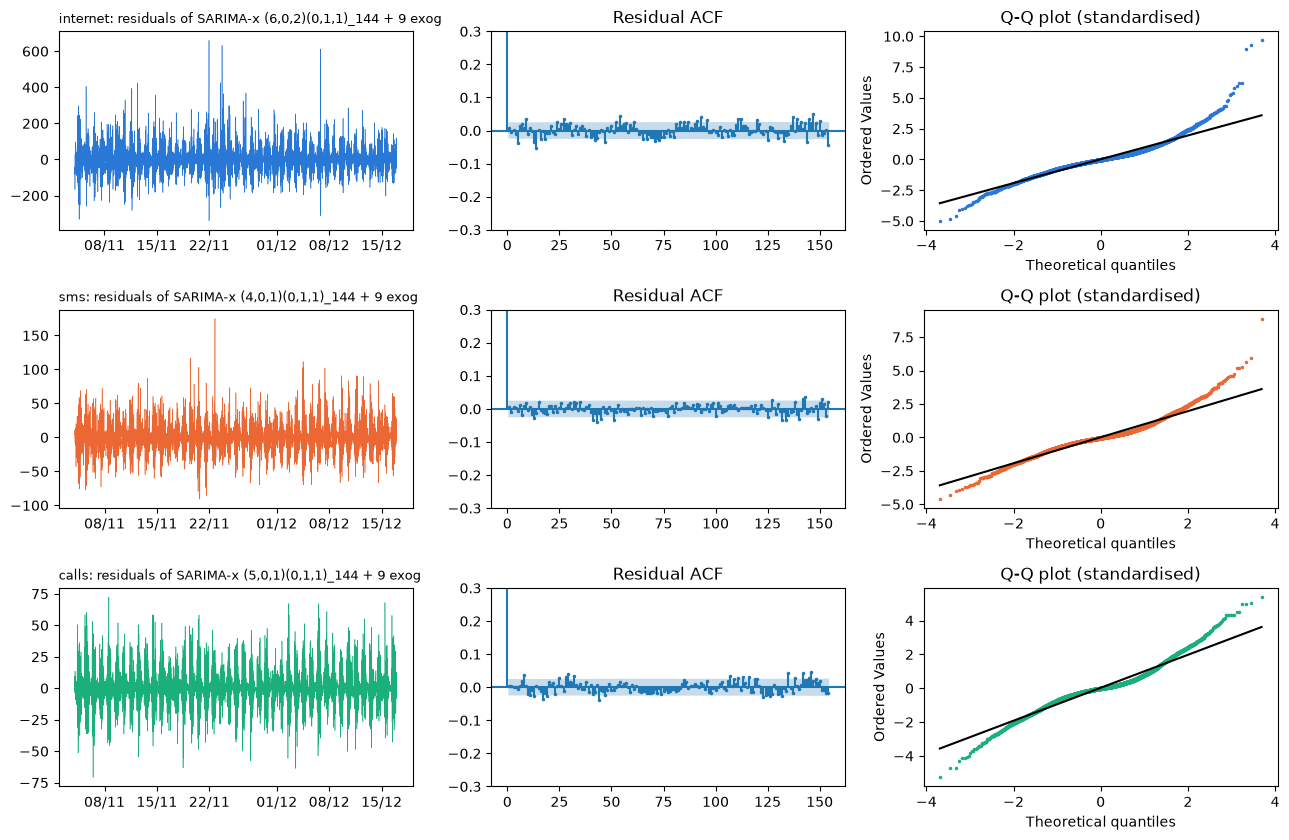

In [21]:
# Residual diagnostics of SARIMA-x: time plot, ACF, Q-Q plot
from scipy import stats as sstats

fig, axes = plt.subplots(len(SERIES), 3, figsize=(13, 8.5))
for i, s in enumerate(SERIES):
    m = ARIMA_FITS[(s, "SARIMAX")]
    skip = SEASON + m.p + 2 * SEASON
    e = m.resid_full(Y[s][:n_train], X_SARIMAX.values[:n_train])[skip:]
    axes[i, 0].plot(df.index[skip:n_train], e, color=COLOR[s], lw=0.4)
    axes[i, 0].set_title(f"{s}: residuals of SARIMA-x {model_label(m)}", loc="left", fontsize=9.5)
    axes[i, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    plot_acf(e, lags=SEASON + 10, ax=axes[i, 1], markersize=1.5, title="Residual ACF")
    axes[i, 1].set_ylim(-0.3, 0.3)
    sstats.probplot(e / e.std(), dist="norm", plot=axes[i, 2])
    axes[i, 2].get_lines()[0].set(markersize=1.5, color=COLOR[s]); axes[i, 2].get_lines()[1].set(color="k")
    axes[i, 2].set_title("Q-Q plot (standardised)")
fig.tight_layout(); plt.show()

**Ερμηνεία των διαγνωστικών ελέγχων**

* **Τα κατάλοιπα των εποχικών μοντέλων είναι σχεδόν λευκός θόρυβος.** Η μεγαλύτερη απόλυτη αυτοσυσχέτιση ως το lag
  154 είναι 0.04 έως 0.05 για το SARIMA-x, έναντι 0.10 έως 0.11 για το καθαρό ARIMA. Στο καθαρό ARIMA το μέγιστο
  βρίσκεται γύρω από το lag 144, δηλαδή **μένει ημερήσια δομή που το μοντέλο δεν έπιασε**, κάτι που περιμέναμε.
* **Το Ljung-Box απορρίπτει συχνά τη λευκότητα**, ακόμη και για τα καλά μοντέλα. Αυτό δεν σημαίνει απαραίτητα ότι
  τα μοντέλα είναι κακά: με $n \approx 6000$ σημεία το τεστ έχει τόση ισχύ που ανιχνεύει και αυτοσυσχετίσεις 0.03 έως
  0.05, που είναι πρακτικά αμελητέες για την πρόβλεψη. Το SARIMA-x του SMS περνά και τα δύο τεστ ($p = 0.71$ και
  $0.09$).
* **Τα κατάλοιπα δεν είναι κανονικά.** Το Q-Q plot δείχνει **βαριές ουρές**: η κύρτωση (σε σχέση με την κανονική) είναι
  περίπου 6.6 στο Internet και 2.8 έως 3.7 στα SMS και Calls. Υπάρχουν δηλαδή πολύ περισσότερα μεγάλα σφάλματα από όσα
  θα έδινε μια κανονική κατανομή (απρόβλεπτες αιχμές δραστηριότητας).
* **Ετεροσκεδαστικότητα.** Η τυπική απόκλιση των καταλοίπων τις ώρες της ημέρας είναι περίπου 2 (Internet) έως 5
  (Calls) φορές μεγαλύτερη από τη νύχτα. Αυτό ήταν αναμενόμενο από την EDA: όταν η κίνηση είναι υψηλή, και οι
  απόλυτες διακυμάνσεις είναι μεγαλύτερες.
* **Συνέπειες.** Οι σημειακές προβλέψεις δεν επηρεάζονται σημαντικά, αλλά ένα Gaussian διάστημα πρόβλεψης σταθερού
  πλάτους θα ήταν **υπερβολικά φαρδύ τη νύχτα και υπερβολικά στενό στις αιχμές**. Μια πιθανή βελτίωση θα ήταν η
  μοντελοποίηση του $\log y_t$, που σταθεροποιεί τη διασπορά, με κόστος την πιο σύνθετη ερμηνεία.

### 2.7 Rolling-window αποτίμηση ($h = 1$ και $H = 5$)

#### Ο ψευδοκώδικας του άρθρου

Ακολουθούμε τη διαδικασία των Siami-Namini et al. (ICMLA 2018, *A Comparison of ARIMA and LSTM in Forecasting Time
Series*):

```
history ← train
for t in test:
    model ← ARIMA(history)        # στο άρθρο: re-fit σε κάθε βήμα
    ŷ_t   ← model.forecast()
    history.append(y_t)           # προσθέτουμε την ΠΡΑΓΜΑΤΙΚΗ τιμή, όχι την πρόβλεψη
```

Το κρίσιμο σημείο είναι η τελευταία γραμμή: μετά από κάθε πρόβλεψη το μοντέλο μαθαίνει την πραγματική τιμή, όπως θα
συνέβαινε σε ένα πραγματικό δίκτυο που μετράει συνεχώς το φορτίο. Έτσι το «παράθυρο» της ιστορίας κυλάει μπροστά.

#### Η υλοποίησή μας, και γιατί

Οι παράμετροι εκτιμώνται **μία φορά στο train** και μένουν σταθερές. Σε κάθε αφετηρία $t$ του test το μοντέλο
**ενημερώνεται με όλες τις πραγματικές παρατηρήσεις ως το $t$** (τις τιμές $z$ και τις διαταραχές $\varepsilon$) και
προβλέπει. Γιατί όχι re-fit σε κάθε βήμα:

* **Καμία διαρροή:** οι παράμετροι δεν έχουν δει ποτέ το test, οπότε η αποτίμηση είναι καθαρή.
* **Κόστος:** 2304 αφετηρίες $\times$ 12 μοντέλα θα σήμαιναν σχεδόν 28 χιλιάδες εκτιμήσεις.
* **Ελάχιστο όφελος:** με 6624 σημεία στο train, η προσθήκη μερικών ακόμη αλλάζει τις εκτιμήσεις ελάχιστα. Αυτό που
  μετράει για την πρόβλεψη είναι η **ενημέρωση της κατάστασης** (οι πιο πρόσφατες τιμές και διαταραχές), και αυτή
  γίνεται σε κάθε βήμα.

#### Οι δύο ορίζοντες

* **short-term ($h = 1$):** από κάθε $t$ του test προβλέπουμε το $\hat y_{t+1 \mid t}$.
* **long-term ($H = 5$):** από αφετηρίες ανά 5 βήματα προβλέπουμε τα $\hat y_{t+1 \mid t}, \dots, \hat y_{t+5 \mid t}$.
  Έτσι κάθε σημείο του test προβλέπεται **ακριβώς μία φορά**, με προπορεία (lead) από 1 έως 5, και οι μετρικές των
  δύο οριζόντων υπολογίζονται στα ίδια σημεία.

Η πρόβλεψη πολλών βημάτων είναι **αναδρομική** (αυτοπαλινδρομική, όπως ζητά η εκφώνηση): οι προβλέψεις των ενδιάμεσων
βημάτων τροφοδοτούν το AR μέρος των επόμενων, και οι άγνωστες μελλοντικές διαταραχές τίθενται ίσες με τη μέση τιμή
τους, 0. Για $j = 1, \dots, H$:

$$
\begin{aligned}
\hat z_{t+j \mid t} &= \sum_{i=1}^{p} \phi_i\, \tilde z_{t+j-i} \;+\; \sum_{m \ge j} \psi_m\, \varepsilon_{t+j-m},
\qquad \tilde z_{\tau} = \begin{cases} z_\tau, & \tau \le t \;\;\text{(γνωστή τιμή)} \\ \hat z_{\tau \mid t}, & \tau > t \;\;\text{(προηγούμενη πρόβλεψη)} \end{cases} \\[8pt]
\hat u_{t+j \mid t} &= \hat z_{t+j \mid t} + u_{t+j-144} \qquad \text{(αναίρεση της εποχικής διαφόρισης, αν } D = 1\text{)} \\[6pt]
\hat y_{t+j \mid t} &= \hat u_{t+j \mid t} + c + \beta^\top x_{t+j}
\end{aligned}
$$

Το $u_{t+j-144}$ είναι πάντα γνωστό, αφού $j \le 5 < 144$. Οι όροι $x_{t+j}$ είναι επίσης γνωστοί, γιατί είναι
ντετερμινιστικοί δείκτες περιοδικότητας.

#### Σχετικά με το παράθυρο $w$

Η εκφώνηση αναφέρει ιστορικό παράθυρο π.χ. $w = 10$. Για την ARIMA το παράθυρο **δεν είναι ελεύθερη υπερπαράμετρος**
αλλά προκύπτει από την τάξη του μοντέλου: η πρόβλεψη χρησιμοποιεί τις τελευταίες $p$ τιμές της $z$, δηλαδή τις
τελευταίες $p + sD$ τιμές της $y$ (π.χ. $p + 144$), και τις πρόσφατες διαταραχές μέσω του MA μέρους. Ένα μοντέλο
εκτιμημένο κυριολεκτικά σε μόλις 10 σημεία **δεν θα μπορούσε να δει την ημερήσια περίοδο** (144 > 10) και θα είχε πολύ
ασταθείς παραμέτρους.

Το επόμενο κελί επαληθεύει επίσης τη διανυσματική υλοποίηση της αναδρομής, συγκρίνοντάς τη με έναν υπολογισμό
«με το χέρι» από μία αφετηρία.

In [27]:
H_SHORT, H_LONG = 1, 5


def arima_rolling(s, fam):
    m = ARIMA_FITS[(s, fam)]
    X = FAMILIES[fam][2]
    Xa = None if X is None else X.values
    t0 = time.perf_counter()
    h1 = m.forecast_paths(Y[s], Xa, np.arange(n_train, N), H_SHORT)[:, 0]   # every test point
    origins = np.arange(n_train, N - H_LONG + 1, H_LONG)                     # every 5th test point
    H5 = m.forecast_paths(Y[s], Xa, origins, H_LONG).ravel()
    elapsed = time.perf_counter() - t0
    return {"h1": h1, "H5": H5, "origins": origins, "seconds_per_forecast": elapsed / (len(h1) + len(origins))}


ARIMA_ROLL = {(s, fam): arima_rolling(s, fam) for s in SERIES for fam in FAMILIES}

# Check the vectorised recursion: an H=5 forecast from one origin computed by hand
s, fam = "calls", "SARIMAX"
m, X = ARIMA_FITS[(s, fam)], FAMILIES[fam][2].values
t = ARIMA_ROLL[(s, fam)]["origins"][7]
c, beta, phi, th, Th = m._unpack(m.params)
ar, ma = m._polys(phi, th, Th)
u = Y[s][:t] - c - X[:t] @ beta
w = list(u[SEASON:] - u[:-SEASON]); e = list(lfilter(ar, ma, np.array(w)))
manual = []
for j in range(H_LONG):
    wj = sum(phi[i] * w[-1 - i] for i in range(m.p)) + sum(ma[k] * e[-k] for k in range(1, len(ma)) if ma[k] != 0)
    w.append(wj); e.append(0.0)                # future error = 0
    u = np.r_[u, wj + u[-SEASON]]
    manual.append(u[-1] + c + X[t + j] @ beta)
print("max |difference| vectorised vs manual recursion:",
      np.max(np.abs(np.array(manual) - ARIMA_ROLL[(s, fam)]["H5"][7 * H_LONG:8 * H_LONG])))

max |difference| vectorised vs manual recursion: 4.440892098500626e-16


### 2.8 Αποτίμηση των μοντέλων ARIMA

#### Μετρικές

Με $e_t = y_t - \hat y_t$ τα σφάλματα στα $n$ σημεία του test:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t} e_t^2} \qquad\qquad \text{MAE} = \frac{1}{n}\sum_{t} |e_t|$$

$$\text{WAPE} = 100 \cdot \frac{\sum_t |e_t|}{\sum_t |y_t|} \qquad\qquad \text{MASE} = \frac{\text{MAE}}{\dfrac{1}{n_{tr} - m}\displaystyle\sum_{t=m+1}^{n_{tr}} |y_t - y_{t-m}|}, \quad m = 144$$

| Μετρική | Τι μετράει | Γιατί τη χρησιμοποιούμε |
|:---|:---|:---|
| **RMSE** | μέσο τετραγωνικό σφάλμα, σε μονάδες της σειράς | τιμωρεί τετραγωνικά τα μεγάλα σφάλματα: για ένα δίκτυο, μια χαμένη αιχμή προκαλεί συμφόρηση |
| **MAE** | μέσο απόλυτο σφάλμα, σε μονάδες της σειράς | ανθεκτικό σε outliers, το μέσο «περίσσευμα ή έλλειμμα» χωρητικότητας ανά δεκάλεπτο |
| **WAPE** | ποσοστό του συνολικού όγκου που προβλέφθηκε λάθος | ποσοστό με άμεση φυσική ερμηνεία, ορίζεται και όταν $y_t = 0$ |
| **MASE** | MAE διαιρεμένο με το MAE της seasonal naive στο train | αδιάστατο, συγκρίσιμο μεταξύ σειρών, με ενσωματωμένο σημείο αναφοράς |

Η **MASE** είναι η κύρια μετρική σύγκρισης: είναι αδιάστατη, ανεξάρτητη από τη σταθερά $k$ και έχει ενσωματωμένο
σημείο αναφοράς (MASE $< 1$: καλύτερο από τον κανόνα «ό,τι έγινε χθες την ίδια ώρα»). Η MAPE εκρήγνυται όταν
$y_t \to 0$, που συμβαίνει τη νύχτα στα SMS και Calls, γι' αυτό εδώ χρησιμοποιούμε στη θέση της τη WAPE. Η πλήρης
συζήτηση όλων των μετρικών, μαζί με τη MAPE, βρίσκεται στην ενότητα 5.

#### Σημεία αναφοράς

Ένα μοντέλο έχει αξία μόνο αν νικά τους απλούς κανόνες, οπότε τους αξιολογούμε με τον ίδιο τρόπο:
* **Naive (persistence):** $\hat y_{t+j \mid t} = y_t$, «η κίνηση θα μείνει όπως είναι τώρα».
* **Seasonal naive:** $\hat y_t = y_{t-144}$, «η κίνηση θα είναι όπως χθες την ίδια ώρα».

In [28]:
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # .loc on the unsorted MultiIndex
MASE_SCALE = {s: np.mean(np.abs(Y[s][SEASON:n_train] - Y[s][:n_train - SEASON])) for s in SERIES}


def metrics(y, yhat, s):
    e = y - yhat
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "WAPE %": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
            "MASE": np.mean(np.abs(e)) / MASE_SCALE[s]}


# All forecasts: PRED[(series, horizon)][model] = (test indices, predictions)
PRED = {}
idx1 = np.arange(n_train, N)
origins5 = np.arange(n_train, N - H_LONG + 1, H_LONG)
idx5 = (origins5[:, None] + np.arange(H_LONG)).ravel()
for s in SERIES:
    y = Y[s]
    P1 = {"Naive": (idx1, y[idx1 - 1]), "Seasonal naive": (idx1, y[idx1 - SEASON])}
    P5 = {"Naive": (idx5, np.repeat(y[origins5 - 1], H_LONG)), "Seasonal naive": (idx5, y[idx5 - SEASON])}
    for fam in FAMILIES:
        P1[fam] = (idx1, ARIMA_ROLL[(s, fam)]["h1"])
        P5[fam] = (idx5, ARIMA_ROLL[(s, fam)]["H5"])
    PRED[(s, 1)], PRED[(s, 5)] = P1, P5

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
RESULTS = pd.DataFrame(rows).set_index(["series", "h", "model"])
for s in SERIES:
    tab = pd.concat({f"h={h}": RESULTS.loc[(s, h)] for h in (1, 5)}, axis=1)
    print(f"=== {s} ===  (MASE scale = {MASE_SCALE[s]:.3f})")
    display(tab.style.format("{:,.3f}").highlight_min(color="#d6e6f9"))

=== internet ===  (MASE scale = 122.218)


=== sms ===  (MASE scale = 26.511)


=== calls ===  (MASE scale = 22.314)


**Σφάλμα ανά βήμα προπορείας ($H = 5$).** Η MASE χωριστά για κάθε lead (1 έως 5 βήματα μπροστά). Δείχνει **πόσο
γρήγορα χειροτερεύει** η πρόβλεψη όσο απομακρυνόμαστε από την αφετηρία, κάτι που ο συνολικός μέσος όρος κρύβει.

In [29]:
# MASE per lead step (H=5): how fast does the error grow?
lead = {(s, m): np.abs(Y[s][idx] - yhat).reshape(-1, H_LONG).mean(axis=0) / MASE_SCALE[s]
        for s in SERIES for m, (idx, yhat) in PRED[(s, 5)].items()}
pd.DataFrame(lead, index=[f"lead {j+1}" for j in range(H_LONG)]).T.round(3)

lead 1  lead 2  lead 3  lead 4  lead 5
internet Naive            0.320   0.363   0.447   0.587   0.681
         Seasonal naive   1.107   1.141   1.116   1.138   1.107
         ARIMA            0.318   0.369   0.486   0.610   0.694
         SARIMA           0.295   0.338   0.397   0.470   0.515
         ARIMAX           0.314   0.379   0.462   0.574   0.631
         SARIMAX          0.307   0.375   0.432   0.525   0.569
sms      Naive            0.639   0.685   0.756   0.834   0.882
         Seasonal naive   1.501   1.431   1.456   1.451   1.475
         ARIMA            0.688   0.750   0.853   0.915   0.927
         SARIMA           0.686   0.722   0.778   0.810   0.797
         ARIMAX           0.675   0.730   0.756   0.804   0.790
         SARIMAX          0.693   0.748   0.788   0.803   0.823
calls    Naive            0.456   0.509   0.560   0.690   0.778
         Seasonal naive   1.470   1.462   1.435   1.430   1.439
         ARIMA            0.436   0.491   0.538   0.654   0.702
         SARIMA           0.445   0.501   0.515   0.575   0.575
         ARIMAX           0.459   0.517   0.521   0.583   0.611
         SARIMAX          0.470   0.534   0.532   0.581   0.608

**Απεικονίσεις.** Πρώτα μια μεγέθυνση τριών εργάσιμων ημερών πριν από τα Χριστούγεννα (18/12 έως 20/12), όπου
φαίνεται πώς ακολουθεί κάθε μοντέλο τις ανόδους και τις καθόδους. Μετά ολόκληρο το test για το καλύτερο μοντέλο
κάθε σειράς ($H = 5$), όπου φαίνεται τι γίνεται στις γιορτές.

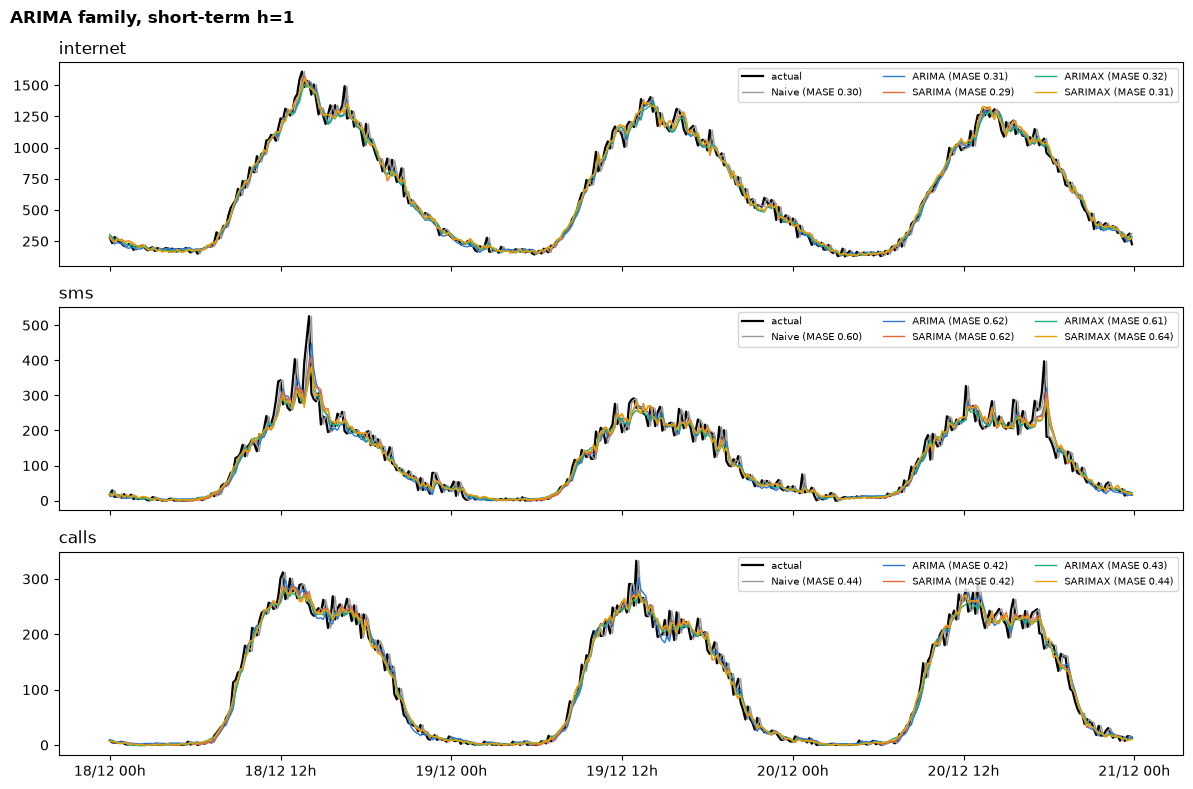

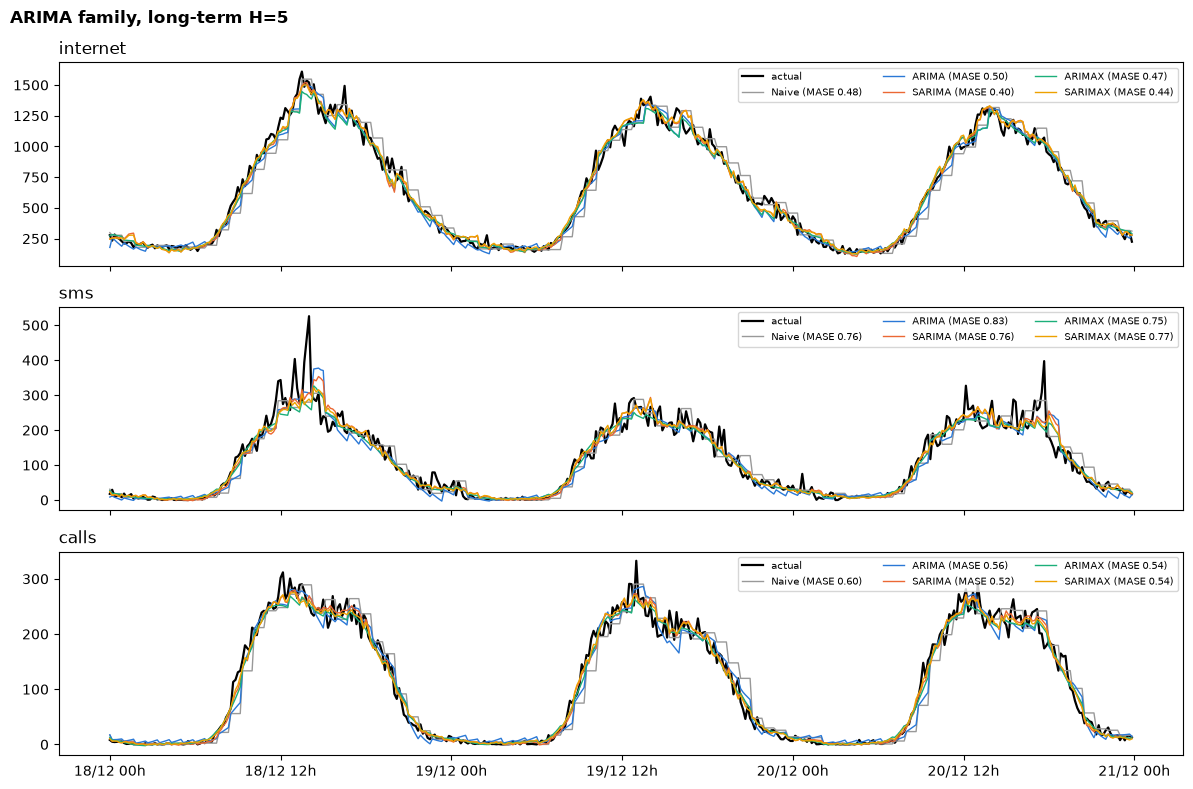

In [25]:
# Test set: actual vs ARIMA-family forecasts, 3-day zoom before Christmas
ZOOM = slice("2013-12-18", "2013-12-20")
FAM_COLOR = {"Naive": "0.6", "ARIMA": "#2a78d6", "SARIMA": "#eb6834", "ARIMAX": "#1baf7a", "SARIMAX": "#eda100"}
for h in (1, 5):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
    for ax, s in zip(axes, SERIES):
        act_ = df[s].loc[ZOOM]
        ax.plot(act_.index, act_.values, color="k", lw=1.6, label="actual")
        for m, c in FAM_COLOR.items():
            idx, yhat = PRED[(s, h)][m]
            ser = pd.Series(yhat, index=df.index[idx]).loc[ZOOM]
            ax.plot(ser.index, ser.values, color=c, lw=1, label=f"{m} (MASE {RESULTS.loc[(s, h, m), 'MASE']:.2f})")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=3, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"ARIMA family, {'short-term h=1' if h == 1 else 'long-term H=5'}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

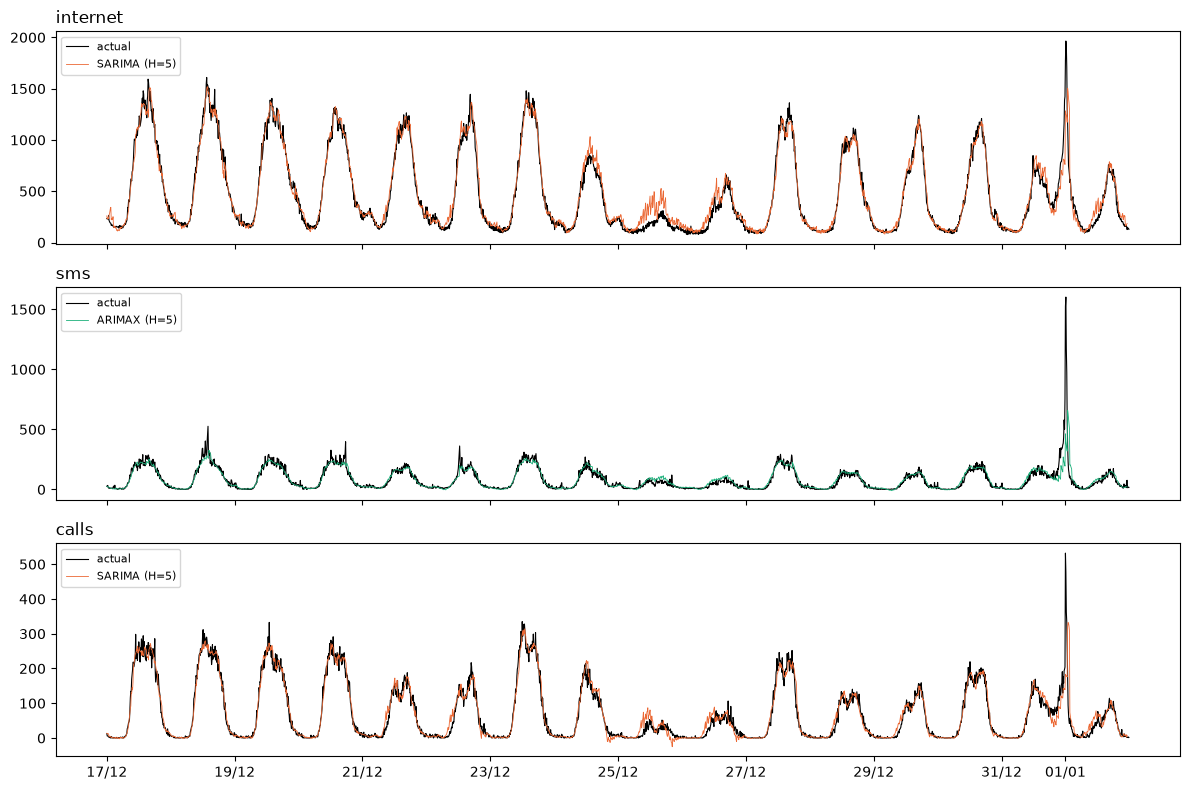

In [26]:
# Whole test set for the best ARIMA-family model per series (H=5), holidays included
fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
for ax, s in zip(axes, SERIES):
    best = RESULTS.loc[(s, 5)].drop(index=["Naive", "Seasonal naive"])["MASE"].idxmin()
    idx, yhat = PRED[(s, 5)][best]
    ax.plot(df.index[n_train:], Y[s][n_train:], color="k", lw=0.8, label="actual")
    ax.plot(df.index[idx], yhat, color=FAM_COLOR[best], lw=0.6, label=f"{best} (H=5)")
    ax.set_title(s, loc="left"); ax.legend(fontsize=8, loc="upper left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout(); plt.show()

**Ερμηνεία των αποτελεσμάτων**

MASE στο test ($h = 1$ / $H = 5$):

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| Naive | 0.302 / 0.480 | **0.602** / 0.759 | 0.438 / 0.599 |
| ARIMA | 0.307 / 0.495 | 0.619 / 0.827 | **0.417** / 0.564 |
| SARIMA | **0.287** / **0.403** | 0.621 / 0.759 | 0.418 / **0.522** |
| ARIMA-x | 0.317 / 0.472 | 0.608 / **0.751** | 0.425 / 0.538 |
| SARIMA-x | 0.309 / 0.442 | 0.642 / 0.771 | 0.443 / 0.545 |
| Seasonal naive | 1.136 / 1.122 | 1.496 / 1.463 | 1.459 / 1.447 |

1. **Στο $h = 1$ η απλή persistence (Naive) είναι πολύ δύσκολο να νικηθεί.** Σε 10 λεπτά η κίνηση αλλάζει λίγο, οπότε
   η τελευταία τιμή περιέχει ήδη σχεδόν όλη την πληροφορία. Τα μοντέλα ARIMA βελτιώνουν το Naive μόνο κατά 0% έως 5%,
   και στο SMS κανένα δεν το νικά.
2. **Στο $H = 5$ η εποχικότητα κάνει τη διαφορά.** Στο Internet το SARIMA (0.403) είναι σαφώς καλύτερο από το καθαρό
   ARIMA (0.495) και από το Naive (0.480). Ο πίνακας ανά lead δείχνει γιατί: το σφάλμα του SARIMA αυξάνεται περίπου
   75% από το lead 1 στο lead 5, ενώ του Naive και του καθαρού ARIMA περίπου διπλασιάζεται. Το καθαρό ARIMA «ξέρει»
   μόνο ότι η σειρά επιστρέφει στη μέση τιμή, οπότε στις ανόδους και τις καθόδους μένει πίσω (βλ. μεγέθυνση). Το
   SARIMA ξέρει ότι μετά τις 08:00 η κίνηση ανεβαίνει, γιατί το είδε χθες.
3. **Το SARIMA-x δεν απέδωσε όσο υπόσχονταν το BIC του train.** Οι εξωγενείς όροι (εβδομαδιαίο σχήμα, αργίες)
   περιγράφουν καλύτερα το train, αλλά στο test ο «κανόνας» άλλαξε: η Παραμονή των Χριστουγέννων και η 31/12 είναι
   τυπικά εργάσιμες αλλά συμπεριφέρονται σαν αργίες, και τα εορταστικά απογεύματα δεν μοιάζουν με τις Κυριακές του
   Νοεμβρίου. Αυτό είναι ένα παράδειγμα **distribution shift**: ένα μοντέλο που ταιριάζει καλύτερα στο παρελθόν δεν
   προβλέπει απαραίτητα καλύτερα ένα μέλλον που συμπεριφέρεται διαφορετικά.
4. **Η seasonal naive είναι η χειρότερη** (MASE πάνω από 1), ενώ στο train ορίζει τη μονάδα. Η ίδια μέθοδος αποδίδει
   χειρότερα στο test από ό,τι στο train, άλλη μία ένδειξη ότι το test είναι δυσκολότερο: «ό,τι έγινε χθες» είναι κακή
   πρόβλεψη για τα Χριστούγεννα.
5. **Δυσκολία ανά σειρά:** Internet (WAPE περίπου 7% έως 12%) είναι η ευκολότερη, μετά τα Calls (13% έως 18%) και
   τελευταίο το SMS (19% έως 26%). Το SMS είναι η πιο «εκρηκτική» σειρά: έχει απότομες, σύντομες αιχμές (μαζικά
   μηνύματα, Πρωτοχρονιά) που κανένα μοντέλο δεν μπορεί να προβλέψει από το ιστορικό του.

### 2.9 Συμπεράσματα για την οικογένεια ARIMA

* **Υπερπαράμετροι:** τα ADF/KPSS έδωσαν $d = 0$ (καμία τάση), η ACF έδειξε ισχυρή ημερήσια εποχικότητα ($D = 1$,
  $s = 144$) και η ACF/PACF της $\nabla_{144} y$ έδωσε $p \approx 3$ έως $6$ και $Q = 1$. Το BIC επιβεβαίωσε αυτά τα
  εύρη για τα εποχικά μοντέλα.
* **Η καθαρή ARIMA αποτυγχάνει στο περιοδικό μοτίβο,** όπως προέβλεπε η εκφώνηση: εξαντλεί το πλέγμα τάξεων, αφήνει
  ημερήσια αυτοσυσχέτιση στα κατάλοιπα και είναι η χειρότερη στο long-term.
* **Το s-ARIMA είναι το καλύτερο μοντέλο της οικογένειας στο long-term** για Internet και Calls. Η εποχική διαφόριση
  είναι ένας απλός και ανθεκτικός τρόπος να χρησιμοποιηθεί «η χθεσινή μέρα» ως πληροφορία.
* **Το ARIMA-x** με όρους Fourier πετυχαίνει παρόμοια απόδοση με πολύ μικρότερες τάξεις και είναι το καλύτερο στο SMS
  ($H = 5$). Οι πιο σύνθετες εξωγενείς μεταβλητές (εβδομαδιαίοι όροι, αργίες) βοήθησαν στο train αλλά όχι στο
  εορταστικό test.
* **Στο short-term** κανένα γραμμικό μοντέλο δεν απέχει πολύ από την απλή persistence. Το περιθώριο βελτίωσης βρίσκεται
  κυρίως στο long-term και στις ασυνήθιστες περιόδους.

## 3. Deep learning: LSTM

Η ενότητα αυτή εφαρμόζει ένα αναδρομικό νευρωνικό δίκτυο (LSTM) στο ίδιο πρόβλημα, με την **ίδια** διαδικασία
αποτίμησης (ίδιο train/test, ίδιοι ορίζοντες, ίδια σημεία του test, ίδιες μετρικές), ώστε η σύγκριση με την
οικογένεια ARIMA να είναι δίκαιη. Αυτό είναι και το ζητούμενο του άρθρου των Siami-Namini et al.

### 3.1 Θεωρία

#### 3.1.1 Από τα γραμμικά μοντέλα στα νευρωνικά δίκτυα

Η ARIMA είναι **γραμμική**: η πρόβλεψη είναι ένα σταθμισμένο άθροισμα προηγούμενων τιμών και διαταραχών. Ένα
νευρωνικό δίκτυο μαθαίνει μια **μη γραμμική** συνάρτηση $\hat y = f_\theta(\text{ιστορικό})$, με παραμέτρους $\theta$
που εκτιμώνται ελαχιστοποιώντας ένα σφάλμα στο train με gradient descent. Έτσι μπορεί, κατ' αρχήν, να μάθει σχέσεις
που η ARIMA δεν μπορεί να εκφράσει (π.χ. «η άνοδος είναι πιο απότομη τα πρωινά των εργάσιμων»). Το τίμημα είναι
πολλές περισσότερες παράμετροι, ανάγκη για περισσότερα δεδομένα και κίνδυνος υπερπροσαρμογής.

#### 3.1.2 Αναδρομικά δίκτυα (RNN)

Ένα RNN διαβάζει την ακολουθία ένα βήμα τη φορά και κρατά μια **κρυφή κατάσταση** $h_t$, που λειτουργεί σαν μνήμη
όσων έχει δει ως τώρα:

$$h_t = \tanh\!\big(W x_t + U h_{t-1} + b\big)$$

Οι ίδιοι πίνακες $W, U$ χρησιμοποιούνται σε κάθε βήμα, οπότε το δίκτυο εφαρμόζει τον ίδιο «κανόνα ενημέρωσης» σε
όλη την ακολουθία, όπως ακριβώς η ARIMA εφαρμόζει τους ίδιους συντελεστές σε κάθε $t$. Η πρόβλεψη βγαίνει από την
τελευταία κατάσταση: $\hat y = V h_t + c$.

**Το πρόβλημα των εξαφανιζόμενων gradients.** Η εκπαίδευση γίνεται με *Backpropagation Through Time*: το gradient του
σφάλματος ως προς μια κατάσταση $k$ βήματα πίσω είναι γινόμενο $k$ Ιακωβιανών:

$$\frac{\partial h_t}{\partial h_{t-k}} \;=\; \prod_{j=0}^{k-1} \frac{\partial h_{t-j}}{\partial h_{t-j-1}} \;=\; \prod_{j=0}^{k-1} \operatorname{diag}\!\big(1 - h_{t-j}^2\big)\, U$$

Αν οι παράγοντες έχουν μέτρο μικρότερο από 1, το γινόμενο **μηδενίζεται εκθετικά** (vanishing gradient) και το δίκτυο
δεν μπορεί να μάθει εξαρτήσεις από μακρινό παρελθόν. Αν έχουν μέτρο μεγαλύτερο από 1, **εκρήγνυται** (exploding
gradient) και η εκπαίδευση γίνεται ασταθής. Στο πρόβλημά μας αυτό έχει σημασία: για $w = 144$ το δίκτυο πρέπει να
συνδέσει την τρέχουσα τιμή με τιμές μιας ολόκληρης ημέρας πριν.

#### 3.1.3 LSTM (Hochreiter και Schmidhuber, 1997)

Το LSTM λύνει το πρόβλημα προσθέτοντας μια δεύτερη κατάσταση, την **κατάσταση κελιού** $c_t$ (μακροπρόθεσμη μνήμη), και
τρεις **πύλες** που αποφασίζουν τι ξεχνιέται, τι γράφεται και τι διαβάζεται. Κάθε πύλη είναι ένα διάνυσμα με τιμές στο
$(0, 1)$, μέσω της σιγμοειδούς $\sigma(x) = 1 / (1 + e^{-x})$, και πολλαπλασιάζεται στοιχείο προς στοιχείο ($\odot$):

$$
\begin{aligned}
f_t &= \sigma\big(W_f x_t + U_f h_{t-1} + b_f\big) && \text{forget gate: πόσο από την παλιά μνήμη κρατάμε} \\[3pt]
i_t &= \sigma\big(W_i x_t + U_i h_{t-1} + b_i\big) && \text{input gate: πόση νέα πληροφορία γράφουμε} \\[3pt]
\tilde c_t &= \tanh\big(W_c x_t + U_c h_{t-1} + b_c\big) && \text{υποψήφια νέα πληροφορία} \\[3pt]
c_t &= f_t \odot c_{t-1} \;+\; i_t \odot \tilde c_t && \text{ενημέρωση της μνήμης} \\[3pt]
o_t &= \sigma\big(W_o x_t + U_o h_{t-1} + b_o\big) && \text{output gate: τι από τη μνήμη δίνουμε ως έξοδο} \\[3pt]
h_t &= o_t \odot \tanh(c_t) && \text{νέα κρυφή κατάσταση}
\end{aligned}
$$

**Γιατί δουλεύει.** Η ενημέρωση της μνήμης $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$ είναι **προσθετική**. Το
gradient από το $c_t$ προς το $c_{t-1}$ είναι απλώς $f_t$, όχι γινόμενο με έναν πίνακα βαρών και μια παράγωγο
$\tanh$. Όταν το δίκτυο μάθει $f_t \approx 1$, η πληροφορία και το gradient περνούν πολλά βήματα σχεδόν
αναλλοίωτα. Οι πύλες μαθαίνονται από τα δεδομένα, οπότε το δίκτυο αποφασίζει μόνο του τι αξίζει να θυμάται (π.χ. «η
κίνηση ανεβαίνει εδώ και μία ώρα») και τι να ξεχάσει.

### 3.2 Διατύπωση ως πρόβλημα επιβλεπόμενης μάθησης

Το δίκτυο δεν «καταλαβαίνει» χρονοσειρές. Του δίνουμε ζεύγη εισόδου και στόχου, που κατασκευάζουμε κόβοντας τη σειρά
σε **παράθυρα** μήκους $w$:

$$\underbrace{(y_{t-w},\; \dots,\; y_{t-1})}_{\text{είσοδος: τελευταίες } w \text{ τιμές}} \;\longmapsto\; \underbrace{(y_t,\; \dots,\; y_{t+h-1})}_{\text{στόχος: επόμενες } h \text{ τιμές}}$$

**Μέγεθος παραθύρου $w$.** Εδώ, σε αντίθεση με την ARIMA, το $w$ είναι πραγματική υπερπαράμετρος: το δίκτυο βλέπει
**μόνο** όσα είναι μέσα στο παράθυρο. Δοκιμάζουμε δύο τιμές:
* $w = 10$ (100 λεπτά), η τιμή που προτείνει η εκφώνηση. Το δίκτυο βλέπει μόνο την πρόσφατη πορεία.
* $w = 144$ (24 ώρες). Το παράθυρο περιέχει ολόκληρη την προηγούμενη ημέρα, μαζί με την τιμή $y_{t-144}$ της ίδιας
  ώρας χθες. Έτσι το δίκτυο **μπορεί** να μάθει την ημερήσια περιοδικότητα, όπως το SARIMA.

**Πρόβλεψη πέντε βημάτων: direct multi-output (MIMO).** Για $H = 5$ το δίκτυο έχει 5 εξόδους και προβλέπει και τα 5
βήματα **ταυτόχρονα**. Η εναλλακτική είναι η αναδρομική πρόβλεψη της ARIMA (προβλέπουμε ένα βήμα και το ξαναδίνουμε
ως είσοδο). Επιλέγουμε MIMO γιατί:
* τα σφάλματα **δεν συσσωρεύονται**: στην αναδρομική πρόβλεψη ένα λάθος στο βήμα 1 γίνεται είσοδος για το βήμα 2,
* το δίκτυο εκπαιδεύεται απευθείας στον στόχο που μας ενδιαφέρει (5 βήματα μπροστά),
* είναι ο φυσικός τρόπος χρήσης ενός νευρωνικού δικτύου: μία έξοδος ανά βήμα, ένα πέρασμα.

Για $h = 1$ οι δύο στρατηγικές ταυτίζονται. Η διαφορά στρατηγικής από την ARIMA είναι ένα από τα πράγματα που
συγκρίνουμε.

### 3.3 Κανονικοποίηση min-max στο $[0, 1]$

Πριν μπουν στο δίκτυο, οι τιμές μετασχηματίζονται γραμμικά ώστε το train να καταλαμβάνει ακριβώς το $[0, 1]$, και στην
έξοδο εφαρμόζεται ο αντίστροφος μετασχηματισμός:

$$\tilde y_t = \frac{y_t - y_{\min}}{y_{\max} - y_{\min}} \qquad\qquad \hat y_t = \hat{\tilde y}_t \,\big(y_{\max} - y_{\min}\big) + y_{\min}$$

**Γιατί χρειάζεται** (η ARIMA δεν το χρειάζεται, αφού είναι γραμμική και ανεξάρτητη της κλίμακας):
* **Κορεσμός των ενεργοποιήσεων.** Οι $\sigma$ και $\tanh$ των πυλών έχουν παράγωγο σχεδόν μηδέν για μεγάλες εισόδους.
  Με τιμές της τάξης του 1000 (Internet) οι πύλες θα «κολλούσαν» στο 0 ή στο 1 και το δίκτυο δεν θα μάθαινε τίποτα.
* **Κλίμακα των gradients.** Τα βάρη αρχικοποιούνται για εισόδους κλίμακας περίπου 1, και ο Adam με learning rate
  $10^{-3}$ υποθέτει επίσης τέτοια κλίμακα. Χωρίς κανονικοποίηση τα βήματα θα ήταν ακατάλληλα μεγάλα ή μικρά.
* **Ίδια ρύθμιση για όλες τις σειρές.** Μετά την κανονικοποίηση Internet, SMS και Calls έχουν την ίδια κλίμακα, οπότε η
  ίδια αρχιτεκτονική και τα ίδια hyperparameters ταιριάζουν και στις τρεις.

**Γιατί τα $y_{\min}, y_{\max}$ υπολογίζονται μόνο στο train.** Αν χρησιμοποιούσαμε όλη τη σειρά, η κανονικοποίηση θα
«ήξερε» το μέγιστο του test (την αιχμή της Πρωτοχρονιάς), δηλαδή πληροφορία από το μέλλον (διαρροή). Συνέπεια: στο test
οι κανονικοποιημένες τιμές μπορεί να βγουν έξω από το $[0, 1]$. Αυτό δεν είναι πρόβλημα, γιατί η είσοδος του LSTM δεν
περιορίζεται και η έξοδος (γραμμικό στρώμα) μπορεί να πάρει οποιαδήποτε τιμή. Αντανακλά απλώς την πραγματικότητα: το
test περιέχει τιμές που δεν εμφανίστηκαν στο train.

### 3.4 Από-περιοδικοποίηση (deseasonalisation)

Η εκφώνηση προτείνει να αφαιρέσουμε την περιοδικότητα πριν από το δίκτυο και να την επαναφέρουμε στο τέλος. Ορίζουμε
το **εποχικό προφίλ** $S_t$ ως τη μέση τιμή του train για τον ίδιο τύπο ημέρας και το ίδιο δεκάλεπτο της ημέρας
(το προφίλ που είδαμε στην EDA, ενότητα 1.4):

$$S_t \;=\; \operatorname{mean}\big\{\, y_\tau \;:\; \tau \in \text{train},\;\; \text{daytype}(\tau) = \text{daytype}(t),\;\; \text{slot}(\tau) = \text{slot}(t) \,\big\}$$

Το δίκτυο μοντελοποιεί το **υπόλοιπο** και στο τέλος προσθέτουμε πίσω το προφίλ:

$$r_t = y_t - S_t \qquad\longrightarrow\qquad \text{LSTM} \qquad\longrightarrow\qquad \hat y_t = \hat r_t + S_t$$

Η κανονικοποίηση min-max εφαρμόζεται στο $r_t$ σε αυτή την περίπτωση. Το $S_t$ είναι γνωστό για κάθε μελλοντική στιγμή
(εξαρτάται μόνο από την ημερομηνία και την ώρα), οπότε η επαναφορά είναι πάντα δυνατή.

**Γιατί μπορεί να βοηθήσει:**
* Το δίκτυο δεν χρειάζεται να μάθει το ημερήσιο σχήμα, που είναι το μεγαλύτερο και πιο προβλέψιμο μέρος της
  σειράς. Εστιάζει στις **αποκλίσεις** από το κανονικό μοτίβο.
* Για $w = 10$ αυτό είναι κρίσιμο: η περίοδος (144) είναι πολύ μεγαλύτερη από το παράθυρο, οπότε χωρίς το $S_t$ το
  δίκτυο δεν έχει τρόπο να ξέρει ότι σε μία ώρα έρχεται η μεσημεριανή αιχμή.
* Είναι η ίδια ιδέα με το ARIMA-x: ένα ντετερμινιστικό μέρος για την περιοδικότητα και ένα στοχαστικό μοντέλο για
  το υπόλοιπο.

**Πότε μπορεί να βλάψει:** όταν το πραγματικό μοτίβο στο test διαφέρει από αυτό του train. Τότε το $S_t$ είναι λάθος
και το υπόλοιπο $r_t$ στο test έχει τιμές πολύ έξω από αυτές που είδε το δίκτυο στην εκπαίδευση. Η εορταστική
περίοδος του test είναι ακριβώς τέτοια περίπτωση, οπότε το αποτέλεσμα δεν είναι προφανές εκ των προτέρων.

### 3.5 Αρχιτεκτονική και εκπαίδευση

| Επιλογή | Τιμή | Γιατί |
|:---|:---|:---|
| Αρχιτεκτονική | 2 στρώματα LSTM, 64 μονάδες, και ένα γραμμικό στρώμα $64 \to h$ | δύο στρώματα επιτρέπουν ιεραρχία (το πρώτο βλέπει τοπικά μοτίβα, το δεύτερο συνδυάζει). 64 μονάδες (περίπου 50 χιλιάδες παράμετροι) αρκούν για μία σειρά με περίπου 6500 σημεία χωρίς να την απομνημονεύουν |
| Έξοδος | η κατάσταση $h_t$ του τελευταίου βήματος, μέσω γραμμικού στρώματος | η $h_t$ συνοψίζει όλο το παράθυρο. Γραμμική έξοδος, για να μπορεί να βγάλει και τιμές έξω από το $[0,1]$ |
| Dropout | 0.1 ανάμεσα στα δύο στρώματα | μηδενίζει τυχαία μέρος των ενεργοποιήσεων στην εκπαίδευση, ώστε το δίκτυο να μη στηρίζεται σε λίγες μονάδες (κανονικοποίηση κατά της υπερπροσαρμογής) |
| Loss | MSE στην κανονικοποιημένη κλίμακα | ομαλή και παραγωγίσιμη, και αντιστοιχεί στο RMSE: τιμωρεί έντονα τις χαμένες αιχμές |
| Optimizer | Adam, learning rate $10^{-3}$, batch 128 | ο Adam προσαρμόζει το βήμα κάθε παραμέτρου χωριστά και είναι η τυπική, ανθεκτική επιλογή για RNN. Τα mini-batches δίνουν θορυβώδη αλλά γρήγορα βήματα, που βοηθούν και τη γενίκευση |
| Gradient clipping | νόρμα το πολύ 1 | προστασία από τα exploding gradients της ενότητας 3.1.2 |
| Validation | το τελευταίο 10% του train (περίπου 4.6 ημέρες), **χρονολογικά** | ο έλεγχος γενίκευσης πρέπει να γίνεται, όπως και το test, σε δεδομένα που έρχονται **μετά** από αυτά της εκπαίδευσης. Το test δεν χρησιμοποιείται ποτέ για αποφάσεις |
| Early stopping | σταματάμε αν το validation loss δεν βελτιωθεί για 8 εποχές, και κρατάμε τα καλύτερα βάρη | το training loss μειώνεται πάντα, ενώ το validation loss σταματά να πέφτει όταν το δίκτυο αρχίζει να απομνημονεύει. Εκεί σταματάμε |
| Seed | σταθερό (0) | αναπαραγωγιμότητα: η αρχικοποίηση και η σειρά των batches είναι τυχαίες |

Τα παράθυρα του train ανακατεύονται σε κάθε εποχή. Αυτό **δεν** είναι διαρροή: κάθε παράθυρο είναι αυτόνομο δείγμα
(είσοδος από το παρελθόν, στόχος αμέσως μετά), και το ανακάτεμα απλώς αποτρέπει το δίκτυο από το να μάθει τη σειρά
των batches.

**Πειράματα:** 3 σειρές $\times$ 2 παράθυρα ($w = 10, 144$) $\times$ 2 εκδοχές (raw, από-περιοδικοποιημένη) $\times$ 2
ορίζοντες ($h = 1$, $H = 5$) $= 24$ δίκτυα. Εκπαιδεύονται παράλληλα (κάθε δίκτυο σε δικό του worker με 4 threads).
Επειδή η εκπαίδευση παίρνει λίγα λεπτά, τα αποτελέσματα αποθηκεύονται στο `results/lstm_notebook.pkl` και
φορτώνονται από εκεί στις επόμενες εκτελέσεις. Για νέα εκπαίδευση: `RETRAIN = True` ή διαγραφή του αρχείου.

In [ ]:
import os
import joblib
import torch
import torch.nn as nn
from joblib import parallel_config

SEED = 0
LSTM_WINDOWS = (10, 144)


def seasonal_profile(idx, y, n_fit):
    """S_t: mean per (day type, 10-min slot), computed on the first n_fit points (the train set)."""
    key = day_type(idx) * SEASON + (idx.hour * 6 + idx.minute // 10).values
    means = pd.Series(y[:n_fit]).groupby(key[:n_fit]).mean()
    return means.reindex(key).values


class LSTMNet(nn.Module):
    def __init__(self, horizon, hidden=64, layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x):                      # x: (batch, w, 1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1])           # state of the last time step -> h outputs


def make_windows(z, targets, w, h):
    """Inputs z[t-w:t] and targets z[t:t+h] for every t in targets."""
    X = np.stack([z[t - w:t] for t in targets])[..., None].astype(np.float32)
    Yw = np.stack([z[t:t + h] for t in targets]).astype(np.float32)
    return torch.from_numpy(X), torch.from_numpy(Yw)

In [ ]:
def run_lstm(s, w, deseason, h, seed=SEED, max_epochs=80, patience=8, threads=4):
    torch.set_num_threads(threads); torch.manual_seed(seed); np.random.seed(seed)
    y = Y[s]
    S = seasonal_profile(df.index, y, n_train) if deseason else np.zeros_like(y)
    r = y - S
    lo, hi = r[:n_train].min(), r[:n_train].max()           # min-max from the train set only
    z = (r - lo) / (hi - lo)

    # training windows; the last 10% (in time) is the validation set
    targets = np.arange(w, n_train - h + 1)
    n_val = int(0.1 * len(targets))
    Xtr, Ytr = make_windows(z, targets[:-n_val], w, h)
    Xva, Yva = make_windows(z, targets[-n_val:], w, h)

    net = LSTMNet(h)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lossf = nn.MSELoss()
    best, best_state, bad, hist = np.inf, None, 0, []
    t0 = time.perf_counter()
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 128):
            b = perm[i:i + 128]
            opt.zero_grad()
            loss = lossf(net(Xtr[b]), Ytr[b])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        net.eval()
        with torch.no_grad():
            tr_loss = lossf(net(Xtr), Ytr).item()
            va_loss = lossf(net(Xva), Yva).item()
        hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-7:                             # early stopping on the validation loss
            best, bad = va_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    train_seconds = time.perf_counter() - t0
    net.load_state_dict(best_state); net.eval()

    # Rolling evaluation on the test set: the input is always the last w ACTUAL values
    origins = np.arange(n_train, N) if h == 1 else np.arange(n_train, N - h + 1, h)
    Xte, _ = make_windows(np.r_[z, np.zeros(h)], origins, w, h)
    with torch.no_grad():
        zhat = net(Xte).numpy()
    tidx = origins[:, None] + np.arange(h)[None, :]
    yhat = (zhat * (hi - lo) + lo + S[tidx]).ravel()          # inverse min-max, then add the profile back
    return {"pred": yhat, "origins": origins, "history": hist, "epochs": len(hist),
            "best_epoch": int(np.argmin([v for _, v in hist])) + 1, "train_seconds": train_seconds,
            "params": sum(p.numel() for p in net.parameters())}

In [ ]:
RETRAIN = False
LSTM_FILE = "results/lstm_notebook.pkl"
LSTM_JOBS = [(s, w, ds, h) for s in SERIES for w in LSTM_WINDOWS for ds in (False, True) for h in (H_SHORT, H_LONG)]

if RETRAIN or not os.path.exists(LSTM_FILE):
    t0 = time.perf_counter()
    with parallel_config(backend="loky", inner_max_num_threads=4):    # 12 workers x 4 threads
        out = Parallel(n_jobs=12)(delayed(run_lstm)(*j) for j in LSTM_JOBS)
    LSTM_RES = dict(zip(LSTM_JOBS, out))
    joblib.dump(LSTM_RES, LSTM_FILE)
    print(f"trained {len(LSTM_JOBS)} networks in {time.perf_counter() - t0:.0f}s")
else:
    LSTM_RES = joblib.load(LSTM_FILE)
    print("loaded", LSTM_FILE)

pd.DataFrame([{"series": s, "w": w, "deseason": ds, "h": h, "params": v["params"], "epochs": v["epochs"],
               "best epoch": v["best_epoch"], "train (s)": round(v["train_seconds"])}
              for (s, w, ds, h), v in LSTM_RES.items()]).set_index(["series", "w", "deseason", "h"])

**Καμπύλες εκμάθησης.** Το validation loss ανά εποχή (λογαριθμική κλίμακα) για $h = 1$. Δείχνει αν η εκπαίδευση
συγκλίνει, πόσο γρήγορα, και πού σταμάτησε το early stopping. Οι συγκρίσεις ανάμεσα σε raw και από-περιοδικοποιημένη
εκδοχή εδώ **δεν** είναι άμεσες, γιατί η κανονικοποίηση γίνεται σε διαφορετικά μεγέθη ($y$ ή $r$).

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    for (w, ds), c in zip([(10, False), (10, True), (144, False), (144, True)],
                          ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
        hst = np.array(LSTM_RES[(s, w, ds, 1)]["history"])
        ax.plot(np.arange(1, len(hst) + 1), hst[:, 1], color=c, label=f"w={w}, {'deseason' if ds else 'raw'}")
    ax.set_yscale("log"); ax.set_title(s, loc="left"); ax.set_xlabel("epoch")
axes[0].set_ylabel("validation MSE ([0,1] scale)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [ ]:
# Best validation loss converted back to the original units, so raw and deseason are comparable
# (with deseasonalisation S_t is added back exactly, so the error of r equals the error of y)
val = {}
for (s, w, ds, h), v in LSTM_RES.items():
    y = Y[s]
    r = y - (seasonal_profile(df.index, y, n_train) if ds else 0.0)
    rng = r[:n_train].max() - r[:n_train].min()
    val[(s, h, f"LSTM w={w}" + (" deseason" if ds else ""))] = np.sqrt(min(va for _, va in v["history"])) * rng
pd.Series(val).unstack().round(1).rename_axis(["series", "h"])

**Ερμηνεία της εκπαίδευσης**

* **Όλα τα δίκτυα συγκλίνουν.** Η καλύτερη εποχή είναι από 10 έως 65 και το early stopping σταματά 8 εποχές αργότερα,
  πολύ πριν από το όριο των 80. Οι καμπύλες πέφτουν γρήγορα στις πρώτες 10 εποχές και μετά σταθεροποιούνται.
* **Το $w = 144$ κοστίζει περίπου 10 φορές περισσότερο** (περίπου 300 έως 850 s ανά δίκτυο, έναντι 30 έως 120 s για
  $w = 10$). Ο λόγος είναι ότι το backpropagation through time ξετυλίγει το δίκτυο σε 144 βήματα αντί για 10.
* **Στο validation η από-περιοδικοποίηση βοηθά σε όλες τις περιπτώσεις.** Το RMSE στις αρχικές μονάδες μειώνεται κατά
  8% έως 17% για $h = 1$ (π.χ. Internet, $w = 144$: 48.9 έναντι 57.5) και κατά 14% έως 31% για $H = 5$. Με βάση όσα ξέρουμε **πριν** από το test, η
  από-περιοδικοποιημένη εκδοχή θα ήταν επομένως η λογική επιλογή. Το validation όμως είναι οι τελευταίες 4.6 ημέρες
  του train (11/12 έως 16/12), δηλαδή κανονικές ημέρες. Θα δούμε παρακάτω ότι στο test η εικόνα αλλάζει.

### 3.6 Rolling-window αποτίμηση και σύγκριση με την ARIMA

Η αποτίμηση ακολουθεί **ακριβώς** τον ψευδοκώδικα της ενότητας 2.7: σε κάθε αφετηρία $t$ του test η είσοδος του
δικτύου είναι οι τελευταίες $w$ **πραγματικές** τιμές $(y_{t-w}, \dots, y_{t-1})$, δηλαδή το `history.append(y_t)`
του ψευδοκώδικα. Τα βάρη μένουν σταθερά (εκπαιδεύτηκαν μόνο στο train), όπως και οι παράμετροι της ARIMA.
Χρησιμοποιούμε τις **ίδιες αφετηρίες** ($h = 1$: κάθε σημείο, $H = 5$: ανά 5 βήματα), οπότε κάθε μοντέλο
αξιολογείται στα ίδια ακριβώς σημεία με τις ίδιες μετρικές.

Το επόμενο κελί προσθέτει τα 12 LSTM (ανά σειρά) στις προβλέψεις της ενότητας 2.8 και υπολογίζει ξανά τον πίνακα
αποτελεσμάτων για όλα τα μοντέλα μαζί.

In [ ]:
for (s, w, ds, h), v in LSTM_RES.items():
    name = f"LSTM w={w}" + (" deseason" if ds else "")
    PRED[(s, h)][name] = (idx1 if h == 1 else idx5, v["pred"])

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
RESULTS = pd.DataFrame(rows).set_index(["series", "h", "model"])

# MASE for every model, series and horizon (lowest per column highlighted)
mase = RESULTS["MASE"].unstack(["series", "h"])[[(s, h) for s in SERIES for h in (1, 5)]]
mase = mase.loc[list(PRED[(SERIES[0], 1)].keys())]
display(mase.style.format("{:.3f}").highlight_min(color="#d6e6f9"))

wape = RESULTS["WAPE %"].unstack(["series", "h"])[[(s, h) for s in SERIES for h in (1, 5)]].loc[mase.index]
print("WAPE %"); wape.round(1)

In [ ]:
# MASE per lead step (H=5): best ARIMA-family model vs the LSTMs
fam_names = ["Naive", "ARIMA", "SARIMA", "ARIMAX", "SARIMAX"]
lead = {}
for s in SERIES:
    for m, (idx, yhat) in PRED[(s, 5)].items():
        if m in fam_names or m.startswith("LSTM"):
            lead[(s, m)] = np.abs(Y[s][idx] - yhat).reshape(-1, H_LONG).mean(axis=0) / MASE_SCALE[s]
pd.DataFrame(lead, index=[f"lead {j+1}" for j in range(H_LONG)]).T.round(3)

**Απεικονίσεις.** Η ίδια μεγέθυνση τριών εργάσιμων ημερών (18/12 έως 20/12) με το καλύτερο μοντέλο της οικογένειας
ARIMA, το καλύτερο raw LSTM και το καλύτερο από-περιοδικοποιημένο LSTM. Μετά η εορταστική περίοδος (24/12 έως 01/01),
όπου φαίνεται πώς αντιδρά κάθε προσέγγιση σε συμπεριφορά που δεν έχει δει.

In [ ]:
def best_model(s, h, prefix_ok):
    sub = RESULTS.loc[(s, h), "MASE"]
    return sub[[m for m in sub.index if prefix_ok(m)]].idxmin()


PICK = {"ARIMA family": lambda m: m in ("ARIMA", "SARIMA", "ARIMAX", "SARIMAX"),
        "LSTM raw": lambda m: m.startswith("LSTM") and "deseason" not in m,
        "LSTM deseason": lambda m: m.startswith("LSTM") and "deseason" in m}
PICK_COLOR = {"ARIMA family": "#eb6834", "LSTM raw": "#2a78d6", "LSTM deseason": "#1baf7a"}

for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2014-01-01"), "holidays 24/12 - 01/01")]:
    for h in (1, 5):
        fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
        for ax, s in zip(axes, SERIES):
            act_ = df[s].loc[period]
            ax.plot(act_.index, act_.values, color="k", lw=1.4, label="actual")
            for grp, ok in PICK.items():
                m = best_model(s, h, ok)
                idx, yhat = PRED[(s, h)][m]
                ser = pd.Series(yhat, index=df.index[idx]).loc[period]
                ax.plot(ser.index, ser.values, color=PICK_COLOR[grp], lw=0.9,
                        label=f"{m} (MASE {RESULTS.loc[(s, h, m), 'MASE']:.2f})")
            ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
        fig.suptitle(f"{title}, {'h=1' if h == 1 else 'H=5'}", x=0.01, ha="left", fontweight="bold")
        fig.tight_layout(); plt.show()

**Κανονικές ημέρες ή γιορτές;** Για να καταλάβουμε τη συμπεριφορά της από-περιοδικοποίησης, χωρίζουμε το test σε
δύο μέρη: κανονικές ημέρες (17/12 έως 23/12) και εορταστική περίοδο (24/12 έως 01/01), και υπολογίζουμε τη MASE
χωριστά σε καθένα. Υπολογίζουμε επίσης πόσο μεγαλώνει η διασπορά του υπολοίπου $r_t = y_t - S_t$ από το train στο test.

In [ ]:
cut = df.index.get_loc(pd.Timestamp("2013-12-24"))
show = ["Naive", "SARIMA", "LSTM w=10", "LSTM w=144", "LSTM w=10 deseason", "LSTM w=144 deseason"]
rows = []
for s in SERIES:
    for h in (1, 5):
        for m in show:
            idx, yhat = PRED[(s, h)][m]
            e = np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]
            rows.append({"series": s, "h": h, "model": m,
                         "normal days": e[idx < cut].mean(), "holidays": e[idx >= cut].mean()})
split = pd.DataFrame(rows).set_index(["series", "h", "model"]).unstack(["series", "h"])
display(split.loc[show].round(3))

# How much wider is the residual r_t = y_t - S_t in the test set than in the train set?
for s in SERIES:
    S = seasonal_profile(df.index, Y[s], n_train)
    r = Y[s] - S
    lo, hi = r[:n_train].min(), r[:n_train].max()
    z = (r[n_train:] - lo) / (hi - lo)
    print(f"{s:9s} std(r): train {r[:n_train].std():6.1f}, test {r[n_train:].std():6.1f} "
          f"(x{r[n_train:].std() / r[:n_train].std():.1f}); test points outside [0, 1]: {100 * np.mean((z < 0) | (z > 1)):.1f}%")

### 3.7 Ερμηνεία των αποτελεσμάτων του LSTM

MASE στο test ($h = 1$ / $H = 5$), μαζί με το Naive και το καλύτερο μοντέλο της οικογένειας ARIMA:

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| Naive | 0.302 / 0.480 | 0.602 / 0.759 | 0.438 / 0.599 |
| καλύτερο ARIMA | 0.287 / **0.403** (SARIMA) | 0.608 / 0.751 (ARIMA-x) | 0.417 / 0.522 (ARIMA / SARIMA) |
| LSTM $w = 10$ | 0.277 / 0.453 | **0.597** / **0.734** | **0.415** / 0.552 |
| LSTM $w = 144$ | **0.276** / 0.452 | 0.606 / 0.770 | 0.417 / **0.510** |
| LSTM $w = 10$, deseason | 0.420 / 0.593 | 0.640 / 0.810 | 0.481 / 0.615 |
| LSTM $w = 144$, deseason | 0.395 / 0.617 | 0.645 / 0.830 | 0.486 / 0.608 |

1. **Short-term ($h = 1$): το raw LSTM είναι το καλύτερο μοντέλο σε όλες τις σειρές**, αλλά με μικρή διαφορά. Στο
   Internet βελτιώνει το Naive κατά 9% και το SARIMA κατά 4%. Στο SMS είναι το **μόνο** μοντέλο που νικά το Naive,
   οριακά (0.597 έναντι 0.602). Στα Calls ισοβαθμεί με την ARIMA. Όπως και στην ενότητα 2.8, σε ορίζοντα 10 λεπτών η
   τελευταία τιμή περιέχει σχεδόν όλη την πληροφορία και το περιθώριο για οποιοδήποτε μοντέλο είναι μικρό.
2. **Long-term ($H = 5$): κανένας νικητής παντού.** Το LSTM είναι καλύτερο στα SMS ($w = 10$: 0.734 έναντι 0.751) και
   στα Calls ($w = 144$: 0.510 έναντι 0.522), ενώ στο Internet το SARIMA μένει σαφώς καλύτερο (0.403 έναντι 0.452). Ο
   πίνακας ανά lead δείχνει ότι στο Internet το σφάλμα του LSTM σχεδόν διπλασιάζεται από το lead 1 στο lead 5 (0.316
   σε 0.618), ενώ του SARIMA αυξάνεται περίπου 75%. Η direct στρατηγική δεν εμποδίζει από μόνη της τη χειροτέρευση:
   για το Internet, η γνώση του «τι έγινε χθες αυτή την ώρα» που έχει ενσωματωμένη το SARIMA αξίζει περισσότερο.
3. **$w = 10$ ή $w = 144$;** Αποδίδουν σχεδόν ίδια στο $h = 1$ (Internet 0.277 και 0.276). Στο $H = 5$ το μεγάλο
   παράθυρο βοηθά στα Calls (0.510 έναντι 0.552) αλλά όχι στα SMS. Για τόσο μικρούς ορίζοντες τα τελευταία 100 λεπτά
   αρκούν σε μεγάλο βαθμό: το επίπεδο και η κλίση της πρόσφατης κίνησης «προδίδουν» και την ώρα της ημέρας. Αφού το
   $w = 144$ κοστίζει 10 φορές περισσότερο στην εκπαίδευση, το $w = 10$ είναι η πιο αποδοτική επιλογή.
4. **Η από-περιοδικοποίηση: βοηθά στις κανονικές ημέρες, αποτυγχάνει στις γιορτές.** Συνολικά στο test είναι
   χειρότερη (π.χ. Internet $h = 1$: 0.42 έναντι 0.28), παρότι στο validation ήταν καλύτερη. Ο διαχωρισμός του test το
   εξηγεί:
   * **Κανονικές ημέρες (17/12 έως 23/12):** η από-περιοδικοποιημένη εκδοχή είναι ίση ή καλύτερη από το raw LSTM. Στο
     SMS, $H = 5$, πετυχαίνει 0.62, **το καλύτερο αποτέλεσμα από όλα τα μοντέλα** (SARIMA 0.645), στα Calls, $H = 5$, φτάνει
     το SARIMA (0.491 έναντι 0.495) και στο Internet το πλησιάζει (0.398 έναντι 0.365). Στο $h = 1$ είναι το καλύτερο
     μοντέλο για SMS (0.548) και Calls (0.428).
   * **Εορταστική περίοδος (24/12 έως 01/01):** η MASE σχεδόν διπλασιάζεται (Internet $H = 5$: 0.75 έως 0.79, έναντι
     0.43 έως 0.49 για το raw LSTM). Το προφίλ $S_t$ υπολογίστηκε στο train και περιγράφει τον «κανονικό» Νοέμβριο και
     Δεκέμβριο. Η Παραμονή και η 31/12 είναι τυπικά εργάσιμες, οπότε το $S_t$ περιμένει μια κανονική εργάσιμη, και
     ακόμη και το προφίλ της Κυριακής απέχει πολύ από τα Χριστούγεννα. Το υπόλοιπο $r_t$ στο test έχει **2.2 έως 3.4
     φορές** μεγαλύτερη τυπική απόκλιση από ό,τι στο train, και 3% έως 6% των τιμών του πέφτουν έξω από το διάστημα
     $[0, 1]$ της κανονικοποίησης. Το δίκτυο καλείται να προβλέψει αποκλίσεις πολύ μεγαλύτερες από όσες είδε ποτέ.
   * Το raw LSTM, αντίθετα, απλώς ακολουθεί το πρόσφατο πραγματικό επίπεδο μέσα στο παράθυρό του, οπότε προσαρμόζεται
     αυτόματα όταν η κίνηση πέφτει.

   **Συμπέρασμα για την από-περιοδικοποίηση,** όπως ζητά η εκφώνηση («δοκιμάστε ανάλογα»): βελτιώνει την πρόβλεψη όταν
   η περιοδικότητα του μέλλοντος μοιάζει με αυτή του παρελθόντος, και τη χειροτερεύει όταν το μοτίβο αλλάζει
   (distribution shift). Σε ένα πραγματικό σύστημα θα ήθελε ένα ημερολόγιο ειδικών ημερών (ή ένα προφίλ που
   ενημερώνεται συνεχώς) ώστε το $S_t$ να μην είναι λάθος ακριβώς τις ημέρες που μετράνε περισσότερο.

### 3.8 Σύγκριση ARIMA και LSTM

**Σε σχέση με το άρθρο.** Οι Siami-Namini et al. βρήκαν ότι το LSTM μείωσε το σφάλμα κατά 84% έως 87% σε σχέση με
την ARIMA, σε μηνιαίες οικονομικές χρονοσειρές. Εδώ οι διαφορές είναι **λίγα τοις εκατό** (MASE του καλύτερου LSTM σε
σχέση με το καλύτερο μοντέλο της οικογένειας ARIMA):

| | $h = 1$ | $H = 5$ |
|:---|:---:|:---:|
| Internet | $-4\%$ (LSTM καλύτερο) | $+12\%$ (SARIMA καλύτερο) |
| SMS | $-2\%$ | $-2\%$ |
| Calls | $-0.5\%$ | $-2\%$ |

**Γιατί η διαφορά είναι τόσο μικρότερη από ό,τι στο άρθρο:**
* **Η δομή των σειρών μας είναι κυρίως γραμμική και περιοδική,** και το SARIMA την περιγράφει ήδη πολύ καλά. Ένα
  μη γραμμικό μοντέλο έχει πλεονέκτημα μόνο όταν υπάρχει μη γραμμική δομή που το γραμμικό αφήνει ανεκμετάλλευτη.
* **Στα 10 λεπτά κυριαρχεί η persistence.** Όταν το απλό Naive έχει ήδη MASE 0.30 στο Internet, κανένα μοντέλο δεν
  μπορεί να κερδίσει πολλά.
* **Οι οικονομικές σειρές του άρθρου έχουν τάσεις και αλλαγές επιπέδου,** όπου μια ARIMA με σταθερές παραμέτρους
  δυσκολεύεται πολύ περισσότερο.
* **Μέγεθος δεδομένων:** περίπου 6000 παράθυρα εκπαίδευσης για ένα δίκτυο 50 χιλιάδων παραμέτρων είναι μέτριο
  πλήθος. Τα LSTM συνήθως ξεχωρίζουν με πολύ περισσότερα δεδομένα (π.χ. εκπαίδευση σε πολλά κελιά μαζί).
* **Το εορταστικό test δυσκολεύει όλα τα μοντέλα με παρόμοιο τρόπο,** γιατί κανένα δεν έχει δει ποτέ Χριστούγεννα.

**Πρακτικές διαφορές:**

| | ARIMA (CSS) | LSTM |
|:---|:---|:---|
| Εκτίμηση ή εκπαίδευση | κάτω από 1 s ανά μοντέλο | 0.5 έως 14 λεπτά ανά δίκτυο |
| Παράμετροι | 3 έως 26 | περίπου 50 χιλιάδες |
| Προεπεξεργασία | καμία (με σωστό $d$, $D$) | κανονικοποίηση, παράθυρα, validation set |
| Επιλογή υπερπαραμέτρων | στατιστικά τεστ, ACF/PACF, BIC (με θεωρητική βάση) | πειραματικά, στο validation |
| Ερμηνευσιμότητα | κάθε συντελεστής έχει νόημα, υπάρχουν διαγνωστικοί έλεγχοι | «μαύρο κουτί» |
| Αναπαραγωγιμότητα | ντετερμινιστική | εξαρτάται από το seed |

**Συμπέρασμα.** Για αυτό το κελί και αυτούς τους ορίζοντες, το LSTM είναι ελαφρώς καλύτερο στο short-term και στα
SMS και Calls, ενώ το SARIMA παραμένει το καλύτερο στο long-term για το Internet, με κλάσμα του κόστους και πλήρη
ερμηνευσιμότητα. Κανένα μοντέλο δεν κυριαρχεί. Το μεγαλύτερο περιθώριο βελτίωσης δεν είναι η πολυπλοκότητα του
μοντέλου αλλά η **γνώση των ειδικών ημερών**, που έλειπε από όλα τα μοντέλα στο εορταστικό test.

## 4. Foundation model: TimesFM 3.0

### 4.1 Θεωρία

#### 4.1.1 Foundation models: η λογική των LLMs στις χρονοσειρές

Τα ARIMA και LSTM των ενοτήτων 2 και 3 εκπαιδεύονται **από το μηδέν** σε μία σειρά: ό,τι «ξέρουν» το έμαθαν από τις
6624 τιμές του train. Ένα **foundation model** ακολουθεί την αντίθετη λογική, την ίδια με τα LLMs:

1. **Προεκπαίδευση (pre-training), a priori.** Ένα μεγάλο transformer εκπαιδεύεται **μία φορά** σε τεράστιο και
   ετερογενή όγκο χρονοσειρών (δισεκατομμύρια σημεία από πολλά πεδία: ενέργεια, κίνηση στο web, λιανική, καιρός,
   μεταφορές, συνθετικές σειρές) με στόχο να προβλέπει τη συνέχεια κάθε σειράς. Όπως ένα LLM μαθαίνει γλώσσα
   προβλέποντας την επόμενη λέξη, έτσι αυτό μαθαίνει **γενικά μοτίβα χρονοσειρών**: επίπεδα και τάσεις, περιοδικότητες
   διαφόρων μηκών, αλλαγές επιπέδου, αιχμές.
2. **Χρήση στο δικό μας πρόβλημα**, με δύο τρόπους:
   * **zero-shot:** το μοντέλο εφαρμόζεται **χωρίς καμία εκπαίδευση** στα δεδομένα μας. Το ιστορικό της σειράς
     δίνεται ως **context**, όπως το prompt σε ένα LLM (*in-context learning*): το μοντέλο αναγνωρίζει μέσα στο context
     την περιοδικότητα και το επίπεδο και τα συνεχίζει.
   * **fine-tuning:** συνεχίζουμε την εκπαίδευση, με μικρό learning rate, σε δεδομένα του δικού μας προβλήματος, ώστε
     το μοντέλο να προσαρμοστεί στις ιδιαιτερότητές του.

| | ARIMA / LSTM | Foundation model |
|:---|:---|:---|
| Γνώση | μόνο από τη συγκεκριμένη σειρά | από εκατομμύρια σειρές, μεταφέρεται (*transfer learning*) |
| Εκπαίδευση στα δεδομένα μας | απαραίτητη | προαιρετική (zero-shot ή fine-tuning) |
| Παράμετροι | από μερικές έως περίπου 50 χιλιάδες | εκατοντάδες εκατομμύρια |
| Κόστος | στην εκπαίδευση | κυρίως στο inference |

#### 4.1.2 Η αρχιτεκτονική του TimesFM

Το **TimesFM** (Google Research, Das et al., ICML 2024) είναι **decoder-only transformer**, δηλαδή η ίδια αρχιτεκτονική
με τα GPT:

* **Patches ως tokens.** Η σειρά κόβεται σε διαδοχικά κομμάτια (patches) των 32 σημείων. Κάθε patch περνά από ένα
  residual MLP και γίνεται ένα διάνυσμα (embedding), το αντίστοιχο ενός token. Με context 1024 σημείων ο transformer
  βλέπει 32 tokens αντί για 1024, κάτι που κάνει την προσοχή (attention) φθηνή και επιτρέπει μακρύ context.
* **Κανονικοποίηση ανά σειρά (RevIN).** Κάθε context κανονικοποιείται με τη δική του μέση τιμή και τυπική απόκλιση,
  και η πρόβλεψη μετασχηματίζεται πίσω στο τέλος. Έτσι το μοντέλο δεν εξαρτάται από την κλίμακα: Internet ($\sim 10^3$)
  και SMS ($\sim 10^2$) αντιμετωπίζονται με τον ίδιο τρόπο, χωρίς τη min-max κανονικοποίηση της ενότητας 3.3.
* **Causal self-attention.** Κάθε patch «βλέπει» μόνο τα προηγούμενα. Η προσοχή επιτρέπει στο μοντέλο να συγκρίνει
  άμεσα το τρέχον κομμάτι με οποιοδήποτε παλαιότερο, π.χ. με την ίδια ώρα χθες ή πριν από μία εβδομάδα. Αυτό ένα LSTM
  πρέπει να το «κουβαλήσει» στην κατάστασή του μέσα από 144 ή 1008 βήματα.
* **Πιθανοτική έξοδος.** Το output head προβλέπει για κάθε μελλοντικό βήμα τα **ποσοστημόρια** $0.1, 0.2, \dots, 0.9$,
  εκπαιδευμένο με quantile (pinball) loss. Ως σημειακή πρόβλεψη χρησιμοποιούμε τη **διάμεσο** ($q_{0.5}$).
* **Direct multi-step.** Ένα πέρασμα δίνει ολόκληρο patch εξόδου (64 βήματα), οπότε για $H = 5$ η πρόβλεψη
  είναι direct, όπως στο MIMO LSTM, και όχι αναδρομική όπως στην ARIMA.

**TimesFM 3.0** (`google/timesfm-3.0-pytorch`): περίπου 331 εκατομμύρια παράμετροι, 20 στρώματα transformer, context
έως περίπου 15 χιλιάδες σημεία, και υποστήριξη πολυμεταβλητής πρόβλεψης και covariates (δεν τις χρησιμοποιούμε εδώ:
προβλέπουμε κάθε σειρά μόνη της, όπως και με τα άλλα μοντέλα, ώστε η σύγκριση να είναι δίκαιη). Τα βάρη διατίθενται με
άδεια **μη εμπορικής χρήσης**, κάτι που μετράει αν ένας πάροχος θέλει να το χρησιμοποιήσει σε παραγωγή.

**Τι περιμένουμε.** Τα δεδομένα μας (κίνηση ανά δεκάλεπτο, έντονη ημερήσια και εβδομαδιαία περιοδικότητα) είναι
ακριβώς το είδος σειράς που υπάρχει άφθονο στα δεδομένα προεκπαίδευσης. Επιπλέον το μοντέλο έχει δει πολλές σειρές με
αλλαγές επιπέδου και «ασυνήθιστες» περιόδους, κάτι που το δικό μας train (χωρίς καμία γιορτή σαν τα Χριστούγεννα) δεν
μπορεί να διδάξει.

### 4.2 Ρύθμιση των πειραμάτων

#### Zero-shot

* **Context $= 1024$ δεκάλεπτα** (περίπου 7.1 ημέρες). Καλύπτει ολόκληρη την εβδομαδιαία περίοδο (1008), οπότε το
  μοντέλο βλέπει μέσα στο context και την ίδια ώρα χθες και την ίδια ημέρα της προηγούμενης εβδομάδας. Μεγαλύτερο
  context θα αύξανε το κόστος χωρίς να προσθέτει νέο τύπο πληροφορίας. Το πρώτο σημείο του test έχει 6624 τιμές πίσω
  του, οπότε το context είναι πάντα πλήρες.
* **Rolling, όπως παντού.** Σε κάθε αφετηρία $t$ του test δίνουμε ως context τις 1024 **πραγματικές** τιμές πριν από
  το $t$ και παίρνουμε πρόβλεψη 5 βημάτων. Το lead 1 από κάθε αφετηρία δίνει το short-term ($h = 1$), και τα 5 leads από
  τις αφετηρίες ανά 5 βήματα δίνουν το long-term ($H = 5$). Είναι ακριβώς οι αφετηρίες της ενότητας 2.7 (`idx1`,
  `idx5`), οπότε η σύγκριση με ARIMA και LSTM γίνεται στα ίδια σημεία.
* Καμία προεπεξεργασία (ούτε κανονικοποίηση, ούτε από-περιοδικοποίηση): το μοντέλο παίρνει τη σειρά όπως είναι.
* Όλες οι αφετηρίες (2304 ανά σειρά) περνούν σε batches των 128, σε CPU (kamino δεν έχει GPU).

#### Fine-tuning

| Επιλογή | Τιμή | Γιατί |
|:---|:---|:---|
| Τι εκπαιδεύεται | τα **2 τελευταία** από τα 20 στρώματα του transformer και το output head. Τα υπόλοιπα 18 μένουν παγωμένα | **μερικό fine-tuning**. Τα πρώτα στρώματα κωδικοποιούν γενικά μοτίβα που θέλουμε να κρατήσουμε, τα τελευταία την πρόβλεψη. Με περίπου 6 χιλιάδες σημεία εκπαίδευσης και 331 εκατομμύρια παραμέτρους, ένα πλήρες fine-tuning θα κινδύνευε με υπερπροσαρμογή και **catastrophic forgetting** (το μοντέλο «ξεχνά» όσα έμαθε στην προεκπαίδευση). Την ίδια λογική έχουν και οι μέθοδοι PEFT/LoRA |
| Δείγματα εκπαίδευσης | τυχαία παράθυρα του train: context 1024, στόχος τα επόμενα 16 βήματα | ίδια μορφή με τη χρήση του μοντέλου. 16 βήματα (αντί για 5) δίνουν περισσότερη πληροφορία ανά παράθυρο |
| Loss | pinball loss σε όλα τα ποσοστημόρια, διαιρεμένη με την τυπική απόκλιση του train | η ίδια loss με την προεκπαίδευση, οπότε δεν αλλάζουμε τον στόχο του μοντέλου. Η διαίρεση κάνει τις τιμές συγκρίσιμες μεταξύ σειρών |
| Optimizer | AdamW, learning rate $3 \cdot 10^{-5}$, batch 16, 300 βήματα, gradient clipping 1 | learning rate 30 φορές μικρότερο από το LSTM: θέλουμε **μικρές** διορθώσεις σε ήδη καλά βάρη, όχι νέα εκμάθηση |
| Validation | οι **τελευταίες 5 ημέρες** του train (12/12 έως 16/12), 48 αφετηρίες, έλεγχος κάθε 20 βήματα | χρονολογικά μετά από τα δεδομένα εκπαίδευσης, όπως και στην ενότητα 3.5. Το test δεν χρησιμοποιείται ποτέ |
| Early stopping | κρατάμε τα βάρη με το μικρότερο validation loss. Αν κανένα βήμα δεν βελτιώσει το zero-shot (βήμα 0), κρατάμε τα αρχικά βάρη | το fine-tuning δεν επιτρέπεται να κάνει το μοντέλο χειρότερο από ό,τι ήταν, με βάση όσα ξέρουμε πριν από το test |
| Seed | σταθερό (0) | αναπαραγωγιμότητα |

Για κάθε σειρά φορτώνουμε τα **αρχικά προεκπαιδευμένα βάρη**, αξιολογούμε zero-shot, κάνουμε fine-tuning και
αξιολογούμε ξανά. Έτσι έχουμε για κάθε σειρά και κάθε ορίζοντα δύο αποτελέσματα: **με** και **χωρίς** fine-tuning.
Η εκτέλεση παίρνει περίπου μισή ώρα, οπότε τα αποτελέσματα αποθηκεύονται στο `results/timesfm_notebook.pkl`. Για νέα
εκτέλεση: `RETRAIN_TFM = True` ή διαγραφή του αρχείου.

In [ ]:
TFM_CONTEXT = 1024            # context: the last 1024 values (~7.1 days)
TFM_THREADS = 32              # one process with 32 threads was the fastest setting on kamino (CPU only)


def tfm_rolling(fc, y, batch=128):
    """Rolling evaluation: at every test origin t the context is the last TFM_CONTEXT ACTUAL values."""
    origins = np.arange(n_train, N)
    ctx = [y[t - TFM_CONTEXT:t] for t in origins]
    fc.config.per_core_batch_size = batch
    t0 = time.perf_counter()
    outs = list(fc.predict_batch(ctx, horizon=H_LONG, return_quantiles=True))
    seconds = time.perf_counter() - t0
    paths = np.stack([o.forecast for o in outs])               # (n_test, 5): median per lead
    quant = np.stack([o.quantiles for o in outs])              # (n_test, 5, 9): quantiles 0.1 ... 0.9
    return {"h1": paths[:, 0],                                 # lead 1 from every origin
            "H5": paths[origins5 - n_train].ravel(),           # leads 1..5 from every 5th origin
            "q_h1": quant[:, 0], "quantiles": list(fc.config.quantiles),
            "seconds_per_forecast": seconds / len(origins)}


def finetune_tfm(fc, y, steps=300, lr=3e-5, n_layers=2, batch=16, horizon_ft=16, eval_every=20, seed=SEED):
    """Partial fine-tuning: only the last n_layers transformer layers and the output head are trained."""
    from timesfm3 import TimesFM3Torch
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    m = fc.model
    decode = TimesFM3Torch.decode.__wrapped__                  # decode without @torch.no_grad, so gradients flow
    for p in m.parameters():
        p.requires_grad_(False)
    params = list(m.output_head.parameters())
    for layer in m.transformer_stack.layers[-n_layers:]:
        params += list(layer.parameters())
    for p in params:
        p.requires_grad_(True)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    q = torch.tensor(m.quantiles, dtype=torch.float32)
    scale = float(np.std(y[:n_train]))                         # loss in units of the train std
    n_val = 5 * SEASON                                         # validation: the last 5 days of the train set
    fit_starts = np.arange(TFM_CONTEXT, n_train - n_val - horizon_ft + 1)
    val_starts = np.linspace(n_train - n_val, n_train - horizon_ft, 48).astype(int)

    def loss_on(starts):
        X = torch.from_numpy(np.stack([y[t - TFM_CONTEXT:t] for t in starts]).astype(np.float32))[:, None, :]
        T = torch.from_numpy(np.stack([y[t:t + horizon_ft] for t in starts]).astype(np.float32))
        out = decode(m, target=X, horizon=horizon_ft)[:, 0]    # (batch, horizon, quantiles)
        e = (T[..., None] - out) / scale
        return torch.maximum(q * e, (q - 1) * e).mean()       # pinball loss over all quantiles

    def val_loss():
        with torch.no_grad():
            return float(np.mean([loss_on(val_starts[i:i + 16]).item() for i in range(0, len(val_starts), 16)]))

    snapshot = lambda: [p.detach().clone() for p in params]
    best, best_state, best_step = val_loss(), snapshot(), 0  # step 0 = the pretrained weights
    log = [(0, np.nan, best)]
    t0 = time.perf_counter()
    for step in range(1, steps + 1):
        loss = loss_on(rng.choice(fit_starts, batch, replace=False))
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(params, 1.0); opt.step()
        if step % eval_every == 0:
            v = val_loss()
            log.append((step, loss.item(), v))
            if v < best:                                       # early stopping: keep the best weights
                best, best_state, best_step = v, snapshot(), step
    with torch.no_grad():
        for p, b in zip(params, best_state):
            p.copy_(b)
    for p in m.parameters():
        p.requires_grad_(False)
    return {"log": log, "zero_shot_val": log[0][2], "best_val": best, "best_step": best_step,
            "train_seconds": time.perf_counter() - t0, "trainable_params": sum(p.numel() for p in params),
            "total_params": sum(p.numel() for p in m.parameters())}


def run_timesfm(s):
    from timesfm3 import TimesFM3Forecaster
    fc = TimesFM3Forecaster.from_pretrained(device="cpu")      # fresh pretrained weights for every series
    out = {"zero": tfm_rolling(fc, Y[s])}
    out["ft_info"] = finetune_tfm(fc, Y[s])
    out["ft"] = tfm_rolling(fc, Y[s])
    return out

In [ ]:
RETRAIN_TFM = False
TFM_FILE = "results/timesfm_notebook.pkl"

if RETRAIN_TFM or not os.path.exists(TFM_FILE):
    torch.set_num_threads(TFM_THREADS)
    t0 = time.perf_counter()
    TFM_RES = {s: run_timesfm(s) for s in SERIES}              # series one after the other, all threads each
    joblib.dump(TFM_RES, TFM_FILE)
    print(f"TimesFM: 3 series in {time.perf_counter() - t0:.0f}s")
else:
    TFM_RES = joblib.load(TFM_FILE)
    print("loaded", TFM_FILE)

pd.DataFrame([{"series": s, "trainable params": v["ft_info"]["trainable_params"],
               "total params": v["ft_info"]["total_params"],
               "val loss zero-shot": v["ft_info"]["zero_shot_val"], "val loss fine-tuned": v["ft_info"]["best_val"],
               "val change %": 100 * (v["ft_info"]["best_val"] / v["ft_info"]["zero_shot_val"] - 1),
               "best step": v["ft_info"]["best_step"], "fine-tune (s)": round(v["ft_info"]["train_seconds"]),
               "ms / forecast": 1000 * v["zero"]["seconds_per_forecast"]}
              for s, v in TFM_RES.items()]).set_index("series").round(4)

**Καμπύλες fine-tuning.** Το validation loss κάθε 20 βήματα, ως λόγος προς το zero-shot (βήμα 0). Τιμή κάτω από 1
σημαίνει ότι το fine-tuning βελτίωσε το μοντέλο στις τελευταίες 5 ημέρες του train.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s, c in zip(SERIES, ["#2a78d6", "#eb6834", "#1baf7a"]):
    lg = np.array(TFM_RES[s]["ft_info"]["log"])
    ax.plot(lg[:, 0], lg[:, 2] / lg[0, 2], color=c, marker="o", ms=3, label=s)
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xlabel("fine-tuning step"); ax.set_ylabel("validation pinball loss / zero-shot")
ax.set_title("TimesFM 3.0 partial fine-tuning (step 0 = zero-shot)", loc="left"); ax.legend()
fig.tight_layout(); plt.show()

**Ερμηνεία του fine-tuning**

* **Εκπαιδεύεται περίπου το 10% του μοντέλου:** 33.5 εκατομμύρια από τις 331 εκατομμύρια παραμέτρους (2 στρώματα και
  το output head). Κάθε fine-tuning κράτησε περίπου 7 λεπτά σε CPU (300 βήματα), περίπου όσο ένα LSTM με $w = 144$.
* **Το validation loss μειώθηκε σε όλες τις σειρές:** κατά 25% στο Internet, 11% στο SMS και 14% στα Calls. Οι καμπύλες
  πέφτουν σχεδόν μονότονα και το καλύτερο βήμα είναι το 280 ή το 300, δηλαδή στο τέλος. Με περισσότερα βήματα το
  validation loss θα έπεφτε πιθανότατα κι άλλο.
* Με βάση όσα ξέρουμε **πριν** από το test, η fine-tuned εκδοχή είναι επομένως η λογική επιλογή. Όπως όμως και με την
  από-περιοδικοποίηση του LSTM (ενότητα 3.7), το validation είναι κανονικές ημέρες του Δεκεμβρίου, ενώ το test όχι.
* **Inference:** περίπου 45 ms ανά πρόβλεψη σε batches των 128, με 32 threads. Είναι πολύ ακριβότερο από ARIMA και LSTM,
  αλλά το zero-shot δεν χρειάζεται **καμία** εκπαίδευση.

### 4.3 Αποτίμηση: με και χωρίς fine-tuning, short-term και long-term

Προσθέτουμε τις δύο εκδοχές του TimesFM στις προβλέψεις των ενοτήτων 2.8 και 3.6 και υπολογίζουμε ξανά τον πίνακα
για όλα τα μοντέλα, με τις ίδιες αφετηρίες και τις ίδιες μετρικές. Μετά εξετάζουμε το σφάλμα ανά βήμα (lead) για
$H = 5$, τον διαχωρισμό κανονικές ημέρες / γιορτές, και τις προβλέψεις στο γράφημα.

In [ ]:
for s in SERIES:
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        PRED[(s, 1)][name] = (idx1, TFM_RES[s][key]["h1"])
        PRED[(s, 5)][name] = (idx5, TFM_RES[s][key]["H5"])

rows = [{"series": s, "h": h, "model": m, **metrics(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
RESULTS = pd.DataFrame(rows).set_index(["series", "h", "model"])

# MASE for every model, series and horizon (lowest per column highlighted)
mase = RESULTS["MASE"].unstack(["series", "h"])[[(s, h) for s in SERIES for h in (1, 5)]]
mase = mase.loc[list(PRED[(SERIES[0], 1)].keys())]
display(mase.style.format("{:.3f}").highlight_min(color="#d6e6f9"))

wape = RESULTS["WAPE %"].unstack(["series", "h"])[[(s, h) for s in SERIES for h in (1, 5)]].loc[mase.index]
print("WAPE %"); wape.round(1)

In [ ]:
# MASE per lead step (H=5): Naive, best ARIMA-family model, best LSTM, TimesFM
lead = {}
for s in SERIES:
    pick = ["Naive", best_model(s, 5, PICK["ARIMA family"]), best_model(s, 5, PICK["LSTM raw"]),
            "TimesFM zero-shot", "TimesFM fine-tuned"]
    for m in pick:
        idx, yhat = PRED[(s, 5)][m]
        lead[(s, m)] = np.abs(Y[s][idx] - yhat).reshape(-1, H_LONG).mean(axis=0) / MASE_SCALE[s]
pd.DataFrame(lead, index=[f"lead {j+1}" for j in range(H_LONG)]).T.round(3)

**Κανονικές ημέρες ή γιορτές;** Ο ίδιος διαχωρισμός του test με την ενότητα 3.6: κανονικές ημέρες (17/12 έως 23/12)
και εορταστική περίοδος (24/12 έως 01/01).

In [ ]:
# MASE on normal days (17/12 - 23/12) and on the holidays (24/12 - 01/01)
show = ["Naive", "SARIMA", "LSTM w=10", "LSTM w=144", "TimesFM zero-shot", "TimesFM fine-tuned"]
rows = []
for s in SERIES:
    for h in (1, 5):
        for m in show:
            idx, yhat = PRED[(s, h)][m]
            e = np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]
            rows.append({"series": s, "h": h, "model": m,
                         "normal days": e[idx < cut].mean(), "holidays": e[idx >= cut].mean()})
split = pd.DataFrame(rows).set_index(["series", "h", "model"]).unstack(["series", "h"])
split.loc[show].round(3)

**Απεικονίσεις.** Οι ίδιες περίοδοι με την ενότητα 3.6, με το καλύτερο μοντέλο της οικογένειας ARIMA, το καλύτερο
raw LSTM, και τις δύο εκδοχές του TimesFM.

In [ ]:
PICK_TFM = {"ARIMA family": (PICK["ARIMA family"], "#eb6834"),
            "LSTM raw": (PICK["LSTM raw"], "#2a78d6"),
            "TimesFM zero-shot": (lambda m: m == "TimesFM zero-shot", "#1baf7a"),
            "TimesFM fine-tuned": (lambda m: m == "TimesFM fine-tuned", "#eda100")}

for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2014-01-01"), "holidays 24/12 - 01/01")]:
    for h in (1, 5):
        fig, axes = plt.subplots(len(SERIES), 1, figsize=(12, 8), sharex=True)
        for ax, s in zip(axes, SERIES):
            act_ = df[s].loc[period]
            ax.plot(act_.index, act_.values, color="k", lw=1.4, label="actual")
            for grp, (ok, c) in PICK_TFM.items():
                m = best_model(s, h, ok)
                idx, yhat = PRED[(s, h)][m]
                ser = pd.Series(yhat, index=df.index[idx]).loc[period]
                ax.plot(ser.index, ser.values, color=c, lw=0.9,
                        label=f"{m} (MASE {RESULTS.loc[(s, h, m), 'MASE']:.2f})")
            ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=5, loc="upper right")
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
        fig.suptitle(f"{title}, {'h=1' if h == 1 else 'H=5'}", x=0.01, ha="left", fontweight="bold")
        fig.tight_layout(); plt.show()

### 4.4 Ερμηνεία των αποτελεσμάτων του TimesFM

MASE στο test ($h = 1$ / $H = 5$):

| | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| Naive | 0.302 / 0.480 | 0.602 / 0.759 | 0.438 / 0.599 |
| καλύτερο ARIMA | 0.287 / 0.403 (SARIMA) | 0.608 / 0.751 (ARIMA-x) | 0.417 / 0.522 (ARIMA / SARIMA) |
| καλύτερο LSTM | 0.276 / 0.452 | 0.597 / 0.734 | 0.415 / 0.510 |
| **TimesFM zero-shot** | 0.238 / **0.313** | **0.522** / **0.618** | **0.361** / **0.419** |
| **TimesFM fine-tuned** | **0.237** / 0.314 | 0.532 / 0.637 | 0.364 / 0.424 |

1. **Το TimesFM είναι το καλύτερο μοντέλο σε όλες τις σειρές και στους δύο ορίζοντες, και μάλιστα zero-shot.**
   * **Short-term ($h = 1$):** η MASE μειώνεται κατά 13% έως 14% σε σχέση με το καλύτερο ARIMA ή LSTM, και κατά 13% έως
     21% σε σχέση με το Naive. Είναι το **πρώτο** μοντέλο που νικά καθαρά την persistence και στις τρεις σειρές: τα
     ARIMA και LSTM τη βελτίωναν μόνο κατά 0% έως 9%. Σε WAPE, το Internet πέφτει στο 6.1% (από 7.0% για το LSTM).
   * **Long-term ($H = 5$):** η διαφορά μεγαλώνει, 22% στο Internet (0.313 έναντι 0.403 του SARIMA), 16% στο SMS και 18%
     στα Calls. Το WAPE του Internet είναι 7.9%, έναντι 11.5% για το LSTM.
   * Αυτό το πετυχαίνει **χωρίς να έχει δει ποτέ** τα δεδομένα του Μιλάνου, μόνο με τις τελευταίες 7 ημέρες ως context.
2. **Το σφάλμα μεγαλώνει πολύ πιο αργά με την προπορεία.** Στο Internet η MASE του TimesFM πηγαίνει από 0.26 στο
   lead 1 σε 0.38 στο lead 5 (+49%). Του Naive και του LSTM περίπου διπλασιάζεται (0.32 σε 0.68 και 0.32 σε 0.62), και
   του SARIMA αυξάνεται περίπου 75%. Στο SMS και στα Calls η MASE του TimesFM σχεδόν δεν αλλάζει μετά το lead 3.
   Το μοντέλο «ξέρει» πώς συνεχίζεται το ημερήσιο σχήμα, χάρη στο context της μίας εβδομάδας και στην attention που
   συγκρίνει απευθείας με την ίδια ώρα των προηγούμενων ημερών.
3. **Το TimesFM αντέχει τις γιορτές.** Στην εορταστική περίοδο, για $H = 5$, έχει MASE 0.29 (Internet), 0.65 (SMS) και
   0.41 (Calls), έναντι 0.42 / 0.75 / 0.52 για το Naive και 0.43 έως 0.49 / 0.76 έως 0.85 / 0.49 έως 0.52 για το LSTM.
   Τα ARIMA και LSTM έμαθαν μόνο το «κανονικό» μοτίβο του train, ενώ το TimesFM ακολουθεί το επίπεδο του context:
   όταν τα Χριστούγεννα η κίνηση πέφτει, το context (που περιέχει ήδη χαμηλότερες τιμές) το δείχνει, και η πρόβλεψη
   προσαρμόζεται. Στην προεκπαίδευση έχει δει πολλές σειρές με αλλαγές επιπέδου και ειδικές περιόδους, κάτι που το
   δικό μας train δεν μπορεί να διδάξει.
4. **Το fine-tuning δεν βελτίωσε το test**, παρότι βελτίωσε το validation κατά 11% έως 25%. Στο Internet τα δύο είναι
   ίδια (0.237 έναντι 0.238 και 0.314 έναντι 0.313), ενώ στο SMS και στα Calls το fine-tuned είναι 1% έως 3% χειρότερο.
   Ο διαχωρισμός του test το εξηγεί, όπως και στην από-περιοδικοποίηση:
   * **Κανονικές ημέρες:** το fine-tuned είναι ελαφρώς **καλύτερο** (π.χ. Internet $h = 1$: 0.271 έναντι 0.279,
     $H = 5$: 0.330 έναντι 0.345). Έμαθε τις ιδιαιτερότητες του συγκεκριμένου κελιού.
   * **Γιορτές:** το fine-tuned είναι **χειρότερο** (Internet $H = 5$: 0.301 έναντι 0.287, SMS $H = 5$: 0.687 έναντι
     0.648). Το fine-tuning προσάρμοσε το μοντέλο στο μοτίβο Νοεμβρίου και Δεκεμβρίου και του αφαίρεσε μέρος της
     γενικότητας από την προεκπαίδευση.

   Αυτό είναι υπερπροσαρμογή σε κατανομή που άλλαξε στο test (distribution shift), όχι υπερπροσαρμογή με τη συνήθη
   έννοια: το validation, που είναι κανονικές ημέρες, δεν μπορούσε να την ανιχνεύσει. Γι' αυτό το μερικό fine-tuning
   (μόνο 2 στρώματα, μικρό learning rate) ήταν η σωστή επιλογή: με πλήρες fine-tuning η απώλεια γενικότητας θα ήταν
   μεγαλύτερη.
Τα ποσοστημόρια του TimesFM και τα διαστήματα πρόβλεψης εξετάζονται στην ενότητα 5.6.

**Συμπέρασμα για το fine-tuning**, όπως ζητά η εκφώνηση: για αυτό το test, **το zero-shot TimesFM αρκεί**. Το
fine-tuning βοηθά όταν το μέλλον μοιάζει με τα δεδομένα του fine-tuning, και κοστίζει όταν δεν μοιάζει. Σε ένα
πραγματικό σύστημα θα έπρεπε να επαναλαμβάνεται περιοδικά σε πρόσφατα δεδομένα, και να συγκρίνεται συνεχώς με το
zero-shot (π.χ. με κυλιόμενη MASE) πριν αντικαταστήσει το αρχικό μοντέλο.

### 4.5 Σύγκριση ARIMA, LSTM και TimesFM

Η ακρίβεια συγκρίθηκε στον πίνακα της ενότητας 4.4. Οι πρακτικές διαφορές:

| | ARIMA (CSS) | LSTM | TimesFM 3.0 |
|:---|:---|:---|:---|
| Εκπαίδευση στα δεδομένα μας | κάτω από 1 s ανά μοντέλο | 0.5 έως 14 λεπτά ανά δίκτυο | καμία (zero-shot), περίπου 7 λεπτά (fine-tuning) |
| Παράμετροι | 3 έως 26 | περίπου 50 χιλιάδες | 331 εκατομμύρια |
| Inference ανά πρόβλεψη | περίπου 1 μs | περίπου 1 ms | περίπου 45 ms σε batch, περίπου 0.55 s μεμονωμένη (CPU, 32 threads) |
| Προεπεξεργασία | επιλογή $d$, $D$, τάξεων | κανονικοποίηση, παράθυρα, validation | καμία |
| Αβεβαιότητα | αναλυτικά διαστήματα (υπόθεση κανονικότητας) | καμία (χωρίς επιπλέον δουλειά) | ποσοστημόρια απευθείας |
| Ερμηνευσιμότητα | πλήρης | «μαύρο κουτί» | «μαύρο κουτί» |
| Άδεια | ελεύθερη | ελεύθερη | βάρη μη εμπορικής χρήσης |

**Συμπέρασμα.** Τα ARIMA και LSTM διέφεραν μεταξύ τους κατά λίγα τοις εκατό (ενότητα 3.8). Το TimesFM τα ξεπερνά
κατά 13% έως 22%, και η διαφορά μεγαλώνει με τον ορίζοντα. Το μεγαλύτερο πλεονέκτημά του δεν είναι η μεγαλύτερη
πολυπλοκότητα αυτή καθαυτή, αλλά η **γνώση που φέρνει από την προεκπαίδευση**: έχει δει αμέτρητες σειρές με αλλαγές
επιπέδου και ειδικές περιόδους, οπότε αντιμετωπίζει τις γιορτές του test πολύ καλύτερα από μοντέλα που ξέρουν μόνο
τον «κανονικό» Νοέμβριο. Αυτή ήταν ακριβώς η αδυναμία που εντοπίσαμε στο τέλος της ενότητας 3. Το κόστος είναι στο
inference (περίπου 45 ms ανά κελί σε CPU, πολύ λιγότερο με GPU), που είναι αμελητέο για ορίζοντα 10 λεπτών, αλλά
μετράει όταν ένας πάροχος πρέπει να προβλέπει για χιλιάδες κελιά σε κάθε κύκλο.

## 5. Συγκριτική αποτίμηση: RMSE, MAE, MAPE, MASE

Στις ενότητες 2 έως 4 κάθε οικογένεια αξιολογήθηκε κυρίως με MASE. Εδώ συγκεντρώνουμε όλα τα μοντέλα, στα ίδια
σημεία του test και με τις ίδιες αφετηρίες, και τα αποτιμούμε με όλες τις μετρικές που ζητά η εκφώνηση. Συνολικά
συγκρίνουμε 16 προβλέψεις ανά σειρά και ορίζοντα: Naive, seasonal naive, 4 ARIMA, 8 LSTM και 2 TimesFM.

### 5.1 Ορισμοί και τι μετράει κάθε μετρική

Με $e_t = y_t - \hat y_t$ τα σφάλματα στα $n$ σημεία του test, και $m = 144$:

| Μετρική | Τύπος | Μονάδα | Τι μετράει |
|:---|:---|:---|:---|
| **RMSE** | $\sqrt{\tfrac1n \sum_t e_t^2}$ | μονάδες της σειράς | τετραγωνικό σφάλμα: τα μεγάλα σφάλματα μετράνε δυσανάλογα. Ελαχιστοποιείται από τη **μέση τιμή** της κατανομής πρόβλεψης |
| **MAE** | $\tfrac1n \sum_t \lvert e_t\rvert$ | μονάδες της σειράς | τυπικό μέγεθος σφάλματος, ανθεκτικό σε ακραίες τιμές. Ελαχιστοποιείται από τη **διάμεσο** |
| **MAPE** | $\tfrac{100}{n} \sum_t \lvert e_t / y_t\rvert$ | % | μέσο **σχετικό** σφάλμα ανά σημείο |
| **WAPE** | $100 \, \sum_t \lvert e_t\rvert \,/\, \sum_t \lvert y_t\rvert$ | % | το ποσοστό του **συνολικού όγκου** που προβλέφθηκε λάθος (πρόσθετη μετρική, βλ. ενότητα 2.8) |
| **MASE** | $\dfrac{\tfrac1n \sum_t \lvert e_t\rvert}{\tfrac{1}{n_{tr}-m} \sum_{t=m+1}^{n_{tr}} \lvert y_t - y_{t-m}\rvert}$ | αδιάστατη | MAE του μοντέλου ως πολλαπλάσιο του MAE της seasonal naive στο train |

**Ο λόγος RMSE / MAE** δείχνει πόσο «βαριές» είναι οι ουρές των σφαλμάτων: για κανονικά σφάλματα είναι
$\sqrt{\pi/2} \approx 1.25$. Τιμές πάνω από αυτό σημαίνουν ότι λίγα, μεγάλα σφάλματα (οι αιχμές) κυριαρχούν.

#### MASE: γιατί χρησιμοποιείται και τι μας προσφέρει παραπάνω

Η MASE (Hyndman και Koehler, 2006) προτάθηκε ακριβώς για να διορθώσει τα προβλήματα των άλλων τριών:

1. **Είναι ανεξάρτητη της κλίμακας, χωρίς να εκρήγνυται.** Τα RMSE και MAE δεν συγκρίνονται μεταξύ σειρών: ένα MAE
   30 στο Internet (κορυφή περίπου 1300) είναι εξαιρετικό, στα SMS θα ήταν τεράστιο. Η MAPE λύνει το πρόβλημα της
   κλίμακας διαιρώντας με το $y_t$ **σε κάθε σημείο**, και γι' αυτό εκρήγνυται όταν $y_t \to 0$. Η MASE διαιρεί με
   **μία σταθερά** (το MAE της seasonal naive στο train), οπότε είναι πάντα πεπερασμένη και ορισμένη, αρκεί η σειρά
   να μην είναι σταθερή.
2. **Έχει ενσωματωμένο σημείο αναφοράς.** Η τιμή της έχει άμεσο νόημα: MASE $= 0.3$ σημαίνει ότι το μέσο σφάλμα του
   μοντέλου είναι το 30% του σφάλματος του κανόνα «ό,τι έγινε χθες την ίδια ώρα». MASE $< 1$: το μοντέλο είναι
   καλύτερο από αυτόν τον κανόνα (όπως αυτός απέδωσε στο train). MASE $\geq 1$: η πολυπλοκότητα του μοντέλου δεν
   δικαιολογείται. Τα RMSE, MAE και MAPE δεν λένε από μόνα τους αν μια τιμή είναι «καλή».
3. **Είναι συμμετρική.** Η MAPE τιμωρεί την υπερεκτίμηση περισσότερο από την υποεκτίμηση: αν $y_t = 100$, η πρόβλεψη
   300 δίνει 200%, ενώ καμία υποεκτίμηση δεν μπορεί να ξεπεράσει το 100%. Ένα μοντέλο που βελτιστοποιείται για MAPE
   μαθαίνει να υποεκτιμά, δηλαδή να προκαλεί συμφόρηση. Η MASE μετρά τα σφάλματα με την ίδια απόλυτη τιμή και στις
   δύο κατευθύνσεις.
4. **Είναι ανεξάρτητη από τη σταθερά ανωνυμοποίησης $k$.** Αριθμητής και παρονομαστής πολλαπλασιάζονται με το ίδιο
   $k$, οπότε απλοποιείται. Αυτό ισχύει και για MAPE και WAPE, όχι όμως για RMSE και MAE.
5. **Επιτρέπει σύγκριση μεταξύ σειρών και οριζόντων** με έναν αριθμό, και άρα και μέσο όρο πάνω σε πολλές σειρές
   (π.χ. σε όλα τα κελιά ενός δικτύου), κάτι που με RMSE ή MAE δεν έχει νόημα.

Ένα λεπτό σημείο: ο παρονομαστής υπολογίζεται στο **train**, όχι στο test. Γι' αυτό η MASE συγκρίνει το μοντέλο με
μια σταθερή κλίμακα αναφοράς που δεν αλλάζει από μοντέλο σε μοντέλο, και όχι με το πόσο καλά τα πήγε η seasonal
naive στο ίδιο test (εκεί, λόγω των γιορτών, η seasonal naive έχει MASE πάνω από 1). Για το πραγματικό «κατώφλι»
χρήσιμου μοντέλου κοιτάμε επιπλέον τη σύγκριση με το Naive (ενότητα 5.4).

Ο πίνακας που ακολουθεί δείχνει, για κάθε σειρά και ορίζοντα, τα δύο σημεία αναφοράς και το καλύτερο (κατά MASE)
μοντέλο κάθε οικογένειας με όλες τις μετρικές. Μετά μετράμε πόσες τιμές του test είναι κοντά στο μηδέν, για να
φανεί η συμπεριφορά της MAPE.

In [ ]:
def metrics_full(y, yhat, s):
    e = y - yhat
    pos = y > 0                                                # MAPE is undefined where y = 0
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "MAPE %": 100 * np.mean(np.abs(e[pos] / y[pos])),
            "WAPE %": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
            "MASE": np.mean(np.abs(e)) / MASE_SCALE[s]}


FAMILY = {"ARIMA family": PICK["ARIMA family"], "LSTM": lambda m: m.startswith("LSTM"),
          "TimesFM": lambda m: m.startswith("TimesFM")}

rows = [{"series": s, "h": h, "model": m, **metrics_full(Y[s][idx], yhat, s)}
        for (s, h), models in PRED.items() for m, (idx, yhat) in models.items()]
FINAL = pd.DataFrame(rows).set_index(["series", "h", "model"])

# Per series and horizon: the two baselines and the best model (by MASE) of each family
show = []
for s in SERIES:
    for h in (1, 5):
        show += [(s, h, "Naive"), (s, h, "Seasonal naive")] + [(s, h, best_model(s, h, ok)) for ok in FAMILY.values()]
display(FINAL.loc[show].style.format({"RMSE": "{:.1f}", "MAE": "{:.1f}", "MAPE %": "{:.1f}",
                                      "WAPE %": "{:.1f}", "MASE": "{:.3f}"}))

# Why MAPE misbehaves: how many test values are (close to) zero, and the MAPE on them
for s in SERIES:
    y = Y[s][n_train:]
    m = best_model(s, 1, FAMILY["TimesFM"])
    ape = np.abs(y - PRED[(s, 1)][m][1]) / np.where(y > 0, y, np.nan)
    print(f"{s:9s} test values = 0: {np.sum(y == 0):3d}, < 1: {np.sum(y < 1):3d}, < 5% of max: "
          f"{np.sum(y < 0.05 * y.max()):3d} | MAPE ({m}, h=1): on y < 1 {100 * np.nanmean(ape[y < 1]):7.0f}%, "
          f"on y >= 1 {100 * np.nanmean(ape[y >= 1]):5.1f}%")

### 5.2 Συγκριτικός σχολιασμός των αποτελεσμάτων

**Κατάταξη.** Σε όλες τις σειρές και στους δύο ορίζοντες η σειρά είναι ίδια με όποια μετρική κι αν κοιτάξουμε (εκτός
από τη MAPE, βλ. παρακάτω): **TimesFM**, μετά LSTM και ARIMA με μικρές διαφορές μεταξύ τους, και μετά το Naive. Η
seasonal naive είναι παντού τελευταία, με MASE 1.12 έως 1.50 στο test: ο κανόνας «όπως χθες» αποτυγχάνει στις γιορτές
και στη μετάβαση από εργάσιμη σε Σαββατοκύριακο.

| | Internet $h = 1$ / $H = 5$ | SMS | Calls |
|:---|:---:|:---:|:---:|
| MAE: Naive | 36.9 / 58.6 | 15.9 / 20.1 | 9.8 / 13.4 |
| MAE: καλύτερο ARIMA ή LSTM | 33.7 / 49.3 | 15.8 / 19.5 | 9.3 / 11.4 |
| MAE: TimesFM | **29.0 / 38.2** | **13.8 / 16.4** | **8.0 / 9.3** |
| RMSE / MAE (TimesFM, $h = 1$) | 1.48 | 2.11 | 1.80 |

* **RMSE και MAE συμφωνούν στην κατάταξη, αλλά ο λόγος τους διαφέρει πολύ ανά σειρά.** Στο Internet είναι περίπου
  1.4 έως 1.6, κοντά στο 1.25 των κανονικών σφαλμάτων: τα σφάλματα είναι «ήπια». Στα SMS είναι 2 έως 2.7: λίγες
  απότομες αιχμές (μαζικά μηνύματα, Πρωτοχρονιά) δίνουν πολύ μεγάλα σφάλματα που κυριαρχούν στο RMSE.
* **Στα SMS, ARIMA-x και LSTM έχουν μεγαλύτερο RMSE από το Naive** (39.8 και 40.5 έναντι 32.0 για $h = 1$), με το ίδιο
  MAE. Δηλαδή στις περισσότερες στιγμές είναι εξίσου καλά, αλλά στις αιχμές κάνουν μεγαλύτερα λάθη: «μαθαίνουν» να
  ακολουθούν την πρόσφατη πορεία, οπότε μετά από μια απότομη αιχμή συνεχίζουν προς τα πάνω ενώ η κίνηση έχει ήδη
  πέσει. Αν προτεραιότητα είναι να μη χάνουμε μεγάλα σφάλματα (π.χ. συμφόρηση), το RMSE το δείχνει και η MAE όχι.
  Το TimesFM είναι το μόνο που βελτιώνει και τις δύο μετρικές (RMSE 29.1).
* **WAPE:** το TimesFM κάνει λάθος στο 6.0% (Internet), 16.5% (SMS) και 11.4% (Calls) του συνολικού όγκου για $h = 1$,
  και 7.9%, 19.5% και 13.2% για $H = 5$. Η δυσκολία ανά σειρά είναι σταθερή σε όλα τα μοντέλα: Internet < Calls < SMS.

**Η MAPE αποτυγχάνει**, όπως αναμενόταν (ενότητα 5.1):
* Στο **Internet**, που δεν πλησιάζει ποτέ το μηδέν, δίνει λογικές τιμές (7.4% έως 16.3%). Ακόμη κι εκεί όμως
  αλλάζει την κατάταξη: για $H = 5$ το SARIMA (15.0%) και το LSTM (16.3%) φαίνονται **χειρότερα** από το Naive
  (14.5%), ενώ με κάθε άλλη μετρική είναι καλύτερα (MASE 0.40 και 0.45 έναντι 0.48). Ο λόγος είναι ότι η MAPE δίνει
  το ίδιο βάρος σε ένα σχετικό σφάλμα τη νύχτα (όταν η κίνηση είναι περίπου 150) και στο μεσημέρι (περίπου 1300).
* Στα **SMS** και **Calls** οι τιμές (300% έως 3600%) δεν έχουν κανένα νόημα. Το test έχει 80 δεκάλεπτα SMS με
  $y_t < 1$ και 311 Calls με $y_t < 1$ (από τα οποία 120 ακριβώς μηδέν, που εξαιρούνται αφού η MAPE δεν ορίζεται). Η
  MAPE του TimesFM σε αυτά τα σημεία είναι 8294% (SMS) και 19048% (Calls), ενώ στα υπόλοιπα 31% και 29%. Ένα σφάλμα 2
  μονάδων στις 4 το πρωί, χωρίς καμία πρακτική σημασία, μετράει όσο εκατοντάδες σφάλματα στο μεσημέρι.
* Στα **Calls, $H = 5$, η MAPE θα διάλεγε το Naive ως το καλύτερο μοντέλο** (1637%, έναντι 1740% για το SARIMA και
  1836% για το TimesFM), ενώ η MASE του Naive (0.60) είναι η χειρότερη από όλα τα μοντέλα. Είναι το πιο καθαρό
  παράδειγμα για το γιατί εδώ χρειάζεται η MASE.

In [ ]:
GROUP_COLOR = {"ARIMA family": "#eb6834", "LSTM": "#2a78d6", "TimesFM": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, h in zip(axes, (1, 5)):
    for i, s in enumerate(SERIES):
        for j, (fam, ok) in enumerate(FAMILY.items()):
            m = best_model(s, h, ok)
            v = FINAL.loc[(s, h, m), "MASE"]
            ax.barh(i * 4 + j, v, color=GROUP_COLOR[fam], label=fam if i == 0 else None)
            ax.text(v + 0.01, i * 4 + j, f"{v:.2f} {m}", va="center", fontsize=7.5)
        nv = FINAL.loc[(s, h, "Naive"), "MASE"]
        ax.plot([nv, nv], [i * 4 - 0.5, i * 4 + 2.5], color="k", lw=1.2, ls=":", label="Naive" if i == 0 else None)
    ax.axvline(1, color="k", lw=0.8, ls="--")
    ax.set_title(f"MASE, {'h=1' if h == 1 else 'H=5'}", loc="left"); ax.set_xlim(0, 1.25)
axes[0].set_yticks([1, 5, 9]); axes[0].set_yticklabels(SERIES); axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

### 5.3 Απεικονίσεις: πραγματική σειρά και προβλέψεις στο test set

Ολόκληρο το test (16 ημέρες) με το καλύτερο μοντέλο κάθε οικογένειας, για $h = 1$ και $H = 5$, και μετά το μέσο
σφάλμα ανά ώρα της ημέρας, για να δούμε **πού** μέσα στο 24ωρο γίνονται τα λάθη. Οι μεγεθύνσεις σε κανονικές ημέρες
και στις γιορτές βρίσκονται στις ενότητες 2.8, 3.6 και 4.3.

In [ ]:
FAM_PICK = [("ARIMA family", PICK["ARIMA family"]), ("LSTM", FAMILY["LSTM"]),
            ("TimesFM", lambda m: m == "TimesFM zero-shot")]
for h in (1, 5):
    fig, axes = plt.subplots(len(SERIES), 1, figsize=(13, 8.5), sharex=True)
    for ax, s in zip(axes, SERIES):
        ax.plot(df.index[n_train:], Y[s][n_train:], color="k", lw=1.3, label="actual")
        for fam, ok in FAM_PICK:
            m = best_model(s, h, ok)
            idx, yhat = PRED[(s, h)][m]
            ax.plot(df.index[idx], yhat, color=GROUP_COLOR[fam], lw=0.7, alpha=0.9,
                    label=f"{m} (MASE {FINAL.loc[(s, h, m), 'MASE']:.2f})")
        for d in HOLIDAYS[HOLIDAYS >= df.index[n_train]]:
            ax.axvspan(d, d + pd.Timedelta("1D"), color="#e6e5e1", lw=0)
        ax.axvline(pd.Timestamp("2013-12-24"), color="k", lw=0.8, ls="--")
        ax.set_title(s, loc="left"); ax.legend(fontsize=7.5, ncol=4, loc="upper right")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(f"Whole test set, {'h=1' if h == 1 else 'H=5'} (grey = holiday, dashed = 24/12)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

In [ ]:
# Where in the day do the errors happen? Mean |error| per hour of day (H=5), in MASE units
hour = df.index[idx5].hour
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, SERIES):
    ax2 = ax.twinx()
    prof = pd.Series(Y[s][idx5]).groupby(hour).mean()
    ax2.fill_between(prof.index, prof.values, color="#e6e5e1", step="mid", lw=0)
    ax2.set_yticks([]); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    for name, ok, c in [("Naive", lambda m: m == "Naive", "k")] + [(f, ok, GROUP_COLOR[f]) for f, ok in FAM_PICK]:
        m = best_model(s, 5, ok)
        idx, yhat = PRED[(s, 5)][m]
        err = pd.Series(np.abs(Y[s][idx] - yhat) / MASE_SCALE[s]).groupby(hour).mean()
        ax.plot(err.index, err.values, color=c, marker="o", ms=2.5, lw=1, label=m)
    ax.set_title(s, loc="left"); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("mean |error| / MASE scale"); axes[0].legend(fontsize=7.5)
fig.suptitle("H=5 error by hour of day (grey: mean traffic)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**Τι δείχνουν οι απεικονίσεις**

1. **Το ημερήσιο σχήμα προβλέπεται τέλεια από όλα τα μοντέλα.** Στο γράφημα ολόκληρου του test οι τρεις προβλέψεις
   σχεδόν καλύπτουν την πραγματική σειρά στις κανονικές ημέρες, και στο $h = 1$ σχεδόν δεν ξεχωρίζουν. Οι διαφορές
   των μετρικών (π.χ. MASE 0.24 έναντι 0.29) αφορούν λεπτομέρειες: το ύψος της κορυφής και τις απότομες μεταβολές.
2. **Τα σφάλματα συγκεντρώνονται στις ώρες κίνησης** (γράφημα ανά ώρα). Από τις 2 έως τις 7 το πρωί όλα τα μοντέλα
   έχουν πολύ μικρό σφάλμα. Το σφάλμα ακολουθεί περίπου το επίπεδο της κίνησης (γκρι), και αυτό είναι το
   τηλεπικοινωνιακά σημαντικό: οι ώρες αιχμής είναι αυτές όπου ένα λάθος προκαλεί συμφόρηση.
3. **Οι μεταβάσεις είναι το δύσκολο σημείο για το Naive.** Στο Internet το σφάλμα του Naive κορυφώνεται στην πρωινή
   άνοδο (9:00 έως 11:00) και στην απογευματινή πτώση (18:00 έως 20:00), όπου η κίνηση αλλάζει γρήγορα και η «τελευταία
   τιμή» μένει πίσω. Στα Calls το ίδιο συμβαίνει στις 9:00 και στις 17:00 έως 19:00. Εκεί ακριβώς κερδίζουν τα
   μοντέλα με περιοδικότητα: το SARIMA και το TimesFM έχουν στις 19:00 περίπου το μισό σφάλμα από το Naive. Το LSTM
   $w = 144$ στο Internet αποτυγχάνει στις 19:00 σχεδόν όσο το Naive, που εξηγεί γιατί υστερεί του SARIMA για $H = 5$.
4. **Το TimesFM είναι χαμηλότερα σχεδόν σε κάθε ώρα**, όχι μόνο σε μερικές. Η βελτίωσή του είναι ομοιόμορφη.
5. **Οι αιχμές δεν προβλέπονται από κανένα μοντέλο.** Η Πρωτοχρονιά (00:00 της 01/01: Internet περίπου 2000, SMS
   περίπου 1600, Calls περίπου 500, πολύ πάνω από κάθε άλλη τιμή του test) υποεκτιμάται από όλα και «πιάνεται» μόνο
   μερικώς, με καθυστέρηση. Στο γράφημα ανά ώρα, για τα SMS, η ώρα 00:00 έχει το μεγαλύτερο σφάλμα της ημέρας, μόνο
   εξαιτίας αυτής της μίας νύχτας. Το ίδιο ισχύει για τις μικρότερες αιχμές SMS των εργάσιμων. Είναι το γνωστό
   **lag effect** των μοντέλων που βασίζονται στο ιστορικό: μια αιχμή που δεν έχει προηγούμενο εμφανίζεται στην
   πρόβλεψη ένα βήμα αργότερα.
6. **Στις γιορτές τα μοντέλα του train «περιμένουν» κανονική ημέρα.** Στα Χριστούγεννα (25/12), για $H = 5$, το
   SARIMA προβλέπει απογευματινή κίνηση Internet περίπου 500 ενώ η πραγματική είναι περίπου 300, και στα Calls
   (26/12) οι προβλέψεις του ταλαντώνονται και πέφτουν ακόμη και κάτω από το μηδέν. Το TimesFM μένει κοντά στο
   χαμηλό πραγματικό επίπεδο. Είναι η ίδια εικόνα με τον διαχωρισμό κανονικές ημέρες / γιορτές των ενοτήτων 3.6 και
   4.3.

### 5.4 Πότε το forecasting «έχει επιτύχει»;

Μία τιμή μετρικής από μόνη της δεν λέει αν η πρόβλεψη πέτυχε. Χρειάζεται ένα **κριτήριο σε σχέση με κάτι**.
Προτείνουμε τρία, από το πιο χαλαρό στο πιο αυστηρό:

1. **MASE $< 1$:** το μοντέλο είναι καλύτερο από τη seasonal naive του train. Είναι **αναγκαίο** αλλά πολύ χαλαρό
   κριτήριο: εδώ το πληρούν όλα τα μοντέλα εκτός από τη seasonal naive, ακόμη και το Naive (0.30 έως 0.76), γιατί σε 10 λεπτά η τελευταία τιμή
   είναι πολύ καλύτερη πρόβλεψη από την τιμή χθες.
2. **Σαφής βελτίωση έναντι του Naive (persistence).** Αυτό είναι το πραγματικό κατώφλι: ένα μοντέλο αξίζει να
   χρησιμοποιηθεί μόνο αν κάνει κάτι καλύτερο από το «η κίνηση θα μείνει όπως είναι», που δεν κοστίζει τίποτα.
   Ορίζουμε:
   * **επιτυχία:** MAE τουλάχιστον **10%** μικρότερο από το Naive,
   * **οριακή:** βελτίωση από 0% έως 10%: υπάρχει, αλλά δύσκολα δικαιολογεί το κόστος ενός μοντέλου,
   * **αποτυχία:** καμία βελτίωση.

   Το όριο του 10% είναι επιλογή μας: θέλουμε μια διαφορά που φαίνεται και πρακτικά, και όχι μόνο στην τρίτη
   δεκαδική της MASE.
3. **Τηλεπικοινωνιακό κριτήριο:** το σφάλμα πρέπει να είναι μικρό σε σχέση με το **περιθώριο χωρητικότητας**
   (headroom) που κρατά ο πάροχος, συνήθως 15% έως 30% πάνω από την αναμενόμενη ζήτηση. Αυτό το κρίνουμε με τη WAPE
   και με τα διαστήματα πρόβλεψης (ενότητα 5.6).

Ο πρώτος πίνακας δίνει τη βελτίωση κάθε μοντέλου έναντι του Naive (σε %, θετικό = καλύτερο). Ο δεύτερος εφαρμόζει
το κριτήριο 2 στο καλύτερο μοντέλο κάθε οικογένειας.

In [ ]:
# Improvement over the persistence (Naive) forecast, % of its MAE (positive = better than Naive)
gain = {}
for (s, h, m), v in FINAL["MASE"].items():
    if m not in ("Naive", "Seasonal naive"):
        gain[(m, s, h)] = 100 * (1 - v / FINAL.loc[(s, h, "Naive"), "MASE"])
gain = pd.Series(gain).unstack([1, 2])[[(s, h) for s in SERIES for h in (1, 5)]]
gain = gain.loc[[m for m in PRED[(SERIES[0], 1)] if m in gain.index]]
display(gain.style.format("{:+.1f}").background_gradient(cmap="RdYlGn", vmin=-30, vmax=30))


def verdict(s, h, m):
    mase, g = FINAL.loc[(s, h, m), "MASE"], 100 * (1 - FINAL.loc[(s, h, m), "MASE"] / FINAL.loc[(s, h, "Naive"), "MASE"])
    if mase >= 1 or g <= 0:
        return "fail"
    return "success" if g >= 10 else "marginal"


pd.DataFrame({(s, h): {fam: f"{best_model(s, h, ok)}: {verdict(s, h, best_model(s, h, ok))}"
                       for fam, ok in FAMILY.items()} for s in SERIES for h in (1, 5)})

**Αποτίμηση ανά περίπτωση**

| | Internet $h = 1$ | Internet $H = 5$ | SMS $h = 1$ | SMS $H = 5$ | Calls $h = 1$ | Calls $H = 5$ |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| ARIMA (καλύτερο) | οριακή (+4.8%) | **επιτυχία** (+16.0%) | αποτυχία (−1.1%) | οριακή (+1.0%) | οριακή (+4.9%) | **επιτυχία** (+12.8%) |
| LSTM (καλύτερο) | οριακή (+8.6%) | οριακή (+5.7%) | οριακή (+0.7%) | οριακή (+3.3%) | οριακή (+5.3%) | **επιτυχία** (+14.8%) |
| TimesFM | **επιτυχία** (+21.5%) | **επιτυχία** (+34.8%) | **επιτυχία** (+13.3%) | **επιτυχία** (+18.6%) | **επιτυχία** (+17.7%) | **επιτυχία** (+30.1%) |

* **Short-term ($h = 1$): μόνο το TimesFM πετυχαίνει.** Τα ARIMA και LSTM είναι οριακά. Στα SMS κανένα μοντέλο της
  οικογένειας ARIMA δεν νικά το Naive. Σε ορίζοντα 10 λεπτών η persistence είναι πολύ δυνατή, και η πρόβλεψη
  «πετυχαίνει» μόνο αν το μοντέλο ξέρει κάτι περισσότερο από την τελευταία τιμή.
* **Long-term ($H = 5$): πετυχαίνουν τα μοντέλα που ξέρουν την περιοδικότητα.** Το SARIMA στο Internet και στα Calls,
  το LSTM $w = 144$ στα Calls (το παράθυρο περιέχει τη χθεσινή ημέρα), και το TimesFM παντού. Όσο μεγαλώνει ο
  ορίζοντας, τόσο χειρότερα τα πάει το Naive και τόσο περισσότερο αξίζει η γνώση του ημερήσιου μοτίβου.
* **Τα SMS είναι η πιο δύσκολη σειρά:** μόνο το TimesFM βελτιώνει σημαντικά το Naive. Η σειρά κυριαρχείται από
  απρόβλεπτες αιχμές.
* **Η από-περιοδικοποιημένη LSTM αποτυγχάνει παντού** (−2% έως −39%), εξαιτίας των γιορτών (ενότητα 3.7).
* **Κριτήριο 3:** στο Internet το TimesFM κάνει λάθος στο 6.0% του όγκου για $h = 1$ και 7.9% για $H = 5$, πολύ κάτω
  από ένα τυπικό headroom 15% έως 20%. Στα SMS (16.5% και 19.5%) το σφάλμα είναι συγκρίσιμο με το headroom, οπότε η
  πρόβλεψη από μόνη της δεν αρκεί για διαστασιολόγηση: χρειάζεται το διάστημα πρόβλεψης. Επειδή όμως ο όγκος των SMS
  και των κλήσεων είναι πολύ μικρός σε σχέση με το Internet, το πρακτικό κόστος είναι μικρό.

**Συνολικά:** με αυστηρό κριτήριο (σαφής βελτίωση έναντι του Naive), το forecasting πετυχαίνει σε **όλες** τις
περιπτώσεις μόνο με το TimesFM. Τα κλασικά μοντέλα και τα LSTM πετυχαίνουν στο long-term για τις σειρές με σταθερό
ημερήσιο μοτίβο (Internet, Calls), και είναι οριακά στο short-term.

### 5.5 Έχουν οι μετρικές φυσική ερμηνεία;

| Μετρική | Φυσική ερμηνεία; |
|:---|:---|
| **RMSE, MAE** | **Όχι απόλυτη.** Εκφράζονται στις μονάδες της σειράς, αλλά οι τιμές του dataset είναι πολλαπλασιασμένες με την άγνωστη σταθερά $k$ (ανωνυμοποίηση). Ένα MAE 29 στο Internet **δεν** είναι 29 MB ή 29 λεπτά κλήσεων. Ερμηνεύονται μόνο **σχετικά**: π.χ. MAE 29 όταν η κορυφή της ημέρας είναι 1200 έως 1600, δηλαδή περίπου 2% της κορυφής. Αν ήταν γνωστό το $k$, θα είχαν άμεση ερμηνεία ως «πόση χωρητικότητα λείπει ή περισσεύει ανά δεκάλεπτο» |
| **MAPE** | **Θεωρητικά ναι** (μέσο σχετικό σφάλμα ανά σημείο), αλλά στην πράξη όχι εδώ: εκρήγνυται στις νυχτερινές τιμές κοντά στο μηδέν και δεν αντιστοιχεί σε κάτι που ενδιαφέρει τον πάροχο |
| **WAPE** | **Ναι:** το ποσοστό του συνολικού όγκου κίνησης που προβλέφθηκε λάθος. Ανεξάρτητη από το $k$, και συγκρίνεται απευθείας με το περιθώριο χωρητικότητας |
| **MASE** | **Όχι φυσική, αλλά λειτουργική:** «πόσες φορές μικρότερο είναι το σφάλμα από έναν απλό κανόνα». Αδιάστατη και ανεξάρτητη από το $k$, και γι' αυτό η κατάλληλη για σύγκριση μοντέλων, σειρών και οριζόντων |
| **Κάλυψη διαστήματος** (5.6) | **Ναι:** η συχνότητα με την οποία η πραγματική ζήτηση ξεπερνά το όριο που θα διαστασιολογούσαμε, δηλαδή η πιθανότητα συμφόρησης (παραβίασης SLA) |

Για τη σύγκριση των μοντέλων εδώ η **MASE** είναι η κατάλληλη κύρια μετρική. Για την ερμηνεία στη γλώσσα του δικτύου
η **WAPE** και η **κάλυψη** των διαστημάτων.

### 5.6 Bonus: διαστήματα πρόβλεψης 95% για το short-term

Μια σημειακή πρόβλεψη δεν λέει πόσο σίγουροι είμαστε. Για τη διαστασιολόγηση πόρων χρειάζεται ένα **διάστημα
πρόβλεψης** (prediction interval): ένα εύρος που περιέχει τη μελλοντική τιμή με πιθανότητα 95%. (Στη βιβλιογραφία
συχνά λέγεται «διάστημα εμπιστοσύνης», αλλά αυστηρά το διάστημα εμπιστοσύνης αφορά μια παράμετρο, ενώ εδώ αφορά μια
μελλοντική τιμή.)

**ARIMA.** Για $h = 1$ το σφάλμα πρόβλεψης είναι ακριβώς η καινοτομία $\varepsilon_{t+1}$, γιατί όλες οι
προηγούμενες τιμές και τα κατάλοιπα είναι γνωστά. Με την υπόθεση $\varepsilon_t \sim N(0, \sigma^2)$:

$$\hat y_{t+1 \mid t} \;\pm\; 1.96 \, \hat\sigma, \qquad \hat\sigma^2 = \text{μέσο τετράγωνο των καταλοίπων του train (CSS)}$$

Το διάστημα έχει **σταθερό πλάτος**, ίδιο τη νύχτα και στην κορυφή. Υπολογίζουμε το διάστημα και για τα τέσσερα
μοντέλα της οικογένειας.

**TimesFM.** Το μοντέλο δίνει απευθείας τα ποσοστημόρια $q_{0.1}, \dots, q_{0.9}$, οπότε το **80%** διάστημα είναι
απλώς το $[q_{0.1}, q_{0.9}]$, χωρίς καμία υπόθεση. Για το **95%** χρειαζόμαστε τα $q_{0.025}$ και $q_{0.975}$, που το
μοντέλο δεν δίνει. Τα προσεγγίζουμε υποθέτοντας κανονική κατανομή γύρω από τη διάμεσο:

$$\hat\sigma_t = \frac{q_{0.9} - q_{0.1}}{2 \cdot 1.2816}, \qquad q_{0.5} \;\pm\; 1.96 \, \hat\sigma_t$$

όπου 1.2816 είναι το ποσοστημόριο 0.9 της τυπικής κανονικής. Εδώ το $\hat\sigma_t$ **αλλάζει σε κάθε σημείο**: το
μοντέλο εκτιμά διαφορετική αβεβαιότητα για κάθε πρόβλεψη.

**Τι μετράμε:**
* **Κάλυψη (coverage):** το ποσοστό των σημείων του test όπου η πραγματική τιμή πέφτει μέσα στο διάστημα. Για καλά
  βαθμονομημένο (calibrated) 95% διάστημα περιμένουμε περίπου 95%. Λιγότερο σημαίνει υπερβολική αυτοπεποίθηση,
  περισσότερο σημαίνει ότι το διάστημα είναι άσκοπα φαρδύ. Τη χωρίζουμε επίσης σε κανονικές ημέρες και γιορτές, και
  σε σημεία κάτω και πάνω από το διάστημα.
* **Μέσο πλάτος** (σε μονάδες της κλίμακας MASE): ανάμεσα σε δύο διαστήματα με σωστή κάλυψη, το στενότερο είναι
  πιο χρήσιμο (*sharpness*).
* **Ποσοστό σημείων με αρνητικό κάτω όριο:** η κίνηση δεν μπορεί να είναι αρνητική.

In [ ]:
Z95 = 1.959964                                                 # standard normal 97.5% quantile


def tfm_interval(q, quantiles, z=Z95):
    """Gaussian approximation around the median: sigma from the 10%-90% quantile spread."""
    qs = list(np.round(quantiles, 3))
    q10, q50, q90 = q[:, qs.index(0.1)], q[:, qs.index(0.5)], q[:, qs.index(0.9)]
    sig = (q90 - q10) / (2 * 1.281552)
    return q50 - z * sig, q50 + z * sig, q10, q90


PI = {}
for s in SERIES:
    for fam in FAMILIES:                                       # one-step error = innovation, variance sigma^2
        sd = np.sqrt(ARIMA_FITS[(s, fam)].sigma2)
        h1 = ARIMA_ROLL[(s, fam)]["h1"]
        PI[(s, fam, "95%")] = (h1 - Z95 * sd, h1 + Z95 * sd)
    for key, name in [("zero", "TimesFM zero-shot"), ("ft", "TimesFM fine-tuned")]:
        t = TFM_RES[s][key]
        lo, hi, q10, q90 = tfm_interval(t["q_h1"], t["quantiles"])
        PI[(s, name, "95%")] = (lo, hi)
        PI[(s, name, "80%")] = (q10, q90)

rows = []
for (s, m, lev), (lo, hi) in PI.items():
    y = Y[s][idx1]
    inside = (y >= lo) & (y <= hi)
    rows.append({"series": s, "model": m, "level": lev, "coverage %": 100 * inside.mean(),
                 "normal days %": 100 * inside[idx1 < cut].mean(), "holidays %": 100 * inside[idx1 >= cut].mean(),
                 "below lower %": 100 * np.mean(y < lo), "above upper %": 100 * np.mean(y > hi),
                 "mean width / MASE scale": np.mean(hi - lo) / MASE_SCALE[s],
                 "lower bound < 0 %": 100 * np.mean(lo < 0)})
COVERAGE = pd.DataFrame(rows).set_index(["series", "model", "level"])
COVERAGE.round(2)

In [ ]:
for period, title in [(slice("2013-12-18", "2013-12-20"), "working days 18/12 - 20/12"),
                      (slice("2013-12-24", "2013-12-26"), "Christmas 24/12 - 26/12")]:
    fig, axes = plt.subplots(len(SERIES), 2, figsize=(14, 8.5), sharex=True)
    tt = df.index[idx1]
    sel = (tt >= pd.Timestamp(period.start)) & (tt < pd.Timestamp(period.stop) + pd.Timedelta("1D"))
    for i, s in enumerate(SERIES):
        m_ar = best_model(s, 1, PICK["ARIMA family"])
        for ax, m, c in [(axes[i, 0], m_ar, GROUP_COLOR["ARIMA family"]),
                         (axes[i, 1], "TimesFM zero-shot", GROUP_COLOR["TimesFM"])]:
            lo, hi = PI[(s, m, "95%")]
            ax.fill_between(tt[sel], lo[sel], hi[sel], color=c, alpha=0.25, lw=0, label="95% interval")
            ax.plot(tt[sel], PRED[(s, 1)][m][1][sel], color=c, lw=1, label=f"{m} (h=1)")
            ax.plot(tt[sel], Y[s][idx1][sel], color="k", lw=1.1, label="actual")
            out = sel & ((Y[s][idx1] < lo) | (Y[s][idx1] > hi))
            ax.scatter(tt[out], Y[s][idx1][out], color="#d62728", s=9, zorder=3, label="outside")
            ax.set_title(f"{s}, {m}: coverage {COVERAGE.loc[(s, m, '95%'), 'coverage %']:.1f}% (whole test)",
                         loc="left", fontsize=9.5)
        axes[i, 0].legend(fontsize=7, loc="upper left")
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %Hh"))
    fig.suptitle(f"95% prediction intervals, short-term, {title}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

**Ερμηνεία των διαστημάτων**

| 95% διάστημα, $h = 1$ | Internet | SMS | Calls |
|:---|:---:|:---:|:---:|
| ARIMA family: κάλυψη | 97.4% έως 98.6% | 91.3% έως 92.8% | 92.1% έως 93.4% |
| ARIMA family: μέσο πλάτος / κλίμακα MASE | 2.15 έως 2.33 | 2.80 έως 3.04 | 2.27 έως 2.48 |
| TimesFM zero-shot: κάλυψη | 92.1% | 91.9% | 92.5% |
| TimesFM fine-tuned: κάλυψη | **95.2%** | 90.4% | 93.2% |
| TimesFM: μέσο πλάτος / κλίμακα MASE | **1.07 έως 1.26** | 2.24 έως 2.27 | 1.63 έως 1.72 |
| TimesFM 80% $[q_{0.1}, q_{0.9}]$: κάλυψη | 74.6% / 81.2% | 76.6% / 75.9% | 79.5% / 77.6% |

1. **ARIMA: σωστή κάλυψη κατά μέσο όρο, λάθος κατανομή μέσα στη μέρα.** Το πλάτος είναι σταθερό, οπότε:
   * τη **νύχτα** το διάστημα είναι υπερβολικά φαρδύ και επεκτείνεται κάτω από το μηδέν. Το κάτω όριο είναι αρνητικό
     στο 5% έως 16% των σημείων για το Internet και στο **45% έως 51%** για SMS και Calls, κάτι φυσικά αδύνατο,
   * στην **κορυφή** είναι πολύ στενό, και εκεί συγκεντρώνονται τα σημεία εκτός διαστήματος (κόκκινα στο γράφημα).
   * Στο Internet η κάλυψη είναι 97% έως 99%, δηλαδή **υπερβολικά φαρδύ** διάστημα: το $\hat\sigma$ του train
     περιλαμβάνει τα μεγάλα σφάλματα των ωρών αιχμής και εφαρμόζεται σε όλο το 24ωρο. Στα SMS και Calls η κάλυψη
     είναι 91% έως 93%, λίγο κάτω από 95%, γιατί οι αιχμές δίνουν σφάλματα με πολύ βαρύτερες ουρές από την κανονική.
2. **TimesFM: διαστήματα που προσαρμόζονται.** Στενά τη νύχτα, φαρδύτερα στην κορυφή και στις απότομες μεταβολές,
   όπως πραγματικά μεταβάλλεται η αβεβαιότητα. Στο Internet το fine-tuned TimesFM έχει **κάλυψη 95.2% με πλάτος
   περίπου το μισό της ARIMA** (1.26 έναντι 2.15 έως 2.33): είναι ταυτόχρονα βαθμονομημένο και πολύ πιο «αιχμηρό».
   Στα SMS και Calls το πλάτος είναι επίσης 20% έως 35% μικρότερο από της ARIMA, με παρόμοια κάλυψη.
3. **Το fine-tuning βελτιώνει τη βαθμονόμηση στο Internet** (95%: από 92.1% σε 95.2%, 80%: από 74.6% σε 81.2%),
   ακόμη κι αν δεν βελτίωσε τη σημειακή πρόβλεψη (ενότητα 4.4). Αυτό είναι αναμενόμενο, αφού το fine-tuning
   χρησιμοποιεί pinball loss σε όλα τα ποσοστημόρια. Στα SMS και Calls δεν αλλάζει ουσιαστικά.
4. **Γιατί το TimesFM υποκαλύπτει ελαφρώς (90% έως 93%) στα SMS και Calls:**
   * Τα σημεία εκτός είναι κυρίως **πάνω** από το διάστημα (SMS zero-shot: 6.9% πάνω, 1.2% κάτω): οι ανοδικές αιχμές
     δεν προβλέπονται από κανένα μοντέλο (ενότητα 5.3).
   * Το 95% προκύπτει από **κανονική προσέγγιση** των ουρών, ενώ τα πραγματικά σφάλματα έχουν βαρύτερες ουρές. Ακόμη
     και το 80% διάστημα, που δεν χρειάζεται καμία υπόθεση, καλύπτει 75% έως 81%, δηλαδή η υποκάλυψη υπάρχει ήδη στα
     ποσοστημόρια του μοντέλου.
   * Η προσέγγιση μπορεί επίσης να δώσει αρνητικό κάτω όριο τη νύχτα (21% έως 35% των σημείων στα SMS και Calls). Σε
     εφαρμογή το κόβουμε στο 0. Η κάλυψη δεν αλλάζει, αφού $y_t \geq 0$.
5. **Γιορτές:** η κάλυψη δεν πέφτει ουσιαστικά στην εορταστική περίοδο, ούτε για την ARIMA ούτε για το TimesFM. Για
   $h = 1$ η πρόβλεψη βασίζεται κυρίως στην τελευταία πραγματική τιμή, οπότε και το διάστημα «ακολουθεί» τη σειρά.

**Τηλεπικοινωνιακά**, το άνω όριο ενός βαθμονομημένου διαστήματος είναι ακριβώς αυτό που χρειάζεται για τη
διαστασιολόγηση: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η ζήτηση την ξεπερνά περίπου στο 2.5% των
δεκαλέπτων, δηλαδή ελέγχουμε άμεσα την πιθανότητα συμφόρησης. Ένα υπερβολικά φαρδύ διάστημα (ARIMA στο Internet)
σπαταλά πόρους και ενέργεια, ιδίως τη νύχτα. Ένα υπερβολικά στενό (υποκάλυψη στις αιχμές) οδηγεί σε συμφόρηση
ακριβώς τη στιγμή που μετράει. Το fine-tuned TimesFM στο Internet, με σωστή κάλυψη και μισό πλάτος, είναι η καλύτερη
βάση για τέτοια απόφαση. Για SMS και Calls θα χρειαζόταν επιπλέον βαθμονόμηση, π.χ. με **conformal prediction**, που
διορθώνει την κάλυψη χρησιμοποιώντας τα πρόσφατα σφάλματα, χωρίς υπόθεση κανονικότητας.

## 6. Τηλεπικοινωνιακή σημασία, ενορχήστρωση σε 6G και χρόνοι inference

### 6.1 Η τηλεπικοινωνιακή σημασία των αποτελεσμάτων

| Αποτέλεσμα | Τι σημαίνει για το δίκτυο |
|:---|:---|
| **Internet: WAPE 6.0% ($h = 1$) και 7.9% ($H = 5$) με το TimesFM** (ενότητα 5.2) | Το Internet είναι ο κυρίαρχος όγκος (eMBB). Ο πάροχος ξέρει 10 έως 50 λεπτά πριν από την αιχμή του μεσημεριού πόση χωρητικότητα θα χρειαστεί, με σφάλμα πολύ μικρότερο από ένα τυπικό περιθώριο 15% έως 20%. Μπορεί να ενεργοποιήσει carriers ή small cells και να κλιμακώσει UPF και CU-UP **πριν** από την αιχμή |
| **Πολύ μικρό σφάλμα τη νύχτα** (ενότητα 5.3, σφάλμα ανά ώρα) | Από τις 2:00 έως τις 7:00 όλα τα μοντέλα προβλέπουν με μεγάλη ακρίβεια ότι η κίνηση θα μείνει χαμηλή (Calls σχεδόν μηδέν). Αυτό επιτρέπει **ασφαλή απενεργοποίηση** εξοπλισμού (cell sleep, λιγότερα replicas των λειτουργιών δικτύου) για **εξοικονόμηση ενέργειας**, που είναι ένας από τους βασικούς στόχους του 6G |
| **Τα σφάλματα συγκεντρώνονται στις μεταβάσεις και στις αιχμές** (5.3) | Οι κρίσιμες στιγμές για το δίκτυο είναι η πρωινή άνοδος και η απογευματινή πτώση. Εκεί το Naive (δηλαδή μια αντιδραστική διαχείριση που ακολουθεί το τρέχον φορτίο) μένει πίσω, και ένα μοντέλο με γνώση της περιοδικότητας κερδίζει τα περισσότερα. Αυτό είναι το πρακτικό όφελος της προληπτικής διαχείρισης |
| **Calls: καλά προβλέψιμο ημερήσιο προφίλ** | Η φωνή (VoLTE, VoNR) είναι ευαίσθητη σε καθυστέρηση και χρειάζεται εγγυημένο ρυθμό (GBR). Με καλή πρόβλεψη οι πόροι φωνής δεσμεύονται δυναμικά, αντί να κρατούνται μόνιμα στη χειρότερη περίπτωση |
| **SMS: απρόβλεπτες αιχμές** (Πρωτοχρονιά: σχεδόν 90 φορές το κανονικό σε 10 λεπτά) | Τα SMS φορτώνουν κυρίως το control plane (σήμανση). Για γεγονότα μαζικής συγκέντρωσης η πρόβλεψη από το ιστορικό **δεν αρκεί**: χρειάζεται ημερολόγιο εκδηλώσεων ως εξωγενής πληροφορία και περιθώριο ασφαλείας στις λειτουργίες σήμανσης |
| **Γιορτές: τα μοντέλα του train περιμένουν «κανονική» μέρα** (3.7, 4.4) | Ένα μοντέλο που εκπαιδεύτηκε μόνο σε κανονικές ημέρες **υπερεκτιμά** τα Χριστούγεννα. Στο δίκτυο αυτό σημαίνει σπατάλη πόρων και ενέργειας (όχι συμφόρηση), αλλά ο ίδιος μηχανισμός σε μια ασυνήθιστα **υψηλή** ημέρα θα σήμαινε συμφόρηση. Τα μοντέλα πρέπει να επανεκπαιδεύονται και να παρακολουθούνται συνεχώς |
| **Το TimesFM zero-shot ήταν το καλύτερο** (4.4) | Ένα μοντέλο για **όλες** τις κυψέλες, χωρίς εκπαίδευση ανά κυψέλη, απλοποιεί δραματικά τη λειτουργία σε δίκτυο με χιλιάδες κυψέλες, και καλύπτει και νέες κυψέλες χωρίς ιστορικό (*cold start*) |
| **Βαθμονομημένα διαστήματα πρόβλεψης** (5.6) | Η διαστασιολόγηση δεν πρέπει να γίνεται με τη σημειακή πρόβλεψη αλλά με ένα **άνω όριο**: αν δεσμεύουμε χωρητικότητα ίση με το $q_{0.975}$, η ζήτηση την ξεπερνά περίπου στο 2.5% των δεκαλέπτων. Το διάστημα δίνει άμεσο έλεγχο της πιθανότητας συμφόρησης (παραβίασης SLA) |
| **Ασυμμετρία κόστους** | Η υποεκτίμηση (συμφόρηση, παραβίαση SLA) κοστίζει συνήθως πολύ περισσότερο από την υπερεκτίμηση (ενέργεια, δεσμευμένοι πόροι). Γι' αυτό η πιθανοτική πρόβλεψη έχει μεγαλύτερη αξία από τη σημειακή |

### 6.2 Ενορχήστρωση σε πραγματικό δίκτυο 6G πραγματικού χρόνου

Ο κλειστός βρόχος που προτείνουμε ακολουθεί την αρχιτεκτονική **ETSI ZSM** και την αρχιτεκτονική **O-RAN**, όπου η
«ευφυΐα» του RAN βρίσκεται σε δύο ελεγκτές με διαφορετική χρονική κλίμακα:

* **Non-RT RIC** (μέσα στο SMO, το σύστημα διαχείρισης): βρόχοι πάνω από 1 s, συνήθως λεπτά ή ώρες. Εκεί τρέχουν
  εφαρμογές που λέγονται **rApps**: πρόβλεψη, πολιτικές, εκπαίδευση μοντέλων.
* **Near-RT RIC**: βρόχοι από 10 ms έως 1 s, με εφαρμογές που λέγονται **xApps** (π.χ. κατανομή PRBs, load balancing).

| Στάδιο του βρόχου | Τι γίνεται | Πού |
|:---|:---|:---|
| **1. Monitor** (συλλογή) | Οι μετρήσεις φορτίου κάθε κυψέλης (όπως εδώ Internet, SMS, Calls, και στην πράξη PRB utilisation, throughput, ενεργοί χρήστες) ρέουν συνεχώς από τους σταθμούς βάσης (διεπαφές E2 και O1) σε ένα σύστημα ροής δεδομένων (π.χ. Kafka) και αποθηκεύονται σε βάση χρονοσειρών | RAN → SMO |
| **2. Analyze** (πρόβλεψη) | Ένα **forecasting rApp** τρέχει σε κάθε νέο δεκάλεπτο και παράγει για κάθε κυψέλη πρόβλεψη 1 έως $H$ βημάτων **με ποσοστημόρια**. Είναι ακριβώς το rolling-window σχήμα του notebook: σε κάθε βήμα το ιστορικό μεγαλώνει κατά μία πραγματική τιμή και ξαναπροβλέπουμε. Το TimesFM εξυπηρετεί όλες τις κυψέλες σε batch | Non-RT RIC |
| **3. Decide** (απόφαση) | Η χωρητικότητα ορίζεται από ένα **άνω ποσοστημόριο** της πρόβλεψης, όχι από τη διάμεσο: $C_{t+h} = \hat q_\tau(y_{t+h})$. Το $\tau$ προκύπτει από το κόστος: $\tau^* = c_{\text{under}} / (c_{\text{under}} + c_{\text{over}})$, όπου $c_{\text{under}}$ το κόστος μιας συμφόρησης και $c_{\text{over}}$ το κόστος των αχρησιμοποίητων πόρων. Για ένα slice URLLC το $\tau$ είναι υψηλό (0.95 έως 0.99), για eMBB best-effort χαμηλότερο. Η απόφαση δίνεται ως πολιτική (A1 policy) ή ως *intent* | Non-RT RIC → Near-RT RIC |
| **4. Execute** (εκτέλεση) | **Χωρητικότητα:** ενεργοποίηση carriers ή small cells πριν από την αιχμή (στο Duomo: πριν τις 11:00 τις εργάσιμες, απογεύματα Σαββατοκύριακου), αναδιανομή PRBs μεταξύ slices, **predictive autoscaling** των UPF, CU-UP και MEC (π.χ. Kubernetes) με βάση την πρόβλεψη και όχι το τρέχον φορτίο. **Απελευθέρωση πόρων:** απενεργοποίηση εξοπλισμού τη νύχτα. **Load balancing:** αλλαγή παραμέτρων handover προς γειτονικές κυψέλες όταν προβλέπεται υπερφόρτωση | Near-RT RIC, RAN, core |
| **5. Feedback** (έλεγχος) | Μετά από κάθε δεκάλεπτο η πραγματική τιμή συγκρίνεται με την πρόβλεψη. Παρακολουθούνται η **κυλιόμενη MASE** και η **κάλυψη** των διαστημάτων. Αν το μοντέλο γίνει χειρότερο από το Naive για αρκετό διάστημα (αλλαγή συμπεριφοράς, *concept drift*, όπως στις γιορτές του test), ο βρόχος γυρίζει αυτόματα σε ένα απλό εφεδρικό μοντέλο και ζητά επανεκπαίδευση ή fine-tuning. Το νέο μοντέλο δοκιμάζεται σε ένα **digital twin** του δικτύου πριν μπει σε λειτουργία. Η κάλυψη των διαστημάτων διορθώνεται online με conformal prediction | Non-RT RIC |

Πρακτικά, η πρόβλεψη που φτιάξαμε θα ήταν ένα rApp: δέχεται κάθε δέκα λεπτά τις νέες μετρήσεις όλων των κυψελών και
επιστρέφει προβλέψεις και ποσοστημόρια, που μετατρέπονται σε πολιτικές για τους ελεγκτές του RAN και του core.
Στο 6G η πρόβλεψη μπορεί επίσης να γίνεται **χωροχρονικά** (από κοινού για γειτονικές κυψέλες, π.χ. με το
πολυμεταβλητό TimesFM) και **ομοσπονδιακά** (federated learning), ώστε τα δεδομένα των χρηστών να μη φεύγουν από το
edge.

### 6.3 Χρόνοι εκπαίδευσης και inference

Το επόμενο κελί μετρά, στον ίδιο υπολογιστή (CPU, χωρίς GPU), τον χρόνο **μίας** πρόβλεψης (από μία αφετηρία, 5
βήματα) και τον μέσο χρόνο ανά πρόβλεψη όταν πολλές προβλέψεις γίνονται μαζί σε **batch**, όπως στο rolling
evaluation. Για τα LSTM ο χρόνος δεν εξαρτάται από τις τιμές των βαρών, οπότε μετράμε ένα δίκτυο με την ίδια
αρχιτεκτονική. Το κελί φορτώνει ξανά το TimesFM και παίρνει περίπου ένα λεπτό.

In [ ]:
from timesfm3 import TimesFM3Forecaster


def median_ms(fn, reps):
    """Median wall time of fn() over reps runs, in ms."""
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * np.median(ts)


s, t = "internet", n_train + 100                               # any series and origin: the cost is the same
timing = []

# ARIMA family. Single: one origin (this implementation re-filters the whole history every call).
# Batched: the mean cost per forecast of the rolling evaluation (all origins at once).
for fam in FAMILIES:
    m, X = ARIMA_FITS[(s, fam)], FAMILIES[fam][2]
    Xa = None if X is None else X.values
    timing.append({"model": fam, "parameters": len(m.params),
                   "training (s)": np.mean([ARIMA_FITS[(ss, fam)].fit_seconds for ss in SERIES]),
                   "single forecast (ms)": median_ms(lambda: m.forecast_paths(Y[s], Xa, [t], H_LONG), 20),
                   "batched (ms / forecast)": 1e3 * np.mean([ARIMA_ROLL[(ss, fam)]["seconds_per_forecast"]
                                                             for ss in SERIES])})

# LSTM: same architecture as in section 3 (the weights do not change the cost of a forward pass)
for w in LSTM_WINDOWS:
    net = LSTMNet(H_LONG).eval()
    x1, xb = torch.randn(1, w, 1), torch.randn(len(idx1), w, 1)
    with torch.no_grad():
        torch.set_num_threads(1)
        single = median_ms(lambda: net(x1), 50)
        torch.set_num_threads(TFM_THREADS)
        batched = median_ms(lambda: net(xb), 3) / len(idx1)
    timing.append({"model": f"LSTM w={w}", "parameters": sum(p.numel() for p in net.parameters()),
                   "training (s)": np.mean([v["train_seconds"] for (ss, ww, ds, h), v in LSTM_RES.items() if ww == w]),
                   "single forecast (ms)": single, "batched (ms / forecast)": batched})

# TimesFM: single forecast with the pretrained weights, batched cost from the rolling evaluation of section 4
torch.set_num_threads(TFM_THREADS)
fc = TimesFM3Forecaster.from_pretrained(device="cpu")
ctx = Y[s][t - TFM_CONTEXT:t]
fc.predict(ctx, horizon=H_LONG)                                # warm-up
single = median_ms(lambda: fc.predict(ctx, horizon=H_LONG), 5)
for key, name, train in [("zero", "TimesFM zero-shot", 0.0),
                         ("ft", "TimesFM fine-tuned", np.mean([TFM_RES[ss]["ft_info"]["train_seconds"] for ss in SERIES]))]:
    timing.append({"model": name, "parameters": TFM_RES[s]["ft_info"]["total_params"], "training (s)": train,
                   "single forecast (ms)": single,
                   "batched (ms / forecast)": 1e3 * np.mean([TFM_RES[ss][key]["seconds_per_forecast"] for ss in SERIES])})
del fc

TIMING = pd.DataFrame(timing).set_index("model")
# One forecast per cell every 10 minutes: compute time for a network of 10 000 cells, batched, on this CPU
TIMING["10k cells, one cycle (s)"] = TIMING["batched (ms / forecast)"] * 10_000 / 1e3
print(f"CPU: {os.cpu_count()} threads, no GPU. LSTM single: 1 thread. LSTM batched and TimesFM: {TFM_THREADS} threads.")
TIMING.style.format({"parameters": "{:,.0f}", "training (s)": "{:.2f}", "single forecast (ms)": "{:.3f}",
                     "batched (ms / forecast)": "{:.4f}", "10k cells, one cycle (s)": "{:.1f}"})

**Ευνοούν οι χρόνοι μια online, real-time διαδικασία;**

| | Εκπαίδευση | Μία πρόβλεψη | Σε batch, ανά πρόβλεψη | 10 000 κυψέλες ανά κύκλο |
|:---|:---:|:---:|:---:|:---:|
| ARIMA family | 0.03 έως 0.3 s | 0.2 έως 1.6 ms | περίπου 1 μs | αμελητέο |
| LSTM | 1 έως 10 λεπτά | 0.2 έως 0.9 ms | 0.015 έως 0.15 ms | 0.1 έως 1.5 s |
| TimesFM 3.0 | καμία (zero-shot), περίπου 7 λεπτά (fine-tuning) | περίπου 0.53 s | περίπου 45 ms | περίπου 7.5 λεπτά |

* **ARIMA:** η εκτίμηση κρατά κλάσματα του δευτερολέπτου (χάρη στο CSS) και η πρόβλεψη είναι λίγοι πολλαπλασιασμοί.
  Ο χρόνος της μίας πρόβλεψης (0.2 έως 1.6 ms) οφείλεται στο ότι η υλοποίησή μας φιλτράρει κάθε φορά όλο το ιστορικό.
  Σε ένα online σύστημα τα κατάλοιπα ενημερώνονται **αναδρομικά** με κάθε νέα τιμή, οπότε κάθε πρόβλεψη κοστίζει
  περίπου όσο στο batch, δηλαδή μικροδευτερόλεπτα. Κατάλληλο για κάθε χρονική κλίμακα, ακόμη και για τους βρόχους
  του Near-RT RIC (10 ms έως 1 s) ή για εκτέλεση πάνω στον σταθμό βάσης, με εύκολη επανεκτίμηση π.χ. κάθε μέρα.
* **LSTM:** η εκπαίδευση (1 έως 10 λεπτά ανά δίκτυο, ανάλογα με το $w$) γίνεται offline, στο Non-RT RIC. Το
  inference είναι κάτω από 1 ms ανά πρόβλεψη με ένα thread, οπότε είναι επίσης κατάλληλο για online λειτουργία,
  ακόμη και στο Near-RT RIC.
* **TimesFM 3.0:** δεν χρειάζεται εκπαίδευση, αλλά το inference είναι το ακριβότερο, εκατοντάδες έως χιλιάδες φορές
  πιο αργό από το LSTM: σε CPU χωρίς GPU (32 threads) περίπου 0.5 s για μία πρόβλεψη και περίπου 45 ms ανά πρόβλεψη σε batch.

**Το συμπέρασμα εξαρτάται από τη χρονική κλίμακα του βρόχου:**

1. **Για το πρόβλημα όπως ορίζεται εδώ** (δεδομένα ανά 10 λεπτά, απόφαση ανά 10 λεπτά), **όλες οι μέθοδοι είναι αρκετά
   γρήγορες.** Ακόμη και το TimesFM χρειάζεται 0.5 s για μία κυψέλη, όταν ο διαθέσιμος χρόνος είναι λεπτά.
2. **Για ένα ολόκληρο δίκτυο** η εικόνα αλλάζει. Με 10 000 κυψέλες το TimesFM χρειάζεται περίπου 7.5 λεπτά ανά
   κύκλο σε αυτόν τον CPU server: χωράει στα 10 λεπτά, αλλά χωρίς περιθώριο. Με GPU (συνήθως 10 έως 100 φορές
   ταχύτερα για ένα transformer αυτού του μεγέθους) ή με περισσότερους servers γίνεται λίγα δευτερόλεπτα. ARIMA και
   LSTM χρειάζονται λιγότερο από 2 s για όλο το δίκτυο.
3. **Για βρόχους κάτω του δευτερολέπτου** (Near-RT RIC, π.χ. κατανομή PRBs ή load balancing με πρόβλεψη
   δευτερολέπτων), το TimesFM σε CPU **δεν** είναι κατάλληλο, ενώ ARIMA και LSTM είναι.

**Πρακτική πρόταση: ιεραρχική αρχιτεκτονική.** Το TimesFM (με GPU) τρέχει στο Non-RT RIC για τις προβλέψεις λεπτών
έως ωρών με ποσοστημόρια, για όλες τις κυψέλες, όπου η ακρίβειά του (13% έως 22% καλύτερο από ARIMA και LSTM) και τα
βαθμονομημένα διαστήματά του αξίζουν το κόστος. Ελαφριά μοντέλα (SARIMA, LSTM) τρέχουν στο Near-RT RIC ή στον σταθμό
βάσης για τις γρήγορες διορθώσεις, και λειτουργούν και ως εφεδρικά αν το TimesFM δεν είναι διαθέσιμο ή αν η
κυλιόμενη MASE του δείξει ότι κάτι πήγε στραβά.

## Αναφορές

1. G. Barlacchi et al., "A multi-source dataset of urban life in the city of Milan and the Province of Trentino,"
   *Scientific Data* 2, 150055, 2015. doi:10.1038/sdata.2015.55
2. Telecom Italia, "Telecommunications – SMS, Call, Internet – MI," Harvard Dataverse, 2015.
   doi:10.7910/DVN/EGZHFV
3. S. Siami-Namini, N. Tavakoli, A. Siami Namin, "A Comparison of ARIMA and LSTM in Forecasting Time Series," *IEEE
   ICMLA*, 2018. doi:10.1109/ICMLA.2018.00227
4. G. E. P. Box, G. M. Jenkins, G. C. Reinsel, G. M. Ljung, *Time Series Analysis: Forecasting and Control*, 5th ed.,
   Wiley, 2015.
5. R. J. Hyndman, A. B. Koehler, "Another look at measures of forecast accuracy," *International Journal of
   Forecasting* 22(4), 2006.
6. R. J. Hyndman, G. Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed., OTexts, 2021.
7. S. Hochreiter, J. Schmidhuber, "Long Short-Term Memory," *Neural Computation* 9(8), 1997.
8. A. Das, W. Kong, R. Sen, Y. Zhou, "A decoder-only foundation model for time-series forecasting," *ICML*, 2024, και
   google-research/timesfm (TimesFM 3.0).
9. ETSI GS ZSM 002, *Zero-touch network and Service Management (ZSM); Reference Architecture*.
10. 3GPP TS 23.288, *Architecture enhancements for 5G System to support network data analytics services*.
11. O-RAN Alliance, *O-RAN Architecture Description* (Non-RT RIC, Near-RT RIC, διεπαφές A1, E2, O1).